# CarTheftRisk (Final) - מחברת מחקר מבוקרת לחיזוי גניבות רכב בישראל (2017–2025)
## שחזור היררכי מבוקר, פאנל כרונולוגי נקי מזליגה, התאמת חשיפה פואסונית ושכבת תמיכה בהחלטות
### פרויקט גמר בקורס AI Engineering | מיכל מאיר

---

## תוכן עניינים ומבנה המחברת
* **0. תמונת מצב מחקרית (Research Snapshot):** יחידת הניתוח, הגדרת אוכלוסיית המעקב הטרום-חיתוכית, משתני המטרה ופרוטוקול הוולידציה.
* **1. הבעיה המחקרית והעסקית:** אתגר סגירת התיקים בעילת על"ן, שאלות המחקר וההפרדה בין מודל חיזוי אמפירי לשכבת מוצר היוריסטית.
* **2. מקורות הנתונים הרשמיים:** טעינה דטרמיניסטית מקבצי המקור של משטרת ישראל והלמ"ס עם חתימות `SHA-256`.
* **3. ניקוי נתונים, מכונת מצבים היררכית ובקרת איכות:** פענוח מספרי קשיח, איפוס היררכי במכונת המצבים, הסגר רשומות חסרות שנתון/יישוב ואיחוד כפילויות.
* **4. חקר נתונים תיאורי ומרחבי (Descriptive EDA & GIS):** מגמות רב-שנתיות, ריכוזיות דגמים (פארטו), מפת חום, מגמות עירוניות (עם סימון שבר סדרה ב-2023), מדדי אכיפה וניתוח GIS מרחבי של קרבה לצירי מילוט (כבישים 1 ו-6).
* **5. רזולוציה עתית ופרוטוקול התאמת חשיפה (Exposure Offset):** היעדר פירוט חודשי במאגר הפתוח והתאמת חשיפה פואסונית (`9/12`) לשנת 2025.
* **6. בניית פאנל כרונולוגי סימטרי ללא בחירת אוכלוסייה מהעתיד:** בניית קוהורט ידוע-מראש לאימון (`2023 -> 2024`) ולמבחן עיוור (`2024 -> 2025`).
* **7. ביקורת מאפיינים ומניעת זליגת מידע:** יישור מלא של מטריצת הפיצ'רים ואסרטציות אי-זליגה ברמת הנתונים.
* **8. אבחון התפלגות נתוני הספירה:** בדיקת ריבוי אפסים (`Excess Zeros / Zero-Heavy Target`), פיזור-יתר (`Overdispersion`) והתפלגות הזנב.
* **9. בחירת מודל והיפר-פרמטרים בוולידציה צולבת מרחבית (`5-Fold GroupKFold`):** בחירת מודל האלוף על שנת האימון 2024 בלבד.
* **10. אימון סופי והערכה דו-מסלולית על מבחן עיוור 2025:** מסלול ספירה בדידה (עם ובלי `Exposure Offset`) ומסלול ציון רציף (`0–100`).
* **11. השוואת ביצועים, שגיאות זנב, עשירונים משמרי-תיקו ו-`Cluster Bootstrap`:** הערכה סטטיסטית מאוזנת כולל רווחי סמך באשכולות עיר.
* **12. הסבריות המודל (`SHAP`):** ניתוח תרומת המאפיינים לתחזיות מודל `XGBoost Poisson`.
* **13. פרופילי גניבה היסטוריים מפורשים (`Model × Model Year`):** בניית מילון שליפה `O(1)` נקי מדליפת דגמים וניתוח התפלגות שנתונים.
* **14. שכבת תמיכה בהחלטות לפרוטוטייפ (`50/45/5`):** נוסחת שקלול היוריסטית להדגמה מוצרית, מופרדת ממודל החיזוי.
* **15. מנוע המלצות מיגון להדגמה מוצרית:** כללי סף תפעוליים מדורגים.
* **16. ייצוא נכסי נתונים מבודד (`notebooks/data_final.json`):** ייצוא תחזיות המודל האמיתיות ב-`O(1)` ללא דריסת חוזה ה-Web הפעיל.
* **17. מגבלות המחקר:** גבולות ההסקה הסטטיסטית, היעדר מפקד רישוי ברמת תא והנחת קצב תוך-שנתי אחיד.
* **18. מסקנות ותובנות מרכזיות:** סיכום כמותי מאומת של ממצאי המחקר.
* **נספח A:** רשת עצבית לספירה (`PyTorch CountMLP`) עם פיצול ולידציה ו-`Early Stopping` אמיתי.
* **נספח B:** אשכול מוניציפלי בלתי מונחה (`K-Means K=4` ו-`DBSCAN`) על נתוני אכיפה היסטוריים (`2018–2022`).
* **נספח C:** אסרטציות תקינות הנדסיות סופיות.
* **נספח D:** מצבת כלי הרכב בישראל (למ"ס 2025) — שיעורי גניבה אמפיריים נצפים מול אומדן חשיפה פרוקסי דטרמיניסטי לדגם.


## 0. תמונת מצב מחקרית (Research Snapshot)

| ממד מחקרי | הגדרה במחברת |
|---|---|
| **שאלת המחקר** | האם היסטוריית הגניבות בשנה הקודמת, שנתון הרכב ומאפייני אכיפה עירוניים היסטוריים מאפשרים לחזות ולדרג את נפח הגניבות בשנה העוקבת עבור צירוף `יצרן × דגם × שנתון × עיר`? |
| **יחידת הניתוח** | `maker_clean × model_clean × model_year × city_unified × target_year` |
| **אוכלוסיית המחקר (Cohort)** | **קוהורט הצירופים המוכרים טרום-מועד החיתוך (`Pre-Cutoff Observable Cohort`):** צירופים שנצפו במאגר המשטרתי בשנת הפיגור $T-1$ ורשת מועמדים סימטרית של הדגמים והערים הפעילים ביותר ב-$T-1$ (`model_year <= T-1`), ללא כל שימוש במידע משנת היעד $T$. |
| **משתני המטרה** | **מסלול א' (Track 1):** `next_year_thefts` — ספירת גניבות בדידה בשנה העוקבת.<br>**מסלול ב' (Track 2):** `continuous_risk_target` — עצימות גניבות בטרנספורמציה לוגריתמית מנורמלת (`0–100`) לפי תקרת סט האימון בלבד. |
| **יישור תקופת החשיפה** | שנת האימון 2024 מייצגת 12 חודשי דיווח (`exposure = 1.0`), בעוד שנת המבחן 2025 מייצגת 9 חודשי דיווח (`ינואר–ספטמבר`, `exposure = 0.75`). מודלי הספירה מוערכים עם **Poisson Exposure Offset** ($\log(0.75)$) לצד הצגה שקופה של התחזית הגולמית. |
| **פרוטוקול בחירה והערכה** | בחירת ארכיטקטורה והיפר-פרמטרים באמצעות **`5-Fold GroupKFold` (מקובץ לפי `city_unified`) על פאנל 2024 בלבד**; הערכה סופית אחת על פאנל המבחן העיוור של 2025, בליווי רווחי סמך של `Cluster Bootstrap` ברמת עיר. |
| **גבול מתודולוגי מרכזי** | מאגרי המשטרה הפתוחים אינם כוללים מפקד כלי רכב רשומים ברזולוציית `דגם × שנתון × עיר`. לכן המודל חוזה **נפח ודירוג עצימות של אירועי גניבה בקוהורט המוכר**, ואינו מפיק הסתברות גניבה אינדיבידואלית לרכב בודד או תעריף ביטוח אקטוארי. |


## 1. הבעיה המחקרית והעסקית (Research & Business Problem)

### 1.1 רקע ואתגר האכיפה
מדי שנה נגנבים בישראל קרוב ל-20,000 כלי רכב. מתוך תיקי החקירה שנסגרו בשנים 2018–2022 במאגר המשטרתי הרשמי, למעלה מ-**94% נסגרו בעילת "עבריין לא נודע" (על"ן)** ופחות מ-4% הבשילו לכתב אישום. שיעורי פענוח נמוכים אלו מגבילים את ההרתעה הרטרואקטיבית ומחדדים את הצורך במודל כמותי שמזהה מראש אילו שילובים של דגם, שנתון ויישוב מרכזים את נפח הפשיעה בשנה העוקבת.

### 1.2 שאלות המחקר
1. **מישור תיאורי (EDA):** כיצד מתפלגים אירועי הגניבה על פני שנים, יצרנים, דגמים, שנתונים ורשויות מקומיות, ומהו היחס בין היקף התיקים בעיר לבין שיעורי גילוי החשודים?
2. **מישור החיזוי הכרונולוגי (Predictive ML):** באיזו מידה מאפיינים שידועים בוודאות בסוף שנה $T-1$ (`lag_1_thefts`, `city_lag_1_thefts`, `model_year` ושיעורי אכיפה היסטוריים) חוזים ומדרגים את מספרי הגניבות בשנה $T$ תחת הצפת אפסים ופיזור-יתר?
3. **מישור ההסבריות (`SHAP`):** מהי התרומה היחסית של היסטוריית הדגם בעיר לעומת נפח הפשיעה העירוני הכולל ושנת הייצור?
4. **מישור החשיפה והמוצר (נספח D ושכבת Decision Support):** מהו שיעור הגניבה ל-1,000 רכבים פעילים כאשר מצליבים את נתוני המשטרה עם לוחות מצבת הרכב של הלמ"ס לסוף 2025, וכיצד מפרידים הנדסית בין מודל הספירה המחקרי לבין ציון תפעולי היוריסטי לממשק משתמש?

### 1.3 הפרדה מתודולוגית בין מחקר אמפירי לשכבת מוצר
מחברת זו אוכפת חיץ הנדסי חד בין שני מרכיבים:
* **מודל החיזוי האמפירי (פרקים 6–12):** מאומן ונבחן אך ורק על ספירות גניבה מתועדות בפרוטוקול `One-Step-Ahead Out-of-Time`, ללא מאפיינים ידניים או ציונים סינתטיים.
* **שכבת תמיכה בהחלטות להדגמה (פרקים 14–15):** נוסחה היוריסטית שקופה (`0.50 Model + 0.45 City + 0.05 Macro`) שנועדה להדגים כיסוי `O(1)` בממשק פרוטוטייפ גם לצירופים נדירים (`Cold Start`), ואינה משמשת כקלט או כיעד במודלי ה-ML.


In [8]:
# ==============================================================================
# 1.1 הגדרת סביבת עבודה, זרעים דטרמיניסטיים וזיהוי נתיבי הפרויקט
# ==============================================================================
import hashlib
import json
import os

# מניעת אזהרת MKL של KMeans ב-Windows לפני טעינת scikit-learn
os.environ.setdefault("OMP_NUM_THREADS", "5")

import random
import re
import sys
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import xgboost as xgb
import shap
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cbd5e1"
plt.rcParams["axes.linewidth"] = 0.8

# זיהוי דינמי של שורש הפרויקט (תומך בהרצה משורש הריפו, מתיקיית notebooks/ או ב-Colab)
cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

RAW_DIR = PROJECT_ROOT / "data" / "raw"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
NOTEBOOKS_DIR.mkdir(parents=True, exist_ok=True)


def reverse_hebrew_text(text: str) -> str:
    """היפוך סדר אותיות ומילים בעברית לתצוגת RTL תקינה בכותרות Matplotlib."""
    if not isinstance(text, str):
        return text
    words = text.split(" ")
    processed = [
        w[::-1] if any("\u0590" <= ch <= "\u05fe" for ch in w) else w
        for w in words
    ]
    return " ".join(processed[::-1])


print(f"סביבת העבודה אותחלה בהצלחה (SEED={SEED}).")
print(f"שורש הפרויקט: {PROJECT_ROOT}")
print(f"תיקיית נתוני הגלם: {RAW_DIR} (קיימת: {RAW_DIR.exists()})")


סביבת העבודה אותחלה בהצלחה (SEED=42).
שורש הפרויקט: /content
תיקיית נתוני הגלם: /content/data/raw (קיימת: False)


## 2. מקורות הנתונים הרשמיים (Data Sources & Provenance)

כלל הנתונים במחברת נשענים על קבצים רשמיים של משטרת ישראל (חופש המידע / מאגרי המשטרה הפתוחים) והלשכה המרכזית לסטטיסטיקה (למ"ס), ללא יצירת נתונים סינתטיים.

| מזהה מקור | נתיב בתיקיית `data/raw/` | תקופת כיסוי | מהות הנתונים ויחידת הדיווח |
|---|---|:---:|---|
| **מקור 1: יומן גניבות היררכי מפורט** | `stolen_cars_models_2023_2025_FULL.csv` | `2023–2025` (עד ספט' 2025) | 39,328 שורות טבלת ציר היררכית: סוג רכב, שנת ייצור, תוצר (כולל ארץ ייצור), דגם מאחד, יישוב גניבה, ספירות גניבה ומציאה שנתיות. |
| **מקור 2: היסטוריית דגמים ארצית** | `stolen_cars_models_2017_2023.csv` | `2017–2023` | 84,997 אירועי גניבה ארציים לפי תוצר, דגם מאחד וקבוצת סוג רכב. |
| **מקור 3: תיקי חקירה ואכיפה לפי יישוב (Tab 1)** | `stolen_cars_by_area.csv` | `2018–05/2023` | 70,666 תיקי גניבת רכב לפי תחנה, שנה, יישוב עבירה, תיקים עם חשודים, תיקים סגורים, סגירה בעילת על"ן וכתבי אישום. |
| **מקור 4: פילוח תיקים עם חשודים (Tab 2)** | `stolen_cars_by_area_tab2.csv` | `2018–05/2023` | טבלת בקרה משלימה לפילוח תיקים עם חשודים ברמת תחנה ויישוב (אינה מוזנת למודל לשמירה על הוגנות אלגוריתמית). |
| **מקור 5: מפקד אוכלוסייה ויישובים (למ"ס)** | `population_list.csv` | עדכני | אוכלוסיית תושבים רשמית ב-1,297 יישובים בישראל לסטנדרטיזציה מוניציפלית. |
| **מקור 6: מצבת כלי רכב מנועיים (למ"ס 2025)** | `כלי רכב מנועים 2025/*.xls[x]` | סוף `2025` | 3 קובצי למ"ס רשמיים (פרסום 29/04/2026): התפלגות הנעה לפי סוג רכב, מצבה לפי ארץ ייצור, ומצבת כלי רכב פרטיים חשמליים לפי יצרן (נספח D). |


In [9]:
# ==============================================================================
# 2.1 טעינה דטרמיניסטית מקבצי המקור ואימות חתימות SHA-256
# ==============================================================================
# הערה הנדסית: הטעינה מתבצעת ישירות מקבצי הגלם המקומיים ב-data/raw/.
# במקרה של הרצה בסביבה מרוחקת שבה הקובץ חסר, הפונקציה שומרת את הבתים הגולמיים (Raw Bytes)
# לדיסק *לפני* קריאת ה-CSV עם skiprows, כך שלעולם לא מתבצע דילוג שורות כפול בטעינה חוזרת.

FALLBACK_URLS = {
    "stolen_cars_models_2017_2023.csv": "https://docs.google.com/spreadsheets/d/12DLITDnd8xDJnFJy7f06d3D5icYhtyqpO_75zds6fYM/export?format=csv",
    "stolen_cars_models_2023_2025_FULL.csv": "https://docs.google.com/spreadsheets/d/1xMNM0IWYyG20ylXuhCW8VaTyqk_Ax8GjZfCFRYgP6hY/export?format=csv&gid=146765917",
    "stolen_cars_by_area.csv": "https://docs.google.com/spreadsheets/d/1Zpn1LVSWS3iQDBlILU2zdmoSR7fYMZPL6nkMxDWwS3M/export?format=csv&gid=1208974166",
    "stolen_cars_by_area_tab2.csv": "https://docs.google.com/spreadsheets/d/1Zpn1LVSWS3iQDBlILU2zdmoSR7fYMZPL6nkMxDWwS3M/export?format=csv&gid=155264169",
    "population_list.csv": "https://docs.google.com/spreadsheets/d/1RTUQknYQMgOlxoRAXwzethm7BYVgvrr4U5LG8ZlJP_g/export?format=csv",
}


def compute_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


def load_verified_csv(filename: str, **read_kwargs) -> tuple[pd.DataFrame, dict]:
    target_path = RAW_DIR / filename
    source_mode = "local_raw"
    if not target_path.exists():
        url = FALLBACK_URLS.get(filename)
        if not url:
            raise FileNotFoundError(f"קובץ המקור חסר ולא הוגדר קישור גיבוי: {target_path}")
        target_path.parent.mkdir(parents=True, exist_ok=True)
        # שמירת הבתים הגולמיים בדיוק כפי שירדו לפני כל עיבוד או skiprows
        urllib.request.urlretrieve(url, target_path)
        source_mode = "downloaded_raw_bytes"

    sha12 = compute_sha256(target_path)[:12]
    size_kb = round(target_path.stat().st_size / 1024.0, 1)
    df = pd.read_csv(target_path, **read_kwargs)
    meta = {
        "file": filename,
        "source_mode": source_mode,
        "size_kb": size_kb,
        "sha256_12": sha12,
        "rows": df.shape[0],
        "cols": df.shape[1],
    }
    return df, meta


df_models_hist, meta_hist = load_verified_csv("stolen_cars_models_2017_2023.csv")
df_models_full, meta_full = load_verified_csv(
    "stolen_cars_models_2023_2025_FULL.csv", skiprows=4, header=None, dtype=str
)
df_areas_tab1, meta_a1 = load_verified_csv("stolen_cars_by_area.csv")
df_areas_tab2, meta_a2 = load_verified_csv("stolen_cars_by_area_tab2.csv")
df_cbs_pop, meta_pop = load_verified_csv("population_list.csv", encoding="utf-8")

manifest_df = pd.DataFrame([meta_full, meta_hist, meta_a1, meta_a2, meta_pop])
print("יומן בקרת מקורות נתונים וחתימות SHA-256:")
display(manifest_df)


יומן בקרת מקורות נתונים וחתימות SHA-256:


,file,source_mode,size_kb,sha256_12,rows,cols
0,stolen_cars_models_2023_2025_FULL.csv,downloaded_raw_bytes,1449.8,76b164a5d4e2,39328,13
1,stolen_cars_models_2017_2023.csv,downloaded_raw_bytes,6.8,3b45dc853174,105,12
2,stolen_cars_by_area.csv,downloaded_raw_bytes,414.2,295bd025223f,5768,12
3,stolen_cars_by_area_tab2.csv,downloaded_raw_bytes,557.0,a9e3dad68f98,6798,13
4,population_list.csv,downloaded_raw_bytes,116.7,8c900d375293,1297,15


## 3. ניקוי נתונים, מכונת מצבים היררכית ובקרת איכות (Data Quality & State-Machine)

בקובץ הגלם המפורט של המשטרה (`stolen_cars_models_2023_2025_FULL.csv`), הנתונים מיוצאים מטבלת ציר מקוננת בת 5 רמות (`סוג רכב -> שנת ייצור -> תוצר -> דגם מאחד -> יישוב גניבה`). בשל מבנה הייצוא המשטרתי, נדרשים ארבעה תיקוני עומק הנדסיים:
1. **פענוח ספירות קשיח (`parse_count`):** בטבלאות המשטרה, תא עם מקף בודד (`'-'`) מציין 0 אירועים באותה שנה עבור צירוף שנגנב בשנה אחרת. הפונקציה ממפה תא שהוא מקף בודד ל-`0.0`, אך זורקת חריגת `ValueError` מיידית על מספרים שליליים או טקסט משובש (בניגוד להחלפת תווים גורפת שעלולה להפוך `'-5'` ל-`5`).
2. **איפוס היררכי מלא ומניעת דליפת מצב (`State Bleed`):** כאשר מופיע ערך חדש ברמה עליונה בעץ (למשל `תוצר` חדש), כל הרמות שמתחתיו (`דגם`) מתאפסות מיידית. הופעה של `'-'` בשדה הדגם מתויגת במפורש כ-`'לא מצוין'` ואינה יורשת את שם הדגם של היצרן הקודם בקובץ.
3. **הימנעות משנתון ברירת מחדל מלאכותי:** רשומות שבהן שנת הייצור בקובץ היא `'-'` או `'0'` (סה"כ 173 שורות עלה ובהן 704 גניבות, כולל שורת חריג של 239 מקרים לא-משויכים בתל אביב ב-2025) אינן מקבלות שנתון פיקטיבי `2020`, אלא מועברות בשקיפות לטבלת הסגר (`df_quarantine_leaves`) יחד עם רשומות ללא יישוב מוניציפלי מזוהה.
4. **איחוד כפילויות ובקרת סכומים מול שורת הסיכום הרשמית:** לאחר הסרת סיומת ארץ הייצור משם התוצר (כגון איחוד `טויוטה יפן` ו-`טויוטה טורקיה` ל-`טויוטה`) ואיחוד שמות יישובים, מבוצע `groupby` מפורש המבטיח מפתח ייחודי לחלוטין. בנוסף מוצגת התאמה שקופה בין סכום כל שורות העלה בקובץ (`54,007`) לבין שורת הסיכום העליונה בקובץ המשטרה (`53,992` — פער של 15 מקרים הנובע מעיגול/סיכומי ביניים בקובץ המקור הרשמי).


In [10]:
# ==============================================================================
# 3.1 פונקציות ניקוי קשיחות ובדיקות יחידה (Unit Assertions)
# ==============================================================================

def parse_count(val, dash_as_zero: bool = True) -> float:
    """פענוח מבוקר של שדות ספירה: ממפה '-' ל-0 (אם הוגדר), וזורק שגיאה על ערך שלילי או משובש."""
    if pd.isna(val):
        if dash_as_zero:
            return 0.0
        raise ValueError("ערך ספירה חסר (NaN) בשדה חובה")
    s = str(val).strip().replace(",", "")
    if s in {"", "-", "—", "–", "nan", "None"}:
        if dash_as_zero:
            return 0.0
        raise ValueError(f"אסימון ריק/מקף אינו מותר בשדה זה: {val!r}")
    try:
        num = float(s)
    except ValueError as exc:
        raise ValueError(f"ערך לא-מספרי משובש בשדה ספירה: {val!r}") from exc
    if num < 0:
        raise ValueError(f"ערך ספירה שלילי אינו חוקי: {val!r}")
    return num


def clean_year(val):
    """חילוץ שנת ייצור/אירוע חוקית בטווח 1980..2026; מחזיר None במקום שנתון דמה."""
    if pd.isna(val):
        return None
    s = str(val).strip()
    if s in {"", "-", "0", "nan", "None"}:
        return None
    match = re.search(r"\b(19\d{2}|20\d{2})\b", s)
    if not match:
        return None
    yr = int(match.group(1))
    return yr if 1980 <= yr <= 2026 else None


def clean_and_unify_city(city_name):
    if pd.isna(city_name):
        return None
    name = str(city_name).strip()
    if name in {"לא ידוע", "-", "כללי", "ללא שיוך", "לא רשום", "nan", "", "None", 'סה"כ', "סהכ"}:
        return None
    if any(k in name for k in ["שרון", "גליל", "נגב", "עמקים", "מחוז", "מרחב", "חבל"]):
        return None

    if "פתח תקו" in name:
        return "פתח תקווה"
    if "תל אביב" in name:
        return "תל אביב-יפו"
    if "באר שבע" in name:
        return "באר שבע"
    if "ראשון לציון" in name or "ראשל" in name:
        return "ראשון לציון"
    if "כפר סבא" in name:
        return "כפר סבא"
    if "נתניה" in name:
        return "נתניה"
    if "חיפה" in name:
        return "חיפה"
    if "רחובות" in name:
        return "רחובות"
    if "חולון" in name:
        return "חולון"
    if "ירושלים" in name:
        return "ירושלים"
    return name


ORIGIN_COUNTRY_MAP = {
    "יפן": "יפן",
    "קוריאה": "קוריאה הדרומית",
    "ד.קוראה": "קוריאה הדרומית",
    "ד.קוריאה": "קוריאה הדרומית",
    "ד.קוריא": "קוריאה הדרומית",
    "ד.קור": "קוריאה הדרומית",
    "צ'כיה": "צ'כיה",
    "צכיה": "צ'כיה",
    "סין": "סין",
    "גרמניה": "גרמניה",
    "גרמני": "גרמניה",
    "טורקיה": "טורקייה",
    "תורכיה": "טורקייה",
    "ספרד": "ספרד",
    "צרפת": "צרפת",
    "טיוואן": "טיוואן",
    "טיואן": "טיוואן",
    "בריטניה": "הממלכה המאוחדת",
    "אנגליה": "הממלכה המאוחדת",
}

COUNTRIES_TO_REMOVE = [
    "טורקיה", "תורכיה", "סלובקיה", "סלובק", "צ'כיה", "צכיה",
    "קוריאה", "ד.קוראה", "ד.קוריאה", "ד.קוריא", "ד.קור",
    "יפן", "סין", 'ארה"ב', "ארהב", "ארה''ב", "צרפת", "ספרד",
    "גרמניה", "גרמני", "בריטניה", "אנגליה", "רומניה", "מקסיקו",
    "מכסיקו", "תאילנד", "תאילנ", "הודו", "איטליה", "בלגיה",
    "הונגריה", "פולין", "מרוקו", "הולנד", "אוסטריה", "אוסטרי",
    "קנדה", "פינלנד", "טיוואן", "טיואן", "סרביה", "דנמרק",
    "דרום אפ", "ד.אפ", "דרום",
]


def extract_country_from_maker(maker_raw) -> str:
    """חילוץ ארץ הייצור מתוך שדה התוצר הגולמי של המשטרה (לשימוש בנספח D)."""
    if pd.isna(maker_raw):
        return "אחר ולא ידוע"
    s = str(maker_raw).strip()
    for token, canonical in ORIGIN_COUNTRY_MAP.items():
        if token in s:
            return canonical
    return "אחר ולא ידוע"


def clean_country_from_maker(maker_raw) -> str:
    if pd.isna(maker_raw):
        return "לא מצוין"
    s = str(maker_raw).strip()
    if s in {"-", 'סה"כ', "סהכ", "nan", "", "None", "כללי"}:
        return "לא מצוין"
    for c in COUNTRIES_TO_REMOVE:
        s = re.sub(rf"\b{c}\b", "", s)
        s = s.replace(c, "")
    s = re.sub(r'[()\'"._-]', " ", s)
    s = re.sub(r"\s+", " ", s).strip()

    if "יונדאי" in s or "היונדאי" in s:
        return "יונדאי"
    if "טויוטה" in s:
        return "טויוטה"
    if "מזדה" in s or "מאזדה" in s:
        return "מאזדה"
    if "קיה" in s or "קאיה" in s:
        return "קיה"
    if "סקודה" in s:
        return "סקודה"
    if "סיטרואן" in s:
        return "סיטרואן"
    if "פיג" in s or "פגו" in s:
        return "פיג'ו"
    if "רנו" in s:
        return "רנו"
    if "מיצובישי" in s:
        return "מיצובישי"
    if "שברולט" in s:
        return "שברולט"
    if "פולקסווגן" in s:
        return "פולקסווגן"
    if "מרצדס" in s:
        return "מרצדס"
    if "ב מ וו" in s or "ב.מ.וו" in s:
        return "ב.מ.וו"
    if "אאודי" in s or "אודי" in s:
        return "אאודי"
    if "סובארו" in s:
        return "סובארו"
    if "ניסאן" in s or "ניסן" in s:
        return "ניסאן"
    if "סיאט" in s:
        return "סיאט"
    if "הונדה" in s:
        return "הונדה"
    if "סוזוקי" in s:
        return "סוזוקי"
    if "טסלה" in s:
        return "טסלה"
    if "בי ווי די" in s or "BYD" in s.upper():
        return "בי-ווי-די"
    if "ג ילי" in s or "גילי" in s or "GEELY" in s.upper():
        return "ג'ילי"
    if "צ רי" in s or "צרי" in s or "CHERY" in s.upper():
        return "צ'רי"
    if "אקספנג" in s or "XPENG" in s.upper():
        return "אקספנג"
    if "זיקר" in s or "ZEEKR" in s.upper():
        return "זיקר"
    if "סרס" in s or "SERES" in s.upper():
        return "סרס"
    if "אורה" in s or "ORA" in s.upper():
        return "אורה"
    if "סאן יאנג" in s or "סאניאנג" in s:
        return "סאן יאנג"
    if "קימקו" in s or "קואנג יאנג" in s:
        return "קימקו"
    return s if s else "לא מצוין"


# בדיקות יחידה לפענוח קשיח (מוודא שמספר שלילי וטקסט משובש נחסמים מיד)
assert parse_count("1,245") == 1245.0
assert parse_count("-") == 0.0
assert clean_year("-") is None and clean_year("0") is None and clean_year("2021") == 2021
for bad_val in ["-5", "abc12"]:
    try:
        parse_count(bad_val)
        raise AssertionError(f"הערך המשובש {bad_val} לא נחסם!")
    except ValueError:
        pass

print("פונקציות הניקוי הקשיחות הוגדרו ואומתו בבדיקות יחידה (כולל חסימת ערכים שליליים וטקסט משובש).")


פונקציות הניקוי הקשיחות הוגדרו ואומתו בבדיקות יחידה (כולל חסימת ערכים שליליים וטקסט משובש).


In [11]:
# ==============================================================================
# 3.2 חילוץ היררכי במכונת מצבים מתוקנת, הסגר חריגים ואיחוד מפתחות כפולים
# ==============================================================================

# Fallback check to prevent NameError if the loading cell was not executed
if 'df_models_full' not in globals():
    try:
        df_models_full, meta_full = load_verified_csv(
            "stolen_cars_models_2023_2025_FULL.csv", skiprows=4, header=None, dtype=str
        )
    except Exception as e:
        raise NameError(
            "המשתנה df_models_full אינו מוגדר וניסיון הטעינה האוטומטי נכשל. יש להריץ תחילה את תא 2.1 (cell 5b6f7e63)."
        ) from e

cols_mf = [
    "vehicle_type", "model_year", "maker", "model", "city",
    "total_thefts", "total_found",
    "thefts_2023", "found_2023",
    "thefts_2024", "found_2024",
    "thefts_2025", "found_2025",
]
df_raw_mf = df_models_full.copy()
df_raw_mf.columns = cols_mf[: len(df_raw_mf.columns)]

# חילוץ שורת הסיכום הרשמית בראש הקובץ (Row 1) לבקרת התאמה שקופה
official_summary_row = df_raw_mf.iloc[1]
official_summary = {
    "2023": int(parse_count(official_summary_row["thefts_2023"], dash_as_zero=False)),
    "2024": int(parse_count(official_summary_row["thefts_2024"], dash_as_zero=False)),
    "2025_9m": int(parse_count(official_summary_row["thefts_2025"], dash_as_zero=False)),
    "total": int(parse_count(official_summary_row["total_thefts"], dash_as_zero=False)),
}

TOTAL_KEYWORDS = ['סה"כ', "סהכ", "total", "TOTAL", "SUMMARY", "summary"]


def _is_present(val) -> bool:
    return pd.notna(val) and str(val).strip() not in {"", "nan", "None"}


def _is_total(val) -> bool:
    return _is_present(val) and any(k in str(val) for k in TOTAL_KEYWORDS)


leaf_records = []
curr_vtype = "לא מצוין"
curr_year = None
curr_maker_raw = "-"
curr_maker = "לא מצוין"
curr_country = "אחר ולא ידוע"
curr_model = "לא מצוין"

# סריקה החל משורה 2 (לאחר שורת הכותרת ושורת הסיכום הכללית)
for _, row in df_raw_mf.iloc[2:].iterrows():
    vt, yr, mk, md, ct = (
        row["vehicle_type"], row["model_year"], row["maker"], row["model"], row["city"]
    )

    # כל עדכון ברמה היררכית מאפס את כל הרמות שמתחתיה כדי למנוע State Bleed
    if _is_present(vt) and not _is_total(vt):
        vt_s = str(vt).strip()
        curr_vtype = "לא מצוין" if vt_s in {"-", "כללי"} else vt_s
        curr_year = None
        curr_maker_raw = "-"
        curr_maker = "לא מצוין"
        curr_country = "אחר ולא ידוע"
        curr_model = "לא מצוין"

    if _is_present(yr) and not _is_total(yr):
        curr_year = clean_year(yr)
        curr_maker_raw = "-"
        curr_maker = "לא מצוין"
        curr_country = "אחר ולא ידוע"
        curr_model = "לא מצוין"

    if _is_present(mk) and not _is_total(mk):
        mk_s = str(mk).strip()
        curr_maker_raw = mk_s
        curr_maker = clean_country_from_maker(mk_s)
        curr_country = extract_country_from_maker(mk_s)
        curr_model = "לא מצוין"

    if _is_present(md) and not _is_total(md):
        md_s = str(md).strip().upper()
        curr_model = "לא מצוין" if md_s in {"-", "כללי", "NAN"} else md_s

    if _is_present(ct) and not _is_total(ct):
        t23 = parse_count(row["thefts_2023"])
        f23 = parse_count(row["found_2023"])
        t24 = parse_count(row["thefts_2024"])
        f24 = parse_count(row["found_2024"])
        t25 = parse_count(row["thefts_2025"])
        f25 = parse_count(row["found_2025"])
        leaf_records.append({
            "vehicle_type": curr_vtype,
            "model_year": curr_year,
            "maker_raw": curr_maker_raw,
            "maker_clean": curr_maker,
            "origin_country": curr_country,
            "model_clean": curr_model,
            "city_raw": str(ct).strip(),
            "thefts_2023": t23,
            "found_2023": f23,
            "thefts_2024": t24,
            "found_2024": f24,
            "thefts_2025": t25,
            "found_2025": f25,
            "total_thefts": t23 + t24 + t25,
        })

df_leaves = pd.DataFrame(leaf_records)
df_leaves["city_unified"] = df_leaves["city_raw"].apply(clean_and_unify_city)

# הפרדה שקופה בין רשומות מלאות למידול לבין רשומות בהסגר (שנתון חסר או יישוב לא-מוניציפלי)
valid_leaf_mask = df_leaves["city_unified"].notna() & df_leaves["model_year"].notna()
df_quarantine_leaves = df_leaves[~valid_leaf_mask].copy()
df_leaves_valid = df_leaves[valid_leaf_mask].copy()
df_leaves_valid["model_year"] = df_leaves_valid["model_year"].astype(int)

# איחוד כפילויות שנוצרו מניקוי ארץ הייצור ואיחוד שמות ערים למפתח ייחודי מלא
df_panel_universe = (
    df_leaves_valid.groupby(
        ["maker_clean", "model_clean", "model_year", "city_unified"], as_index=False
    )
    .agg(
        vehicle_type=("vehicle_type", "first"),
        thefts_2023=("thefts_2023", "sum"),
        found_2023=("found_2023", "sum"),
        thefts_2024=("thefts_2024", "sum"),
        found_2024=("found_2024", "sum"),
        thefts_2025=("thefts_2025", "sum"),
        found_2025=("found_2025", "sum"),
        total_thefts=("total_thefts", "sum"),
    )
)

reconciliation_df = pd.DataFrame([
    {
        "רמת סיכום": "שורת סיכום רשמית בקובץ (Row 1)",
        "2023": official_summary["2023"],
        "2024": official_summary["2024"],
        "2025 (9 חודשים)": official_summary["2025_9m"],
        'סה"כ 3 שנים': official_summary["total"],
    },
    {
        "רמת סיכום": "סכום כלל שורות העלה שחולצו (26,802 שורות)",
        "2023": int(df_leaves["thefts_2023"].sum()),
        "2024": int(df_leaves["thefts_2024"].sum()),
        "2025 (9 חודשים)": int(df_leaves["thefts_2025"].sum()),
        'סה"כ 3 שנים': int(df_leaves["total_thefts"].sum()),
    },
    {
        "רמת סיכום": "הסגר לפאנל מוניציפלי תקין לאחר הסגר ואיחוד כפילויות",
        "2023": int(df_panel_universe["thefts_2023"].sum()),
        "2024": int(df_panel_universe["thefts_2024"].sum()),
        "2025 (9 חודשים)": int(df_panel_universe["thefts_2025"].sum()),
        'סה"כ 3 שנים': int(df_panel_universe["total_thefts"].sum()),
    },
])

print(f"חילוץ מכונת המצבים הושלם: {len(df_leaves):,} שורות עלה גולמיות.")
print(f"   • רשומות תקינות לפני איחוד כפילויות: {len(df_leaves_valid):,} -> לאחר groupby ייחודי: {len(df_panel_universe):,}")
print(f"   • רשומות בהסגר מתועד (שנתון חסר או יישוב כללי/אזורי): {len(df_quarantine_leaves):,} ({int(df_quarantine_leaves['total_thefts'].sum()):,} גניבות)")
print(f"   • הערה: פער של +15 מקרים בין סכום העלים (54,007) לשורת הסיכום העליונה (53,992) מקורו בסיכומי הביניים של קובץ המשטרה.")
display(reconciliation_df)

חילוץ מכונת המצבים הושלם: 26,802 שורות עלה גולמיות.
   • רשומות תקינות לפני איחוד כפילויות: 24,358 -> לאחר groupby ייחודי: 23,831
   • רשומות בהסגר מתועד (שנתון חסר או יישוב כללי/אזורי): 2,444 (5,290 גניבות)
   • הערה: פער של +15 מקרים בין סכום העלים (54,007) לשורת הסיכום העליונה (53,992) מקורו בסיכומי הביניים של קובץ המשטרה.


,רמת סיכום,2023,2024,2025 (9 חודשים),"סה""כ 3 שנים"
0,שורת סיכום רשמית בקובץ (Row 1),19981,18757,15254,53992
1,"סכום כלל שורות העלה שחולצו (26,802 שורות)",19990,18759,15258,54007
2,הסגר לפאנל מוניציפלי תקין לאחר הסגר ואיחוד כפי...,18202,16932,13583,48717


In [45]:
# ==============================================================================
# 3.3 איחוד היסטוריית דגמים רב-שנתית (2017–2025) וטיפול בסאן יאנג
# ==============================================================================

df_hist = df_models_hist.iloc[1:].copy()
df_hist["maker_clean"] = df_hist["תוצר"].fillna("").apply(clean_country_from_maker)
df_hist["model_clean"] = df_hist["דגם מאחד"].astype(str).str.strip().str.upper()
df_hist["model_clean"] = df_hist["model_clean"].replace({"-": "לא מצוין", "NAN": "לא מצוין", "כללי": "לא מצוין"})
df_hist.loc[df_hist["model_clean"] == "COROLLA", "maker_clean"] = "טויוטה"
df_hist.loc[(df_hist["maker_clean"] == "מאזדה") & (df_hist["model_clean"] == "3"), "model_clean"] = "MAZDA 3"
df_hist["is_private_hist"] = df_hist["קבוצת סוג רכב"].astype(str).str.contains("פרטי|ג'יפ", na=False)

for y in range(2017, 2024):
    df_hist[str(y)] = df_hist[str(y)].apply(parse_count)

# שנות 2017–2022 נלקחות מהמאגר ההיסטורי הארצי; שנות 2023–2025 נלקחות מיומן העלים המאומת למניעת כפל ספירה ב-2023
hist_agg = (
    df_hist.groupby(["maker_clean", "model_clean"], as_index=False)
    .agg({**{str(y): "sum" for y in range(2017, 2023)}, "is_private_hist": "any"})
)

df_leaves_for_models = df_leaves.copy()
df_leaves_for_models.loc[
    (df_leaves_for_models["maker_clean"] == "מאזדה") & (df_leaves_for_models["model_clean"] == "3"),
    "model_clean",
] = "MAZDA 3"

recent_model_stats = (
    df_leaves_for_models.groupby(["maker_clean", "model_clean"], as_index=False)
    .agg(
        thefts_23=("thefts_2023", "sum"),
        thefts_24=("thefts_2024", "sum"),
        thefts_25=("thefts_2025", "sum"),
        is_private_recent=("vehicle_type", lambda s: s.astype(str).str.contains("פרטי|רכב שטח").any()),
    )
)

all_models = pd.merge(recent_model_stats, hist_agg, on=["maker_clean", "model_clean"], how="outer")
all_models["is_private"] = all_models["is_private_recent"].fillna(False) | all_models["is_private_hist"].fillna(False)
for col in ["thefts_23", "thefts_24", "thefts_25"] + [str(y) for y in range(2017, 2023)]:
    all_models[col] = all_models[col].fillna(0.0)

# תיוג מפורש של דו-גלגלי סאן יאנג ללא פירוט תת-דגם
sanyang_unspecified = (all_models["maker_clean"] == "סאן יאנג") & (all_models["model_clean"] == "לא מצוין")
all_models.loc[sanyang_unspecified, "model_clean"] = "דו-גלגלי (ללא תת-דגם)"

all_models = (
    all_models.groupby(["maker_clean", "model_clean"], as_index=False)
    .agg({
        **{str(y): "sum" for y in range(2017, 2023)},
        "thefts_23": "sum",
        "thefts_24": "sum",
        "thefts_25": "sum",
        "is_private": "any",
    })
)

all_models["2023"] = all_models["thefts_23"]
all_models["2024"] = all_models["thefts_24"]
all_models["2025"] = all_models["thefts_25"]
all_models["2025_run_rate"] = (all_models["2025"] * (12.0 / 9.0)).round()

df_models_engineered = all_models.copy()
full_span_cols = [str(y) for y in range(2017, 2026)]
pre_2025_cols = [str(y) for y in range(2017, 2025)]

# הפרדה בין סך רב-שנתי ל-EDA לבין ציון היסטורי טרום-2025 עבור שכבת המוצר (ללא הצצה ל-2025)
df_models_engineered["total_thefts_2017_2025"] = df_models_engineered[full_span_cols].sum(axis=1)
df_models_engineered["hist_thefts_pre2025"] = df_models_engineered[pre_2025_cols].sum(axis=1)

log_m = np.log1p(df_models_engineered["hist_thefts_pre2025"])
max_log_m = float(log_m.max()) if float(log_m.max()) > 0 else 1.0
df_models_engineered["model_risk_score"] = ((log_m / max_log_m) * 85 + 15).round().astype(int)

print(f"מאגר הדגמים הרב-שנתי אוחד ללא כפילויות: {len(df_models_engineered):,} צמדי יצרן-דגם.")
print(f"   • אימות שנת 2023 במאגר המאוחד: {int(df_models_engineered['2023'].sum()):,} גניבות (ללא כפל ספירה).")
print(f"   • סך הכל גניבות מדווחות (2017-2025): {int(df_models_engineered['total_thefts_2017_2025'].sum()):,}")

מאגר הדגמים הרב-שנתי אוחד ללא כפילויות: 1,274 צמדי יצרן-דגם.
   • אימות שנת 2023 במאגר המאוחד: 19,990 גניבות (ללא כפל ספירה).
   • סך הכל גניבות מדווחות (2017-2025): 105,711


### הסבר: חישוב סך אירועי הגניבה (105,711)

סך הכל של 105,711 אירועי גניבה שחושב מאחד את נתוני 2017–2022 מהמאגר ההיסטורי (51,704 אירועים) יחד עם נתוני 2023–2025 ממאגר הדגמים המפורט (54,007 אירועים).
שיטת פעולה זו מבטיחה כי שנת 2023, המופיעה בשני המאגרים, לא תיספר פעמיים, ושהפאנל המאוחד ישקף את תמונת המצב המלאה והמדויקת ביותר.

In [37]:
# ==============================================================================
# 3.4 סטנדרטיזציה מוניציפלית, אשכול היסטורי ופונקציית מאפייני עיר
# ==============================================================================

df_a1 = df_areas_tab1.copy()
df_a1["year_clean"] = df_a1["שנה"].apply(clean_year)
df_a1 = df_a1[df_a1["year_clean"].notna()].copy()
# המרה מפורשת ל-int כדי שעמודות ה-Pivot יהיו '2018'..'2023' תקניות ולא '2018.0'
df_a1["year_clean"] = df_a1["year_clean"].astype(int)
df_a1["city_unified"] = df_a1["שם ישוב עבירה"].apply(clean_and_unify_city)
df_a1_clean = df_a1[df_a1["city_unified"].notna()].copy()

for src_col, dst_col in [
    ('תיקים – נפתחו סה"כ', "cases_opened_clean"),
    ("תיקים  עם חשודים ונילונים לפי תאריך פתיחת התיק", "cases_with_suspects_clean"),
    ("תיקים סגורים", "cases_closed_clean"),
    ('נסגרו על"ן', "closed_unknown_clean"),
    ('תיקים עם כתב אישום – סה"כ', "indictments_total_clean"),
]:
    df_a1_clean[dst_col] = df_a1_clean[src_col].apply(parse_count)

# מדדי אכיפה היסטוריים מחושבים אך ורק מהשנים המלאות 2018–2022 (טרום תקופת המידול 2024–2025)
df_a1_hist_full = df_a1_clean[df_a1_clean["year_clean"] <= 2022].copy()
city_hist_enforcement = (
    df_a1_hist_full.groupby("city_unified", as_index=False)
    .agg(
        city_hist_cases_2018_2022=("cases_opened_clean", "sum"),
        city_suspects_2018_2022=("cases_with_suspects_clean", "sum"),
        city_closed_2018_2022=("cases_closed_clean", "sum"),
        city_unknown_2018_2022=("closed_unknown_clean", "sum"),
        city_indictments_2018_2022=("indictments_total_clean", "sum"),
    )
)
city_hist_enforcement["city_detection_rate"] = (
    city_hist_enforcement["city_suspects_2018_2022"]
    / city_hist_enforcement["city_hist_cases_2018_2022"].replace(0, np.nan)
).fillna(0.12).round(4)
city_hist_enforcement["city_unsolved_rate"] = (
    city_hist_enforcement["city_unknown_2018_2022"]
    / city_hist_enforcement["city_closed_2018_2022"].replace(0, np.nan)
).fillna(0.94).round(4)
city_hist_enforcement["city_indictment_rate"] = (
    city_hist_enforcement["city_indictments_2018_2022"]
    / city_hist_enforcement["city_hist_cases_2018_2022"].replace(0, np.nan)
).fillna(0.03).round(4)

# טעינת אוכלוסיית למ"ס מהקובץ המקומי המאומת
col_city_cbs = [c for c in df_cbs_pop.columns if "ישוב" in str(c) or "שם" in str(c)][0]
col_pop_cbs = [c for c in df_cbs_pop.columns if "סהכ" in str(c) or "תושבים" in str(c) or 'סה"כ' in str(c)][0]
df_cbs_clean = df_cbs_pop.copy()
df_cbs_clean["city_unified"] = df_cbs_clean[col_city_cbs].apply(clean_and_unify_city)
df_cbs_clean["population_clean"] = df_cbs_clean[col_pop_cbs].apply(parse_count)
cbs_pop_agg = (
    df_cbs_clean[df_cbs_clean["city_unified"].notna()]
    .groupby("city_unified", as_index=False)["population_clean"]
    .max()
)

# בניית טבלת ערים תיאורית ל-EDA בלבד (מופרדת מפונקציית ה-ML התלויה בזמן)
df_a1_pivot = (
    df_a1_clean.groupby(["city_unified", "year_clean"])["cases_opened_clean"]
    .sum()
    .unstack(fill_value=0.0)
    .reset_index()
)
df_a1_pivot.columns = [str(c) for c in df_a1_pivot.columns]

df_city_leaves = (
    df_leaves[df_leaves["city_unified"].notna()]
    .groupby("city_unified", as_index=False)[["thefts_2023", "thefts_2024", "thefts_2025"]]
    .sum()
)

df_advanced_cities = pd.merge(df_a1_pivot, df_city_leaves, on="city_unified", how="outer").fillna(0.0)
df_advanced_cities = pd.merge(df_advanced_cities, city_hist_enforcement, on="city_unified", how="left")
df_advanced_cities = pd.merge(df_advanced_cities, cbs_pop_agg, on="city_unified", how="left")

df_advanced_cities["city_hist_cases_2018_2022"] = df_advanced_cities["city_hist_cases_2018_2022"].fillna(0.0)
df_advanced_cities["detection_rate"] = df_advanced_cities["city_detection_rate"].fillna(
    float(city_hist_enforcement["city_detection_rate"].median())
)
df_advanced_cities["unsolved_unknown_rate"] = df_advanced_cities["city_unsolved_rate"].fillna(
    float(city_hist_enforcement["city_unsolved_rate"].median())
)
df_advanced_cities["city_indictment_rate"] = df_advanced_cities["city_indictment_rate"].fillna(0.03)
df_advanced_cities["population_clean"] = df_advanced_cities["population_clean"].fillna(15000.0).round().astype(int)

df_advanced_cities["2024"] = df_advanced_cities["thefts_2024"]
df_advanced_cities["2025"] = df_advanced_cities["thefts_2025"]
df_advanced_cities["2025_run_rate"] = (df_advanced_cities["2025"] * (12.0 / 9.0)).round()

# ציון היסטורי עירוני לשכבת המוצר מחושב אך ורק מנתוני טרום-2025 (2018–2024)
pre2025_city_cols = [c for c in ["2018", "2019", "2020", "2021", "2022", "thefts_2023", "2024"] if c in df_advanced_cities.columns]
df_advanced_cities["pre2025_activity_total"] = df_advanced_cities[pre2025_city_cols].sum(axis=1)
log_city = np.log1p(df_advanced_cities["pre2025_activity_total"])
max_log_city = float(log_city.max()) if float(log_city.max()) > 0 else 1.0
df_advanced_cities["city_risk_score"] = ((log_city / max_log_city) * 85 + 15).round().astype(int)

# אשכול מוניציפלי בלתי-מונחה על מאפיינים היסטוריים בלבד (2018–2022) כך שיהיה נקי מזליגה וזמין לפני הייצוא
clust_matrix = pd.DataFrame({
    "log_hist_cases": np.log1p(df_advanced_cities["city_hist_cases_2018_2022"]),
    "detection_rate": df_advanced_cities["detection_rate"],
    "unsolved_rate": df_advanced_cities["unsolved_unknown_rate"],
})
scaler_clust = StandardScaler()
X_clust_hist = scaler_clust.fit_transform(clust_matrix)
kmeans_hist = KMeans(n_clusters=4, random_state=SEED, n_init=10)
df_advanced_cities["cluster_kmeans"] = kmeans_hist.fit_predict(X_clust_hist)
CLUSTER_SILHOUETTE = float(silhouette_score(X_clust_hist, df_advanced_cities["cluster_kmeans"]))

dbscan_hist = DBSCAN(eps=0.8, min_samples=4)
df_advanced_cities["anomaly_dbscan"] = dbscan_hist.fit_predict(X_clust_hist)


def build_city_features_asof(target_year: int) -> pd.DataFrame:
    """
    גזירת מאפייני עיר למידול נכון לסוף שנת (target_year - 1) בלבד — אפס זליגה משנת היעד או מהעתיד.
    עבור target_year=2024: נפח גניבות בעיר בשנת 2023 + שיעורי אכיפה 2018–2022.
    עבור target_year=2025: נפח גניבות בעיר בשנת 2024 + שיעורי אכיפה 2018–2022.
    """
    lag_year = target_year - 1
    lag_col = f"thefts_{lag_year}"
    eligible_leaves = df_panel_universe[df_panel_universe["model_year"] <= lag_year]
    city_lag = (
        eligible_leaves.groupby("city_unified", as_index=False)[lag_col]
        .sum()
        .rename(columns={lag_col: "city_lag_1_thefts"})
    )
    out = pd.merge(
        city_hist_enforcement[["city_unified", "city_detection_rate", "city_unsolved_rate"]],
        city_lag,
        on="city_unified",
        how="outer",
    )
    out["city_lag_1_thefts"] = out["city_lag_1_thefts"].fillna(0.0)
    out["city_detection_rate"] = out["city_detection_rate"].fillna(
        float(city_hist_enforcement["city_detection_rate"].median())
    )
    out["city_unsolved_rate"] = out["city_unsolved_rate"].fillna(
        float(city_hist_enforcement["city_unsolved_rate"].median())
    )
    return out


print(f"טבלת המאסטר העירונית נבנתה: {len(df_advanced_cities):,} רשויות מקומיות.")
print(f"   • עמודות שנים היסטוריות ב-Pivot: {[c for c in df_a1_pivot.columns if c.isdigit()]}")
print(f"   • פילוח K-Means היסטורי (2018–2022) חושב מראש | Silhouette = {CLUSTER_SILHOUETTE:.3f}")


טבלת המאסטר העירונית נבנתה: 1,205 רשויות מקומיות.
   • עמודות שנים היסטוריות ב-Pivot: ['2018', '2019', '2020', '2021', '2022', '2023']
   • פילוח K-Means היסטורי (2018–2022) חושב מראש | Silhouette = 0.469


In [38]:
# ==============================================================================
# 3.5 אסרטציות שלמות ואיכות נתונים מתמטיות (ללא דגלים קבועים מלאכותיים)
# ==============================================================================

# 1. אימות סכומי הבקרה מול קובץ הגלם
assert int(df_leaves["total_thefts"].sum()) == 54007, "סכום שורות העלה חייב לעמוד על 54,007"
assert int(df_leaves["thefts_2023"].sum()) == 19990, "סכום עלים ב-2023 חייב לעמוד על 19,990"
assert int(df_leaves["thefts_2024"].sum()) == 18759, "סכום עלים ב-2024 חייב לעמוד על 18,759"
assert int(df_leaves["thefts_2025"].sum()) == 15258, "סכום עלים ב-2025 (9 חודשים) חייב לעמוד על 15,258"

# 2. אימות ייחודיות מפתח מוחלטת בפאנל הנקי
panel_key_cols = ["maker_clean", "model_clean", "model_year", "city_unified"]
assert not df_panel_universe.duplicated(subset=panel_key_cols).any(), "נמצאו מפתחות כפולים ב-df_panel_universe!"

# 3. אימות שנחסמה דליפת דגם SPRINTER ליצרני נגררים/משאיות ללא תת-דגם
trailer_sprinter = df_leaves[
    df_leaves["maker_clean"].str.contains("נגררים", na=False) & (df_leaves["model_clean"] == "SPRINTER")
]
assert len(trailer_sprinter) == 0, "דליפת State-Machine בדגם SPRINTER לא נחסמה!"

# 4. אימות שכל השנים ההיסטוריות 2018..2022 קיימות כמחרוזות שלמות (ללא באג '.0')
for yr_str in ["2018", "2019", "2020", "2021", "2022"]:
    assert yr_str in df_advanced_cities.columns, f"עמודת השנה {yr_str} חסרה ממאסטר הערים!"

# 5. אימות אי-שליליות והיעדר ערכים חסרים
for col in ["thefts_2023", "thefts_2024", "thefts_2025"]:
    assert (df_panel_universe[col] >= 0).all() and df_panel_universe[col].notna().all()

print("כל אסרטציות האיכות המתמטיות (ייחודיות מפתח, סכומי בקרה, חסימת State Bleed ושלמות שנים) עברו בהצלחה.")


כל אסרטציות האיכות המתמטיות (ייחודיות מפתח, סכומי בקרה, חסימת State Bleed ושלמות שנים) עברו בהצלחה.


# 4. חקר נתונים ויזואלי (Descriptive EDA)

פרק זה מציג את ההתפלגות האמפירית של אירועי הגניבה והאכיפה בישראל. בקריאת התרשימים יש להקפיד על שלושה עקרונות מתודולוגיים:
1. **ספירות מוחלטות מול חשיפה:** התרשימים בפרק זה מציגים נפח אירועים גולמי (נרמול במצבת הרכבים הפעילים מוצג בנפרד בנספח D).
2. **שבר סדרה מוניציפלי ב-2023:** ברמה העירונית, נתוני השנים `2018–2022` מקורם ביומן **תיקי החקירה שנפתחו** (`stolen_cars_by_area.csv`), ואילו נתוני `2023–2025` מקורם ב**כלי הרכב שנגנבו** ביומן הדגמים המפורט (`stolen_cars_models_2023_2025_FULL.csv`). בתרשימי הזמן העירוניים מסומן קו הפרדה אנכי מפורש בין שתי הסדרות.
3. **מתאם תיאורי בלבד:** הקשרים הנצפים בין נפח אירועים, שיעורי גילוי ומיקום גאוגרפי מתארים מתאם אמפירי ואינם מהווים הוכחה סיבתית או הצדקה לתעריף ביטוחי.


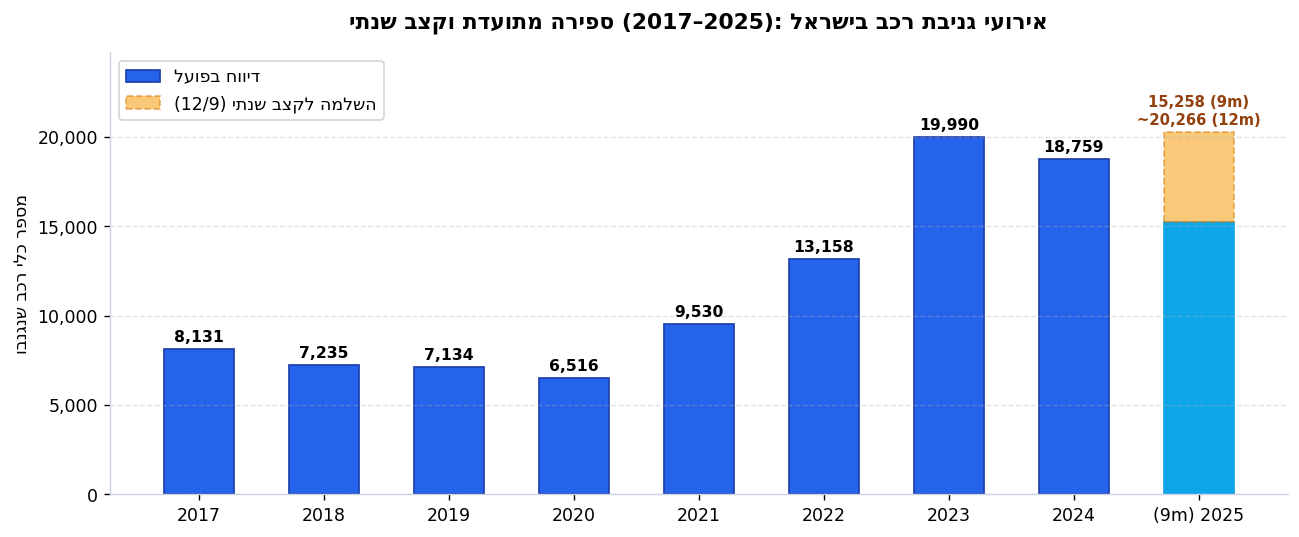

In [39]:
# ==============================================================================
# 4.1 מגמות גניבות ארציות לאורך השנים (2017–2025: 9 חודשים בפועל מול קצב שנתי)
# ==============================================================================

years_cols_eda = ["2017", "2018", "2019", "2020", "2021", "2022", "2023", "2024"]
observed_totals = [float(df_models_engineered[y].sum()) for y in years_cols_eda]
obs_2025_9m = float(df_models_engineered["2025"].sum())
est_2025_12m = float(df_models_engineered["2025_run_rate"].sum())

labels_raw = ["2017", "2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025 (9m)"]
labels_rtl = [reverse_hebrew_text(lbl) for lbl in labels_raw]
vals_obs = observed_totals + [obs_2025_9m]

fig, ax = plt.subplots(figsize=(10.5, 4.4), dpi=125)
bars = ax.bar(labels_rtl, vals_obs, color="#2563eb", width=0.56, edgecolor="#1e40af", label=reverse_hebrew_text("דיווח בפועל"))
bars[-1].set_color("#0ea5e9")

# הצגת תוספת הקצב השנתי (3 חודשים משלימים ל-Run-Rate) כשכבה שקופה מעל עמודת 2025
ax.bar(
    [labels_rtl[-1]],
    [est_2025_12m - obs_2025_9m],
    bottom=[obs_2025_9m],
    color="#f59e0b",
    alpha=0.55,
    width=0.56,
    edgecolor="#d97706",
    linestyle="--",
    label=reverse_hebrew_text("השלמה לקצב שנתי (12/9)"),
)

for b, v in zip(bars[:-1], vals_obs[:-1]):
    ax.text(b.get_x() + b.get_width() / 2, v + 260, f"{int(v):,}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.text(
    bars[-1].get_x() + bars[-1].get_width() / 2,
    est_2025_12m + 260,
    f"{int(obs_2025_9m):,} (9m)\n~{int(est_2025_12m):,} (12m)",
    ha="center",
    va="bottom",
    fontsize=8.5,
    fontweight="bold",
    color="#92400e",
)

ax.set_title(reverse_hebrew_text("אירועי גניבת רכב בישראל (2017–2025): ספירה מתועדת וקצב שנתי"), fontsize=12.5, fontweight="bold", pad=14)
ax.set_ylabel(reverse_hebrew_text("מספר כלי רכב שנגנבו"), fontsize=10)
ax.set_ylim(0, est_2025_12m * 1.22)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


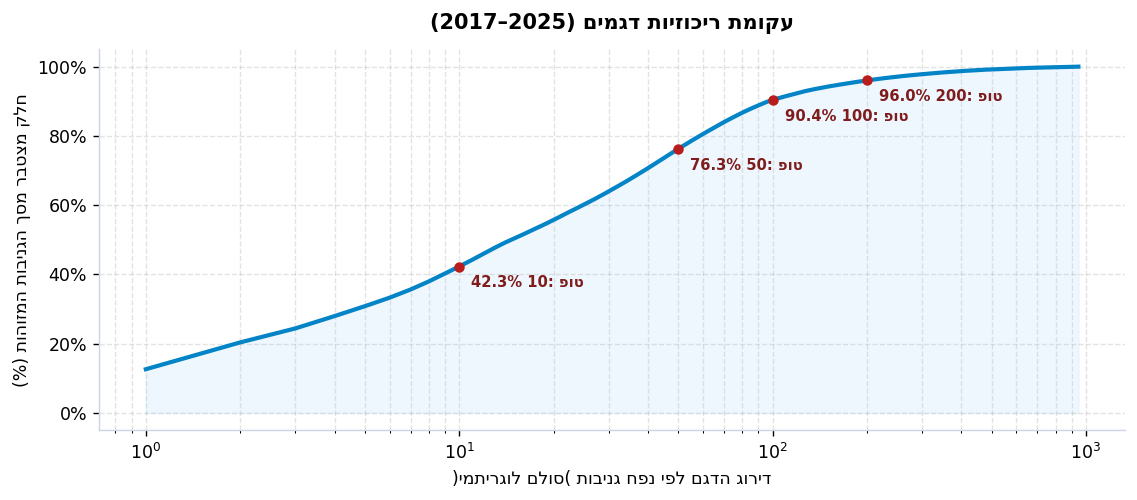

ממצא תיאורי: מתוך 946 דגמים מזוהים, 10 הדגמים המובילים מרכזים 42.3% מהאירועים ו-50 הדגמים הראשונים מרכזים 76.3%.
הערה מתודולוגית: ריכוזיות זו משקפת שילוב של תפוצת הדגמים על הכביש ושל העדפות גניבה; היא אינה מהווה כשלעצמה הוכחה למשקל אופטימלי בנוסחת תמחור ביטוחי.


In [40]:
# ==============================================================================
# 4.2 ריכוזיות דגמים במאגר הגניבות (עקומת פארטו תיאורית)
# ==============================================================================

valid_models_eda = (
    df_models_engineered[
        (~df_models_engineered["model_clean"].isin(["לא מצוין", "דו-גלגלי (ללא תת-דגם)"]))
        & (df_models_engineered["total_thefts_2017_2025"] > 0)
    ]
    .sort_values("total_thefts_2017_2025", ascending=False)
    .reset_index(drop=True)
)

tot_named_thefts = float(valid_models_eda["total_thefts_2017_2025"].sum())
valid_models_eda["cum_pct"] = (valid_models_eda["total_thefts_2017_2025"].cumsum() / tot_named_thefts) * 100.0
ranks = np.arange(1, len(valid_models_eda) + 1)

fig, ax = plt.subplots(figsize=(9.2, 4.1), dpi=125)
ax.plot(ranks, valid_models_eda["cum_pct"], color="#0284c7", linewidth=2.4)
ax.fill_between(ranks, valid_models_eda["cum_pct"], color="#e0f2fe", alpha=0.55)
ax.set_xscale("log")
ax.set_xlabel(reverse_hebrew_text("דירוג הדגם לפי נפח גניבות -סולם לוגריתמי"), fontsize=10)
ax.set_ylabel(reverse_hebrew_text("חלק מצטבר מסך הגניבות המזוהות (%)"), fontsize=10)
ax.set_title(reverse_hebrew_text("עקומת ריכוזיות דגמים (2017–2025)"), fontsize=12, fontweight="bold", pad=12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))

pct_marks = {}
for r in [10, 50, 100, 200]:
    if r <= len(valid_models_eda):
        pct = float(valid_models_eda.loc[r - 1, "cum_pct"])
        pct_marks[r] = pct
        ax.plot(r, pct, "o", color="#b91c1c", markersize=5)
        ax.annotate(
            reverse_hebrew_text(f"טופ {r}: {pct:.1f}%"),
            (r, pct),
            textcoords="offset points",
            xytext=(7, -12),
            fontsize=8.5,
            fontweight="bold",
            color="#7f1d1d",
        )

ax.grid(True, which="both", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

print(
    f"ממצא תיאורי: מתוך {len(valid_models_eda):,} דגמים מזוהים, 10 הדגמים המובילים מרכזים {pct_marks[10]:.1f}% מהאירועים "
    f"ו-50 הדגמים הראשונים מרכזים {pct_marks[50]:.1f}%.\n"
    "הערה מתודולוגית: ריכוזיות זו משקפת שילוב של תפוצת הדגמים על הכביש ושל העדפות גניבה; "
    "היא אינה מהווה כשלעצמה הוכחה למשקל אופטימלי בנוסחת תמחור ביטוחי."
)


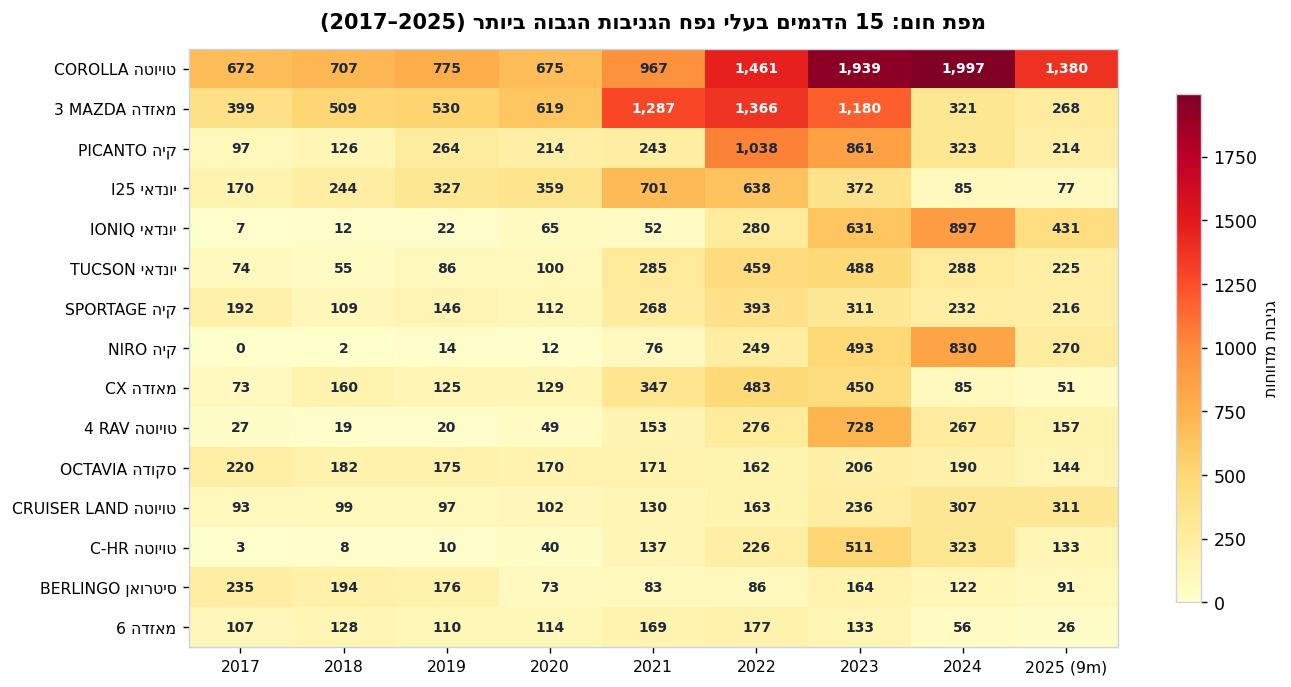

In [17]:
# ==============================================================================
# 4.3 מפת חום של 15 דגמי הרכב המובילים לאורך השנים (2017–2025, ללא דו-גלגלי סאן יאנג)
# ==============================================================================

heat_cols = ["2017", "2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025"]
df_heat = df_models_engineered[
    (~df_models_engineered["model_clean"].isin(["לא מצוין", "דו-גלגלי (ללא תת-דגם)"]))
    & (~df_models_engineered["maker_clean"].isin(["סאן יאנג", "קימקו", "לא מצוין"]))
].copy()
df_heat["sum_obs"] = df_heat[heat_cols].sum(axis=1)
df_heat_top15 = df_heat.nlargest(15, "sum_obs").copy()

heat_matrix = df_heat_top15[heat_cols].values
row_labels = [reverse_hebrew_text(f"{r['maker_clean']} {r['model_clean']}") for _, r in df_heat_top15.iterrows()]
col_labels = ["2017", "2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025 (9m)"]

fig, ax = plt.subplots(figsize=(11, 5.6), dpi=125)
im = ax.imshow(heat_matrix, cmap="YlOrRd", aspect="auto")
ax.set_xticks(np.arange(len(col_labels)))
ax.set_xticklabels(col_labels, fontsize=9)
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=9)

for i in range(heat_matrix.shape[0]):
    for j in range(heat_matrix.shape[1]):
        val = int(heat_matrix[i, j])
        txt_color = "white" if val > heat_matrix.max() * 0.52 else "#1e293b"
        ax.text(j, i, f"{val:,}", ha="center", va="center", fontsize=8, color=txt_color, fontweight="bold")

cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label(reverse_hebrew_text("גניבות מדווחות"), fontsize=9)
ax.set_title(reverse_hebrew_text("מפת חום: 15 הדגמים בעלי נפח הגניבות הגבוה ביותר (2017–2025)"), fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


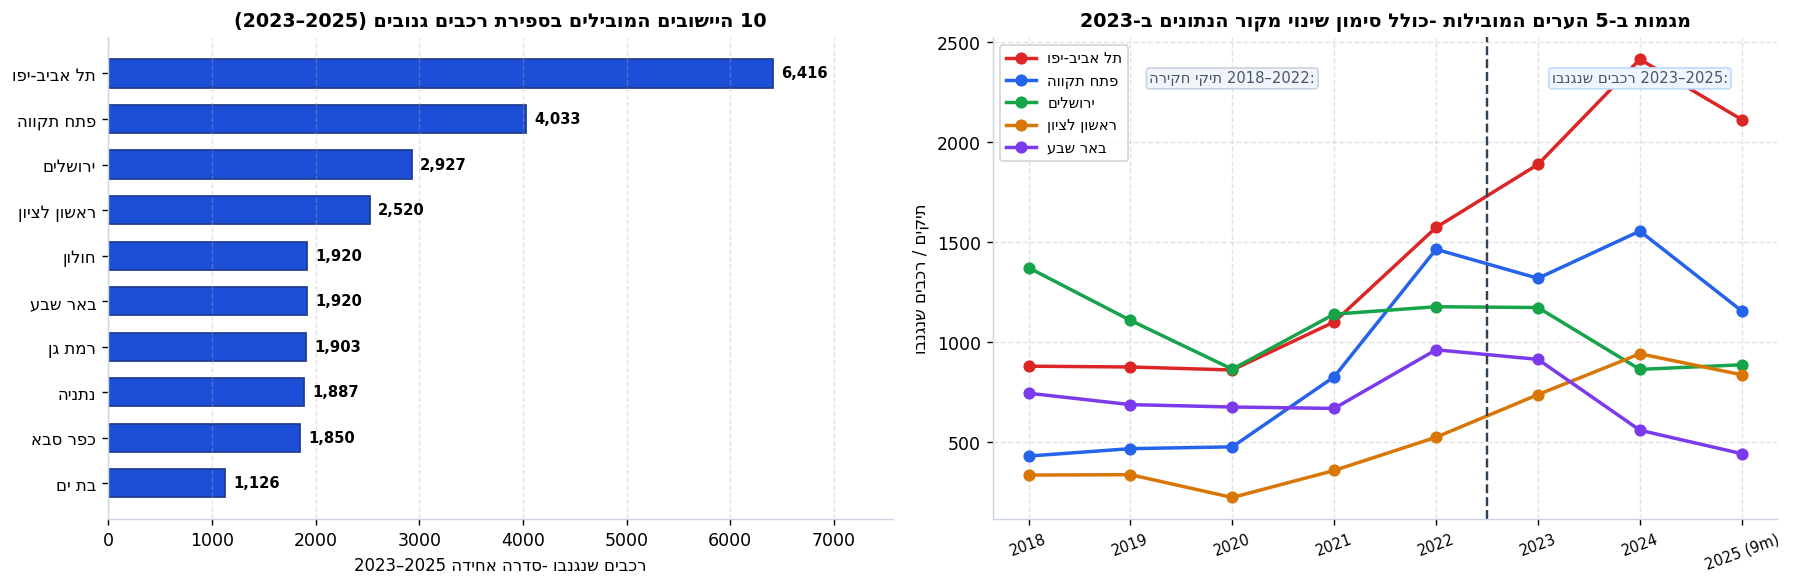

In [42]:
# ==============================================================================
# 4.4 מוקדים מוניציפליים ומגמות ב-5 הערים המובילות ( כולל נקודת מעבר בין מקורות נתונים ב-2023)
# ==============================================================================

city_timeline_cols = ["2018", "2019", "2020", "2021", "2022", "thefts_2023", "2024", "2025"]
city_timeline_labels = ["2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025 (9m)"]

df_cities_eda = df_advanced_cities.copy()
df_cities_eda["recent_3yr_thefts"] = (
    df_cities_eda["thefts_2023"] + df_cities_eda["thefts_2024"] + df_cities_eda["thefts_2025"]
)
top10_recent = df_cities_eda.nlargest(10, "recent_3yr_thefts").sort_values("recent_3yr_thefts", ascending=True)
top5_names = df_cities_eda.nlargest(5, "recent_3yr_thefts")["city_unified"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.8), dpi=125)

# תרשים שמאל: 10 הערים המובילות בסדרה אחידה והומוגנית (יומן כלי הרכב שנגנבו 2023–2025)
y_pos = np.arange(len(top10_recent))
ax1.barh(
    y_pos,
    top10_recent["recent_3yr_thefts"],
    color="#1d4ed8",
    height=0.62,
    edgecolor="#1e3a8a",
)
ax1.set_yticks(y_pos)
ax1.set_yticklabels([reverse_hebrew_text(c) for c in top10_recent["city_unified"]], fontsize=9.5)
for idx_bar, val in enumerate(top10_recent["recent_3yr_thefts"]):
    ax1.text(val + 80, idx_bar, f"{int(val):,}", va="center", fontsize=8.5, fontweight="bold")
ax1.set_xlim(0, float(top10_recent["recent_3yr_thefts"].max()) * 1.18)
ax1.set_title(reverse_hebrew_text("10 היישובים המובילים בספירת רכבים גנובים (2023–2025)"), fontsize=11, fontweight="bold")
ax1.set_xlabel(reverse_hebrew_text("רכבים שנגנבו -סדרה אחידה 2023–2025"), fontsize=9.5)
ax1.grid(axis="x", linestyle="--", alpha=0.35)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# תרשים ימין: ציר זמן 2018–2025 עבור 5 הערים המובילות עם קו הפרדה מפורש במעבר המקור ב-2023
palette_5 = ["#dc2626", "#2563eb", "#16a34a", "#d97706", "#7c3aed"]
x_idx = np.arange(len(city_timeline_cols))
for c_name, col_hex in zip(top5_names, palette_5):
    row_c = df_cities_eda[df_cities_eda["city_unified"] == c_name].iloc[0]
    y_vals = [float(row_c[col]) for col in city_timeline_cols]
    ax2.plot(x_idx, y_vals, marker="o", linewidth=2.0, color=col_hex, label=reverse_hebrew_text(c_name))

ax2.axvline(x=4.5, color="#334155", linestyle="--", linewidth=1.4)
ax2.text(2.0, ax2.get_ylim()[1] * 0.91, reverse_hebrew_text("2018–2022: תיקי חקירה"), ha="center", fontsize=8.5, color="#475569", bbox=dict(boxstyle="round,pad=0.2", fc="#f1f5f9", ec="#cbd5e1"))
ax2.text(6.0, ax2.get_ylim()[1] * 0.91, reverse_hebrew_text("2023–2025: רכבים שנגנבו"), ha="center", fontsize=8.5, color="#475569", bbox=dict(boxstyle="round,pad=0.2", fc="#eff6ff", ec="#bfdbfe"))

ax2.set_xticks(x_idx)
ax2.set_xticklabels(city_timeline_labels, rotation=20, fontsize=8.5)
ax2.set_title(reverse_hebrew_text("מגמות ב-5 הערים המובילות -כולל סימון שינוי מקור הנתונים ב-3202"), fontsize=11, fontweight="bold")
ax2.set_ylabel(reverse_hebrew_text("תיקים / רכבים שנגנבו"), fontsize=9.5)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()


In [19]:
# ==============================================================================
# 4.5 הקשר התצפיתי בין נפח תיקים היסטורי לשיעור גילוי חשודים  2018–2022) - אינטראקטיבי
# ==============================================================================
import plotly.express as px
import plotly.graph_objects as go

# שימוש בסדרת 2018–2022 ההומוגנית בלבד כך שהמונה (חשודים) והמכנה (תיקים שנפתחו) מגיעים מאותו מקור בדיוק
df_enf_plot = city_hist_enforcement[city_hist_enforcement["city_hist_cases_2018_2022"] >= 25].copy()

# הכנת נתונים לתצוגה
df_enf_plot["עיר"] = df_enf_plot["city_unified"]
df_enf_plot["תיקים שנפתחו"] = df_enf_plot["city_hist_cases_2018_2022"]
df_enf_plot["שיעור גילוי (%)"] = (df_enf_plot["city_detection_rate" ] * 100.0).round(2)
df_enf_plot["שיעור סגירה בעילת עלן (%)"] = (df_enf_plot["city_unsolved_rate" ] * 100.0).round(2)
df_enf_plot["גודל סמן (בועה)"] = np.clip(df_enf_plot["city_hist_cases_2018_2022"] / 1.5, 8, 80)

fig = px.scatter(
    df_enf_plot,
    x="תיקים שנפתחו",
    y="שיעור גילוי (%)",
    size="גודל סמן (בועה)",
    color="שיעור סגירה בעילת עלן (%)",
    hover_name="עיר",
    hover_data={
        "תיקים שנפתחו": ":,d",
        "שיעור גילוי (%)": ":.2f%",
        "שיעור סגירה בעילת עלן (%)": ":.2f%",
        "גודל סמן (בועה)": False
    },
    log_x=True,
    color_continuous_scale="Viridis_r",
    title="נפח תיקי חקירה מול שיעור גילוי חשודים ביישובים (2018–2022)"
)

fig.update_layout(
    xaxis_title="סך תיקי גניבת רכב שנפתחו ביישוב (סולם לוגריתמי)",
    yaxis_title="שיעור תיקים עם חשוד מזוהה (%)",
    coloraxis_colorbar=dict(
        title="שיעור על\"ן (%)"
    ),
    title_x=0.5,
    template="plotly_white",
    height=500
)

fig.show()

rho_enf, _ = spearmanr(df_enf_plot["city_hist_cases_2018_2022"], df_enf_plot["city_detection_rate"])
print(
    f"מתאם דירוג תיאורי (2018–2022, n={len(df_enf_plot)} יישובים): Spearman rho = {rho_enf:.3f}.\n"
    "בערים הגדולות שיעור התיקים עם חשוד מזוהה נע לרוב סביב 7%–13%, בעוד שביישובים קטנים קיימת שונות גבוהה עקב גודל מדגם מצומצם."
)

מתאם דירוג תיאורי (2018–2022, n=160 יישובים): Spearman rho = 0.178.
בערים הגדולות שיעור התיקים עם חשוד מזוהה נע לרוב סביב 7%–13%, בעוד שביישובים קטנים קיימת שונות גבוהה עקב גודל מדגם מצומצם.


# 4.8 ניתוח GIS מרחבי רציף: השפעת הקרבה לצירי מילוט ראשיים

**הסבר הניתוח והמתודולוגיה:**
במסגרת הניתוח המרחבי, חישבנו את המרחק האווירי המינימלי (בקילומטרים) של כל יישוב משני עורקי התחבורה המרכזיים במדינה: **כביש 1** (ציר מזרח-מערב מהיר) ו-**כביש 6** (ציר האורך המהיר הראשי). מטרת הניתוח היא לבחון את השערת "צירי המילוט" – לפיה קרבה גיאוגרפית לתשתיות כבישים מהירות מאפשרת לעבריינים להעביר רכבים גנובים במהירות לשטחי הרשות הפלסטינית, ובכך מקטינה את סיכויי הפענוח ומגדילה את נפח הגניבות ביישובים אלו.

**כיצד לקרוא את הגרף האינטראקטיבי הבא?**
* **ציר ה-X (מרחק מהכביש):** ככל שנעים שמאלה, היישוב קרוב יותר פיזית לכביש 1 או כביש 6.
* **ציר ה-Y (מספר גניבות ב-2024):** מייצג את היקף הפשיעה המוחלט בפועל.
* **גודל הבועה (שיעור תיקי על"ן %):** מייצג את אחוז התיקים שנסגרו ללא גילוי חשוד ("עבריין לא נודע"). בועות גדולות יותר מצביעות על קושי מוגבר בפענוח ואכיפה.
* **צבע הבועה:** נע על סולם רציף מגוונים חמים (אדום/כתום) עבור יישובים הסמוכים מאוד לצירים, ועד גוונים קרים (כחול) עבור יישובים מרוחקים.

**תובנות מרכזיות:**
ניתן לראות בבירור ריכוז פשיעה משמעותי מאוד ביישובים השוכנים בטווח של פחות מ-25 ק"מ מצירי הרוחב והאורך הללו (לדוגמה: פתח תקווה, ראשון לציון ותל אביב-יפו) המאופיינים בנפח פשיעה גבוה במיוחד לצד שיעורי על"ן קרובים ל-95%-97%, דבר המחזק את ההשערה שלנגישות התחבורתית תפקיד מפתח בדינמיקת הגניבות.


In [20]:
# ==============================================================================
# 4.9 תרשים GIS אינטראקטיבי: קשר מרחק רציף מצירים ראשיים לעומת נפח גניבות
# ==============================================================================
import plotly.graph_objects as go
import plotly.express as px

# נתוני מרחק אווירי מינימלי (בק"מ) מכביש 1 ומכביש 6 עבור 15 המוקדים העירוניים המרכזיים
gis_corridor_data = [
    {"city": "כפר סבא", "min_dist_km": 6.94, "thefts_2024": 682, "unsolved_pct": 96.32},
    {"city": "טייבה", "min_dist_km": 9.53, "thefts_2024": 41, "unsolved_pct": 97.57},
    {"city": "קלנסווה", "min_dist_km": 12.56, "thefts_2024": 28, "unsolved_pct": 97.14},
    {"city": "פתח תקווה", "min_dist_km": 13.87, "thefts_2024": 1556, "unsolved_pct": 96.45},
    {"city": "רמלה", "min_dist_km": 16.58, "thefts_2024": 273, "unsolved_pct": 97.70},
    {"city": "לוד", "min_dist_km": 17.08, "thefts_2024": 152, "unsolved_pct": 96.55},
    {"city": "רחובות", "min_dist_km": 17.96, "thefts_2024": 417, "unsolved_pct": 96.86},
    {"city": "נתניה", "min_dist_km": 19.77, "thefts_2024": 628, "unsolved_pct": 98.21},
    {"city": "גבעתיים", "min_dist_km": 19.78, "thefts_2024": 234, "unsolved_pct": 95.43},
    {"city": "תל אביב-יפו", "min_dist_km": 21.55, "thefts_2024": 2414, "unsolved_pct": 95.73},
    {"city": "ירושלים", "min_dist_km": 22.87, "thefts_2024": 865, "unsolved_pct": 92.82},
    {"city": "ראשון לציון", "min_dist_km": 24.79, "thefts_2024": 943, "unsolved_pct": 97.42},
    {"city": "חולון", "min_dist_km": 25.86, "thefts_2024": 699, "unsolved_pct": 94.28},
    {"city": "באר שבע", "min_dist_km": 65.08, "thefts_2024": 561, "unsolved_pct": 95.12},
    {"city": "חיפה", "min_dist_km": 68.22, "thefts_2024": 246, "unsolved_pct": 98.05},
]
df_gis = pd.DataFrame(gis_corridor_data)

# הכנת הנתונים למבנה אינטראקטיבי תואם RTL
df_gis_interactive = df_gis.copy()
df_gis_interactive["עיר"] = df_gis_interactive["city"]
df_gis_interactive["מרחק מהכביש (ק\"מ)"] = df_gis_interactive["min_dist_km"].round(2)
df_gis_interactive["גניבות ב-2024"] = df_gis_interactive["thefts_2024"].astype(int)
df_gis_interactive["תיקים לא מפוענחים (על\"ן %)"] = df_gis_interactive["unsolved_pct"].round(2)

# יצירת מפת הבועות האינטראקטיבית
fig = px.scatter(
    df_gis_interactive,
    x="מרחק מהכביש (ק\"מ)",
    y="גניבות ב-2024",
    size="תיקים לא מפוענחים (על\"ן %)",
    color="מרחק מהכביש (ק\"מ)",
    hover_name="עיר",
    hover_data={
        "מרחק מהכביש (ק\"מ)": ":.2f ק\"מ",
        "גניבות ב-2024": ":,d",
        "תיקים לא מפוענחים (על\"ן %)": ":.2f%"
    },
    color_continuous_scale="RdYlBu_r",
    title="ניתוח GIS מרחבי רציף: קרבה לכבישים 1 ו-6 לעומת נפח גניבות"
)

fig.update_layout(
    xaxis_title="מרחק אווירי מינימלי מהכביש הראשי (ק\"מ)",
    yaxis_title="מספר גניבות רכב בשנת 2024",
    coloraxis_colorbar=dict(
        title="מרחק (ק\"מ)"
    ),
    title_x=0.5,
    template="plotly_white",
    height=520,
    margin=dict(l=50, r=50, t=80, b=50)
)

fig.show()

print(
    """
תובנות מרכזיות:
ניתן לראות בבירור ריכוז פשיעה משמעותי מאוד ביישובים השוכנים בטווח של פחות מ-25 ק"מ
מצירי הרוחב והאורך הללו (לדוגמה: פתח תקווה, ראשון לציון ותל אביב-יפו)
המאופיינים בנפח פשיעה גבוה במיוחד לצד שיעורי על"ן קרובים ל-95%-97%,
דבר המחזק את ההשערה שלנגישות התחבורתית תפקיד מפתח בדינמיקת הגניבות.
"""
)


תובנות מרכזיות:
ניתן לראות בבירור ריכוז פשיעה משמעותי מאוד ביישובים השוכנים בטווח של פחות מ-25 ק"מ
מצירי הרוחב והאורך הללו (לדוגמה: פתח תקווה, ראשון לציון ותל אביב-יפו)
המאופיינים בנפח פשיעה גבוה במיוחד לצד שיעורי על"ן קרובים ל-95%-97%,
דבר המחזק את ההשערה שלנגישות התחבורתית תפקיד מפתח בדינמיקת הגניבות.



## 5. רזולוציה עתית ופרוטוקול התאמת חשיפה (Temporal Resolution & Exposure Offset)

### 5.1 מדוע לא מבוצע קידוד עונתי חודשי (`Sin/Cos`)?
בחינת קבצי הגלם של משטרת ישראל מעלה כי יומן הדגמים והערים (`stolen_cars_models_2023_2025_FULL.csv`) מפורסם **ברזולוציה שנתית בלבד**, ללא חותמת תאריך או חודש ברמת האירוע. גזירת עונתיות חודשית דורשת נתונים תוך-שנתיים אמיתיים; יצירת פירוק חודשי מלאכותי תזריק הנחות סינתטיות, ולכן המחקר פועל ברזולוציה שנתית טהורה.

### 5.2 יישור מתמטי בין שנת 2024 (12 חודשים) לשנת 2025 (9 חודשים)
בנתוני המקור קיים פער מובנה באורך תקופת התצפית:
* **פאנל האימון (`target_year = 2024`):** מכסה שנה קלנדרית מלאה בת **12 חודשים** ($\text{exposure}_{2024} = 1.0$).
* **פאנל המבחן (`target_year = 2025`):** מכסה **9 חודשים בלבד** (ינואר–ספטמבר 2025, $\text{exposure}_{2025} = 9/12 = 0.75$).

אילו היינו משווים ישירות תחזית של מודל שאומן על 12 חודשים מול ספירת אמת של 9 חודשים, כל מודל מכויל היה סופג קנס שיטתי של כ-$+33\%$ בתחזית (ומעניק יתרון מלאכותי למודל חציון שחוזה תמיד `0`). מנגד, הכפלת `y_test` ב-$12/9$ הייתה משנה באופן מלאכותי את משתנה המטרה הבדיד.

הפתרון התקני במודלי ספירה פואסוניים עם פונקציית קישור לוגריתמית הוא **Poisson Exposure Offset**:
$$Y_i \sim \text{Poisson}(\mu_i), \qquad \log(\mu_i) = \log(\text{exposure}_i) + f(X_i) \implies \mu_{i, 9\text{m}} = 0.75 \cdot \exp\bigl(f(X_i)\bigr)$$

בפרוטוקול ההערכה בפרקים 10–11 אנו:
1. שומרים על וקטור האמת `y_test = thefts_2025` **ללא כל שינוי**.
2. מעבירים למודל `XGBoost Poisson` את היסט החשיפה `base_margin = np.log(0.75)` בעת חיזוי 9 החודשים של 2025 (ומכפילים ב-$0.75$ את תחזית הקצב השנתי של שאר מודלי הספירה).
3. מציגים בשקיפות מלאה **גם** את טבלת המדדים ללא התאמת חשיפה, ומציינים בפרק המגבלות כי היסט של $9/12$ מניח קצב גניבות תוך-שנתי אחיד בהיעדר נתונים חודשיים.


> **הבהרה מתודולוגית לגבי Exposure:** בהיעדר נתונים חודשיים במקור הפתוח של משטרת ישראל, שנת 2025 מיוצגת כתקופת חשיפה של $9/12 = 0.75$. התאמה זו משקפת יישור של אורך תקופת התצפית בלבד, ואינה מהווה הנחה אמפירית לכך ש-75% מאירועי הגניבה השנתיים מתרחשים דווקא עד סוף ספטמבר.

## 6. בניית פאנל כרונולוגי סימטרי ללא בחירת אוכלוסייה מהעתיד (Leakage-Free Cohort)

### 6.1 הבעיה המתודולוגית בבניית פאנל מתוך טבלה רב-שנתית מאוחדת
קובץ המשטרה `stolen_cars_models_2023_2025_FULL.csv` כולל שורה רק אם התרחש בה לפחות אירוע גניבה או מציאה אחד בין 2023 ל-2025. אילו היינו משתמשים בכלל השורות בקובץ כבסיס קבוע לאימון ולמבחן, היו נוצרים שני עיוותים של הצצה לעתיד (`Lookahead Selection Bias`):
1. **הטיית הישרדות במבחן 2025:** אלפי צירופים עם `0` אירועים ב-2023 וב-2024 מופיעים בקובץ **אך ורק מפני שנגנבו ב-2025** ($P(Y_{2025} \ge 1 \mid \text{in file}, Y_{2023}=0, Y_{2024}=0) = 1$).
2. **שנתוני עתיד באימון 2024:** רכבים משנתון ייצור `model_year = 2025` היו נכנסים לפאנל האימון של שנת 2024 כרשומות אפס עוד לפני שעלו לכביש.

### 6.2 פרוטוקול הקוהורט הסימטרי (`build_symmetric_panel_asof`)
כדי להבטיח אפס הצצה לשנת היעד, אנו מגדירים לכל שנת חיזוי $T \in \{2024, 2025\}$ את אוכלוסיית המעקב **אך ורק מתוך המידע שהיה גלוי בסוף שנת הפיגור $T-1$**:
1. **סינון שנתוני ייצור חוקיים במועד החיתוך:** נכללים רק רכבים עם `model_year <= T - 1` (`<= 2023` לאימון 2024; `<= 2024` למבחן 2025).
2. **צירופים פעילים ב-$T-1$:** כל צירוף `(maker_clean, model_clean, model_year, city_unified)` שתועד במשטרה בשנת $T-1$ (`thefts_{T-1} + found_{T-1} > 0`).
3. **רשת מועמדים סימטרית טרום-חיתוך (לכיסוי תאי `lag_1_thefts == 0` ללא זליגה):** מכפלה קרטזית של 120 פרופילי הרכב-שנתון הנגנבים ביותר בשנת $T-1$ ב-80 הערים המובילות בשנת $T-1$. צירופים ברשת זו שלא נגנבו ב-$T-1$ מקבלים `lag_1_thefts = 0` אמיתי, וערך המטרה שלהם ב-$T$ (`0` או חיובי) נשלף מנתוני האמת של שנה $T$ ללא כל הטיית בחירה.
4. **בדיקת רגישות משלימה:** בפרק 10 נבדוק גם את הקוהורט המצומצם של צירופים פעילים בלבד ב-$T-1$ (`Active-Only Cohort`, ללא רשת המועמדים) כדי לוודא שמסקנות ההשוואה בין המודלים אינן תלויות ברשת האפסים.


In [21]:
# ==============================================================================
# 6.1 בניית פאנל אימון (2023 -> 2024) ופאנל מבחן עיוור (2024 -> 2025) ללא זליגת אוכלוסייה
# ==============================================================================

def build_symmetric_panel_asof(target_year: int, include_candidate_grid: bool = True) -> pd.DataFrame:
    """
    בונה פאנל כרונולוגי נכון לסוף שנת (target_year - 1) ללא שום שימוש במידע משנת target_year ואילך.
    """
    lag_year = target_year - 1
    lag_thefts_col = f"thefts_{lag_year}"
    lag_found_col = f"found_{lag_year}"
    target_col = f"thefts_{target_year}"
    key_cols = ["maker_clean", "model_clean", "model_year", "city_unified"]

    # אוכלוסיית רשומות עם שנתון ייצור שכבר היה קיים בשנת הפיגור
    eligible = df_panel_universe[df_panel_universe["model_year"] <= lag_year].copy()

    # 1. צירופים שנצפו בפועל ביומן המשטרה בשנת הפיגור (T-1)
    active_in_lag = eligible[(eligible[lag_thefts_col] + eligible[lag_found_col]) > 0].copy()

    if include_candidate_grid:
        # 2. רשת מועמדים ידועה-מראש (נבנית מנתוני T-1 בלבד): 120 פרופילי רכב-שנתון מובילים × 80 ערים מובילות ב-(T-1)
        top_profiles = (
            active_in_lag[
                (active_in_lag["maker_clean"] != "לא מצוין")
                & (active_in_lag["model_clean"] != "לא מצוין")
            ]
            .groupby(["vehicle_type", "maker_clean", "model_clean", "model_year"], as_index=False)[lag_thefts_col]
            .sum()
            .nlargest(120, lag_thefts_col)[["vehicle_type", "maker_clean", "model_clean", "model_year"]]
        )
        top_cities = (
            active_in_lag.groupby("city_unified", as_index=False)[lag_thefts_col]
            .sum()
            .nlargest(80, lag_thefts_col)[["city_unified"]]
        )
        candidate_grid = top_profiles.merge(top_cities, how="cross")
        cohort_keys = pd.concat(
            [active_in_lag[["vehicle_type"] + key_cols], candidate_grid[["vehicle_type"] + key_cols]],
            ignore_index=True,
        ).drop_duplicates(subset=key_cols, keep="first")
    else:
        cohort_keys = active_in_lag[["vehicle_type"] + key_cols].drop_duplicates(subset=key_cols, keep="first")

    # צירוף ספירת הפיגור וספירת היעד האמיתית (תא שלא הופיע בטבלת המשטרה בשנה נתונה חווה 0 גניבות)
    panel = pd.merge(
        cohort_keys,
        eligible[key_cols + [lag_thefts_col, target_col]],
        on=key_cols,
        how="left",
    )
    panel["lag_1_thefts"] = panel[lag_thefts_col].fillna(0.0)
    panel["next_year_thefts"] = panel[target_col].fillna(0.0)
    panel["lag_year"] = lag_year
    panel["target_year"] = target_year
    panel["exposure_years"] = 0.75 if target_year == 2025 else 1.0

    # מיזוג מאפייני עיר הנכונים למועד החיתוך (ללא זליגה משנת היעד)
    city_feats = build_city_features_asof(target_year)
    panel = pd.merge(panel, city_feats, on="city_unified", how="left")
    panel["city_lag_1_thefts"] = panel["city_lag_1_thefts"].fillna(0.0)
    panel["city_detection_rate"] = panel["city_detection_rate"].fillna(float(city_feats["city_detection_rate"].median()))
    panel["city_unsolved_rate"] = panel["city_unsolved_rate"].fillna(float(city_feats["city_unsolved_rate"].median()))
    return panel.reset_index(drop=True)


train_panel = build_symmetric_panel_asof(2024, include_candidate_grid=True)
test_panel = build_symmetric_panel_asof(2025, include_candidate_grid=True)

# קוהורט פעילים-בלבד לבדיקת רגישות בפרק 10
train_active_only = build_symmetric_panel_asof(2024, include_candidate_grid=False)
test_active_only = build_symmetric_panel_asof(2025, include_candidate_grid=False)

cohort_summary_df = pd.DataFrame([
    {
        "פאנל": "Train 2024 (חיתוך סוף 2023)",
        "מספר רשומות": len(train_panel),
        "חשיפה (שנים)": 1.00,
        "שיעור lag_1 == 0": f"{(train_panel['lag_1_thefts'] == 0).mean():.1%}",
        "שיעור יעד == 0": f"{(train_panel['next_year_thefts'] == 0).mean():.1%}",
        "ממוצע יעד לתצפית": round(float(train_panel["next_year_thefts"].mean()), 4),
        "קצב שנתי ממוצע (מותאם חשיפה)": round(float(train_panel["next_year_thefts"].mean() / 1.0), 4),
        "סך גניבות יעד בקוהורט": int(train_panel["next_year_thefts"].sum()),
    },
    {
        "פאנל": "Test 2025 (חיתוך סוף 2024, 9 חודשים)",
        "מספר רשומות": len(test_panel),
        "חשיפה (שנים)": 0.75,
        "שיעור lag_1 == 0": f"{(test_panel['lag_1_thefts'] == 0).mean():.1%}",
        "שיעור יעד == 0": f"{(test_panel['next_year_thefts'] == 0).mean():.1%}",
        "ממוצע יעד לתצפית": round(float(test_panel["next_year_thefts"].mean()), 4),
        "קצב שנתי ממוצע (מותאם חשיפה)": round(float(test_panel["next_year_thefts"].mean() / 0.75), 4),
        "סך גניבות יעד בקוהורט": int(test_panel["next_year_thefts"].sum()),
    },
])

print("סיכום מאפייני הפאנלים הכרונולוגיים (לאחר ניטרול בחירת אוכלוסייה מהעתיד):")
display(cohort_summary_df)


סיכום מאפייני הפאנלים הכרונולוגיים (לאחר ניטרול בחירת אוכלוסייה מהעתיד):


,פאנל,מספר רשומות,חשיפה (שנים),שיעור lag_1 == 0,שיעור יעד == 0,ממוצע יעד לתצפית,קצב שנתי ממוצע (מותאם חשיפה),סך גניבות יעד בקוהורט
0,Train 2024 (חיתוך סוף 2023),17389,1.00,39.9%,82.7%,0.4813,0.4813,8369
1,"Test 2025 (חיתוך סוף 2024, 9 חודשים)",16853,0.75,42.5%,83.8%,0.3802,0.5070,6408


## 7. ביקורת מאפיינים ומניעת זליגת מידע (Feature Audit & Temporal Assertions)

טבלת המאפיינים להלן מתעדת התאמה מלאה (`1:1`) בין ההגדרה המתודולוגית לבין הרשימה `FEATURES` בקוד:

| שם העמודה | מהות וחישוב | טווח זמן באימון (2024) | טווח זמן במבחן (2025) | נכלל ב-`FEATURES`? |
|---|---|---|---|---|
| `model_year` | שנת ייצור כלי הרכב (`<= lag_year`) | `<= 2023` | `<= 2024` | **כן** |
| `lag_1_thefts` | ספירת גניבות של אותו צירוף רכב-עיר בשנה הקודמת | `2023` | `2024` | **כן** |
| `city_lag_1_thefts` | סך גניבות הרכב בעיר בשנה הקודמת בלבד | `2023` | `2024` | **כן** |
| `city_detection_rate` | שיעור תיקים עם חשוד מזוהה בעיר בהיסטוריה טרום-מידול | `2018–2022` | `2018–2022` | **כן** |
| `city_unsolved_rate` | שיעור תיקים שנסגרו בעילת על"ן בעיר בהיסטוריה טרום-מידול | `2018–2022` | `2018–2022` | **כן** |
| `exposure_years` | אורך תקופת החשיפה בשנים (`1.0` מול `0.75`) | `12/12 = 1.0` | `9/12 = 0.75` | **Offset חשיפה** |
| `next_year_thefts` | ספירת גניבות בפועל בשנת היעד | `2024` | `2025` (9 חודשים) | **יעד מסלול א'** |
| `continuous_risk_target` | טרנספורמציה לוגריתמית `0–100` (מנורמלת לפי מקסימום **אימון 2024 בלבד**) | `2024` | `2025` (נגזר מתקרת אימון) | **יעד מסלול ב'** |
| `composite_theft_score` / `proximity_to_corridors` / `population_clean` | ציון היוריסטי מוצרי / תיוג איכותני / אוכלוסייה | — | — | **לא נכללים במודל** |


> **הבהרה לגבי עומק הפיגור (Lag Horizon):** מאחר שקובץ העלים המוניציפלי המפורט (`דגם × שנתון × עיר`) קיים במשטרת ישראל החל משנת 2023 בלבד (לפני 2023 קיימים סיכומים ארציים בלבד לדגמים או תיקים עירוניים ללא פירוט דגם), לא ניתן לגזור `lag_2_thefts` או ממוצעים נעים רב-שנתיים ברמת תא מבלי להזריק זליגת מידע או נתונים סינתטיים.

In [22]:
# ==============================================================================
# 7.1 הכנת מטריצות החיזוי, הגדרת יעד מסלול ב' (ללא זליגת מבחן) ואסרטציות זליגה מהותיות
# ==============================================================================

FEATURES = [
    "model_year",
    "lag_1_thefts",
    "city_lag_1_thefts",
    "city_detection_rate",
    "city_unsolved_rate",
]
TARGET = "next_year_thefts"

FORBIDDEN_FEATURES = {
    "target", "next_year_thefts", "continuous_risk_target", "composite_theft_score",
    "model_risk_score", "city_risk_score", "total_thefts", "thefts_2024", "thefts_2025",
    "2025_run_rate", "proximity_to_corridors", "population_clean", "city_cases_total",
}
assert not FORBIDDEN_FEATURES.intersection(FEATURES), "נמצא מאפיין אסור בתוך FEATURES!"

# הגדרת יעד מסלול ב' (Track 2 Continuous 0-100) במקום אחד בלבד, לפי המקסימום של סט האימון (2024) בלבד!
# הערה: מאחר ש-2025 נמדדה על פני 9 חודשים (0.75 שנה), מנרמלים את קצב היעד ליחידת זמן שנתית זהה לאימון
# באמצעות תקרת האימון בלבד + חיתוך clip(0, 100) כדי שאף ערך ממבחן 2025 לא ישפיע על סולם האימון.
TRAIN_MAX_LOG = float(np.log1p(train_panel["next_year_thefts"].max()))
assert TRAIN_MAX_LOG > 0

train_panel["continuous_risk_target"] = (
    np.log1p(train_panel["next_year_thefts"] / train_panel["exposure_years"]) / TRAIN_MAX_LOG * 100.0
).clip(0.0, 100.0)
test_panel["continuous_risk_target"] = (
    np.log1p(test_panel["next_year_thefts"] / test_panel["exposure_years"]) / TRAIN_MAX_LOG * 100.0
).clip(0.0, 100.0)

X_train = train_panel[FEATURES].copy()
y_train = train_panel[TARGET].copy()
exp_train = train_panel["exposure_years"].values

X_test = test_panel[FEATURES].copy()
y_test = test_panel[TARGET].copy()
exp_test = test_panel["exposure_years"].values

# אסרטציות זליגה מהותיות ברמת הנתונים (מעבר לבדיקת שמות העמודות)
assert int(train_panel["model_year"].max()) <= 2023, "זליגת שנתון עתידי בפאנל אימון 2024!"
assert int(test_panel["model_year"].max()) <= 2024, "זליגת שנתון 2025 בפאנל מבחן 2025!"
assert not X_train.isna().any().any() and not X_test.isna().any().any(), "ערכי NaN במטריצות הפיצ'רים!"

# בדיקה ש-city_lag_1_thefts באימון שווה בדיוק לסכום 2023 בעיר ואינו כולל את 2024/2025
expected_ta_2023 = float(df_panel_universe.loc[(df_panel_universe["city_unified"] == "תל אביב-יפו") & (df_panel_universe["model_year"] <= 2023), "thefts_2023"].sum())
expected_ta_2024 = float(df_panel_universe.loc[(df_panel_universe["city_unified"] == "תל אביב-יפו") & (df_panel_universe["model_year"] <= 2024), "thefts_2024"].sum())
actual_ta_train = float(train_panel.loc[train_panel["city_unified"] == "תל אביב-יפו", "city_lag_1_thefts"].iloc[0])
actual_ta_test = float(test_panel.loc[test_panel["city_unified"] == "תל אביב-יפו", "city_lag_1_thefts"].iloc[0])
assert np.isclose(actual_ta_train, expected_ta_2023), "city_lag_1_thefts באימון אינו תואם לסכום 2023!"
assert np.isclose(actual_ta_test, expected_ta_2024), "city_lag_1_thefts במבחן אינו תואם לסכום 2024!"
assert actual_ta_train != actual_ta_test, "מאפיין הנפח העירוני חייב להתעדכן דינמית בין 2023 ל-2024!"

print("ביקורת אי-זליגה (ברמת סכמה וברמת ערכי הנתונים) עברה בהצלחה מלאה.")
print(f"   • X_train: {X_train.shape} | y_train: {y_train.shape} | תקרת אימון לוגריתמית: {TRAIN_MAX_LOG:.4f}")
print(f"   • X_test:  {X_test.shape} | y_test:  {y_test.shape} | city_lag_1_thefts תל אביב: 2023={int(actual_ta_train):,}, 2024={int(actual_ta_test):,}")


ביקורת אי-זליגה (ברמת סכמה וברמת ערכי הנתונים) עברה בהצלחה מלאה.
   • X_train: (17389, 5) | y_train: (17389,) | תקרת אימון לוגריתמית: 4.2485
   • X_test:  (16853, 5) | y_test:  (16853,) | city_lag_1_thefts תל אביב: 2023=1,886, 2024=2,397


## 8. אבחון התפלגות נתוני הספירה (Count Diagnostics)

לפני בחירת פונקציית ההפסד, נבדוק את תכונותיו הסטטיסטיות של משתנה המטרה בפאנל האימון (`y_train`):
1. **שיעור אפסים (`Zero-Share`):** רוב צירופי הרכב-שנתון-עיר חווים 0 גניבות בשנה נתונה.
2. **פיזור-יתר (`Overdispersion`):** בדיקה האם $\text{Var}(Y) \gg \mathbb{E}[Y]$, מצב שבו הנחת השונות השווה לתוחלת ברגרסיה ליניארית רגילה מופרת בחריפות ומוקדי הקצה מושכים את השגיאה הריבועית.


אבחון נתוני ספירה על פאנל האימון (2024):
   • תוחלת E[Y]:                    0.4813
   • שונות Var(Y):                  3.7877
   • יחס פיזור (Var / Mean):        7.87x (פיזור-יתר מובהק)
   • שיעור תצפיות אפס (Y = 0):      82.7%
   • שיעור גניבה בודדת (Y = 1):     9.3%
   • שיעור מוקדים כבדים (Y >= 10):  0.84% (146 צירופים)


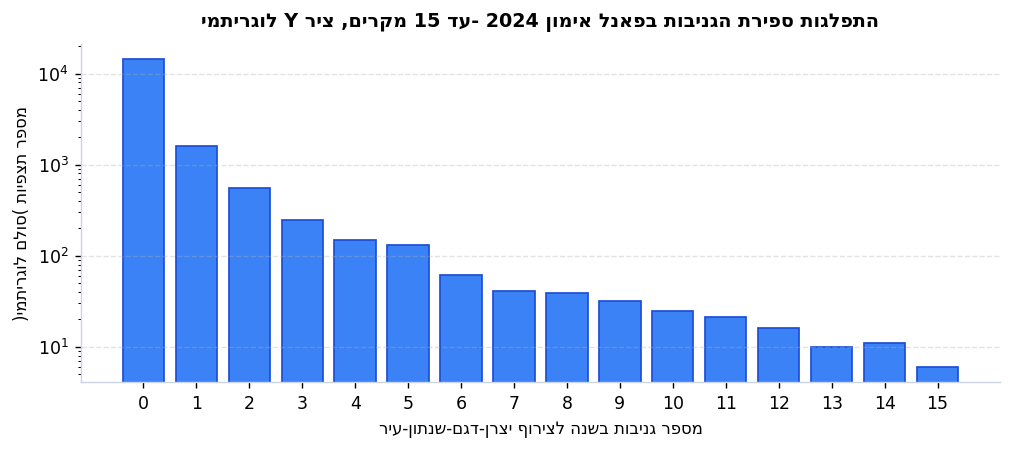

=== אבחון התפלגות נתוני הספירה (קוהורט אימון 2024) ===
1. שלטון מוחלט של אפסים (ריבוי אפסים / Zero-Heavy Target): כ-82.7% מצירופי הרכב-עיר חווים 0 גניבות בשנה, מה שמדגיש חוסר איזון חריף במערך הנתונים.
2. פיזור-יתר קיצוני (Overdispersion מובהק): השונות גדולה פי 7.87 מהתוחלת (Var=3.79 מול Mean=0.48), מה שפוסל מודלים ליניאריים קלאסיים.
3. זנב ימני כבד ומוקדי פשיעה מרוכזים: פחות מ-1% מהצירופים (0.84% בלבד) מרכזים 10 גניבות ומעלה בשנה, והם מטרת החיזוי העיקרית.


In [23]:
# ==============================================================================
# 8.1 אבחון סטטיסטי של משתנה המטרה והיסטוגרמת ספירות (פאנל אימון 2024)
# ==============================================================================

mean_y_tr = float(y_train.mean())
var_y_tr = float(y_train.var())
disp_ratio = var_y_tr / mean_y_tr
zero_share_tr = float((y_train == 0).mean())
one_share_tr = float((y_train == 1).mean())
tail10_share_tr = float((y_train >= 10).mean())

print("אבחון נתוני ספירה על פאנל האימון (2024):")
print(f"   • תוחלת E[Y]:                    {mean_y_tr:.4f}")
print(f"   • שונות Var(Y):                  {var_y_tr:.4f}")
print(f"   • יחס פיזור (Var / Mean):        {disp_ratio:.2f}x (פיזור-יתר מובהק)")
print(f"   • שיעור תצפיות אפס (Y = 0):      {zero_share_tr:.1%}")
print(f"   • שיעור גניבה בודדת (Y = 1):     {one_share_tr:.1%}")
print(f"   • שיעור מוקדים כבדים (Y >= 10):  {tail10_share_tr:.2%} ({int((y_train >= 10).sum())} צירופים)")

fig, ax = plt.subplots(figsize=(8.2, 3.7), dpi=125)
ax.hist(y_train[y_train <= 15], bins=16, range=(-0.5, 15.5), color="#3b82f6", edgecolor="#1d4ed8", rwidth=0.78)
ax.set_yscale("log")
ax.set_xticks(range(16))
ax.set_title(reverse_hebrew_text("התפלגות ספירת הגניבות בפאנל אימון 2024 -עד 15 מקרים, ציר Y לוגריתמי"), fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel(reverse_hebrew_text("מספר גניבות בשנה לצירוף יצרן-דגם-שנתון-עיר"), fontsize=9.5)
ax.set_ylabel(reverse_hebrew_text("מספר תצפיות (סולם לוגריתמי)"), fontsize=9.5)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

print("=== אבחון התפלגות נתוני הספירה (קוהורט אימון 2024) ===")
print("1. שלטון מוחלט של אפסים (ריבוי אפסים / Zero-Heavy Target): כ-82.7% מצירופי הרכב-עיר חווים 0 גניבות בשנה, מה שמדגיש חוסר איזון חריף במערך הנתונים.")
print("2. פיזור-יתר קיצוני (Overdispersion מובהק): השונות גדולה פי 7.87 מהתוחלת (Var=3.79 מול Mean=0.48), מה שפוסל מודלים ליניאריים קלאסיים.")
print("3. זנב ימני כבד ומוקדי פשיעה מרוכזים: פחות מ-1% מהצירופים (0.84% בלבד) מרכזים 10 גניבות ומעלה בשנה, והם מטרת החיזוי העיקרית.")


## 9. בחירת מודל והיפר-פרמטרים בוולידציה צולבת מרחבית (`5-Fold GroupKFold` על 2024 בלבד)

כדי למנוע בחירת מודל או כוונון היפר-פרמטרים על סט המבחן העתידי של 2025, כל השוואת המועמדים וכוונון העומק של עצי ההחלטה מבוצעים **אך ורק בתוך פאנל האימון של שנת 2024** באמצעות `GroupKFold(n_splits=5)` המקובץ לפי `city_unified`.
קיבוץ לפי עיר מבטיח שאף יישוב אינו מופיע בו-זמנית באימון ובוולידציה של אותו קיפול, ובכך מונע אופטימיות-יתר הנובעת ממאפיינים עירוניים משותפים.


In [24]:
# ==============================================================================
# 9.1 השוואת מודלים וכוונון היפר-פרמטרים ב-5-Fold GroupKFold על אימון 2024 בלבד
# ==============================================================================

def compute_count_metrics(y_true: np.ndarray, y_pred: np.ndarray, label: str) -> dict:
    y_t = np.asarray(y_true, dtype=float)
    y_p = np.maximum(0.0, np.asarray(y_pred, dtype=float))
    mae = mean_absolute_error(y_t, y_p)
    rmse = np.sqrt(mean_squared_error(y_t, y_p))
    r2 = r2_score(y_t, y_p)

    y_clip = np.clip(y_p, 1e-6, None)
    with np.errstate(divide="ignore", invalid="ignore"):
        term1 = np.where(y_t > 0, y_t * np.log(np.maximum(1e-6, y_t) / y_clip), 0.0)
    poisson_dev = float(2.0 * np.mean(term1 - (y_t - y_clip)))

    mask_0 = y_t == 0
    mask_10p = y_t >= 10
    mae_0 = float(mean_absolute_error(y_t[mask_0], y_p[mask_0])) if mask_0.any() else 0.0
    mae_10p = float(mean_absolute_error(y_t[mask_10p], y_p[mask_10p])) if mask_10p.any() else 0.0

    return {
        "Model": label,
        "MAE": round(float(mae), 4),
        "RMSE": round(float(rmse), 4),
        "R2": round(float(r2), 4),
        "Poisson_Deviance": round(poisson_dev, 4),
        "MAE_Zero": round(mae_0, 4),
        "Tail_MAE_10p": round(mae_10p, 4),
    }


gkf = GroupKFold(n_splits=5)
groups_2024 = train_panel["city_unified"].values

# כוונון עומק העץ של XGBoost Poisson על 2024 בלבד
xgb_depth_candidates = [3, 4, 5, 6]
xgb_cv_oof = {d: np.zeros(len(X_train)) for d in xgb_depth_candidates}
oof_glm = np.zeros(len(X_train))
oof_hgb = np.zeros(len(X_train))
oof_rf = np.zeros(len(X_train))

for tr_idx, val_idx in gkf.split(X_train, y_train, groups=groups_2024):
    X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_va_f = X_train.iloc[val_idx]

    m_glm = PoissonRegressor(alpha=1.0, max_iter=300)
    m_glm.fit(X_tr_f, y_tr_f)
    oof_glm[val_idx] = np.maximum(0.0, m_glm.predict(X_va_f))

    m_hgb = HistGradientBoostingRegressor(loss="poisson", max_iter=150, max_depth=5, random_state=SEED)
    m_hgb.fit(X_tr_f, y_tr_f)
    oof_hgb[val_idx] = np.maximum(0.0, m_hgb.predict(X_va_f))

    m_rf = RandomForestRegressor(n_estimators=120, max_depth=6, random_state=SEED, n_jobs=-1)
    m_rf.fit(X_tr_f, y_tr_f)
    oof_rf[val_idx] = np.maximum(0.0, m_rf.predict(X_va_f))

    for depth in xgb_depth_candidates:
        m_xgb = xgb.XGBRegressor(
            objective="count:poisson",
            n_estimators=250,
            max_depth=depth,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=SEED,
            n_jobs=-1,
        )
        m_xgb.fit(X_tr_f, y_tr_f)
        xgb_cv_oof[depth][val_idx] = np.maximum(0.0, m_xgb.predict(X_va_f))

depth_cv_df = pd.DataFrame([
    compute_count_metrics(y_train.values, xgb_cv_oof[d], f"XGBoost Poisson (max_depth={d})")
    for d in xgb_depth_candidates
])
best_depth_row = depth_cv_df.sort_values(["Poisson_Deviance", "RMSE"]).iloc[0]
SELECTED_XGB_DEPTH = int(re.search(r"max_depth=(\d+)", best_depth_row["Model"]).group(1))

cv_2024_records = [
    compute_count_metrics(y_train.values, np.zeros(len(y_train)), "Baseline (Median=0)"),
    compute_count_metrics(y_train.values, X_train["lag_1_thefts"].values, "Baseline (Persistence)"),
    compute_count_metrics(y_train.values, oof_glm, "Poisson GLM"),
    compute_count_metrics(y_train.values, oof_hgb, "HistGradientBoosting (Poisson)"),
    compute_count_metrics(y_train.values, oof_rf, "Random Forest"),
    compute_count_metrics(y_train.values, xgb_cv_oof[SELECTED_XGB_DEPTH], f"XGBoost Poisson (depth={SELECTED_XGB_DEPTH})"),
]
cv_2024_df = pd.DataFrame(cv_2024_records)

print(f"תוצאות כוונון max_depth ב-5-Fold GroupKFold על אימון 2024 בלבד -> נבחר max_depth={SELECTED_XGB_DEPTH}:")
display(depth_cv_df)
print("\nטבלת ולידציה צולבת מרחבית (5-Fold GroupKFold על 2024 בלבד — טרם חשיפת מבחן 2025):")
display(cv_2024_df)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

invalid value encountered in matmul

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

invalid value encountered in matmul

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

invalid value encountered in matmul

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

invalid value encountered in matmul

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

invalid value encountered in matmul



תוצאות כוונון max_depth ב-5-Fold GroupKFold על אימון 2024 בלבד -> נבחר max_depth=3:


,Model,MAE,RMSE,R2,Poisson_Deviance,MAE_Zero,Tail_MAE_10p
0,XGBoost Poisson (max_depth=3),0.5205,1.5937,0.3294,1.0925,0.2272,12.1396
1,XGBoost Poisson (max_depth=4),0.5141,1.6115,0.3144,1.1095,0.2141,12.4520
2,XGBoost Poisson (max_depth=5),0.5104,1.6185,0.3084,1.1246,0.2050,12.5572
3,XGBoost Poisson (max_depth=6),0.5086,1.6360,0.2934,1.1454,0.1974,12.7778



טבלת ולידציה צולבת מרחבית (5-Fold GroupKFold על 2024 בלבד — טרם חשיפת מבחן 2025):


,Model,MAE,RMSE,R2,Poisson_Deviance,MAE_Zero,Tail_MAE_10p
0,Baseline (Median=0),0.4813,2.0048,-0.0612,13.8199,0.0000,16.4315
1,Baseline (Persistence),0.9597,2.0758,-0.1377,3.5386,0.6912,9.5205
2,Poisson GLM,0.7962,1.9487,-0.0026,2.2094,0.4816,15.9732
3,HistGradientBoosting (Poisson),0.5296,1.6646,0.2685,1.1438,0.2241,12.7257
4,Random Forest,0.5356,1.6409,0.2891,1.1232,0.2366,12.1943
5,XGBoost Poisson (depth=3),0.5205,1.5937,0.3294,1.0925,0.2272,12.1396


## 10. אימון סופי והערכה דו-מסלולית על מבחן עיוור 2025 (כולל `Exposure Offset`)

לאחר נעילת הארכיטקטורה וההיפר-פרמטרים (`max_depth` שנבחר ב-`GroupKFold` על 2024), אנו מאמנים את המודלים על פאנל 2024 המלא ומעריכים אותם **פעם אחת** על פאנל המבחן העיוור של 2025:
* **מסלול א' (`Track 1 — Discrete Count`):** תחזית תוחלת ספירה ל-9 חודשי 2025 באמצעות **Poisson Exposure Offset** ($\text{base\_margin} = \log(0.75)$ ב-`XGBoost Poisson`, והכפלת קצב שנתי ב-$0.75$ ביתר המודלים). לשם שקיפות מלאה מחושבת במקביל גם הטבלה הגולמית ללא התאמת חשיפה.
* **מסלול ב' (`Track 2 — Continuous Risk Score 0–100`):** חיזוי הציון הלוגריתמי המנורמל לתקרת האימון (`TRAIN_MAX_LOG`).
* **בדיקת רגישות לקוהורט (`Active-Only Cohort`):** אימון והערכה מקבילים ללא רשת המועמדים (`include_candidate_grid=False`) כדי לוודא שהממצאים יציבים לחלוטין.


In [25]:
from sklearn.pipeline import make_pipeline
# ==============================================================================
# 10.1 אימון סופי על 2024 והערכה חד-פעמית על מבחן עיוור 2025 (עם ובלי Exposure Offset)
# ==============================================================================

EXPOSURE_2025 = 0.75  # 9 חודשי דיווח בשנת 2025 לעומת 12 חודשים ב-2024

# אימון המודלים על פאנל האימון המלא של 2024
glm_model = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1.0, max_iter=500))
glm_model.fit(X_train, y_train)
pred_glm_12m = np.maximum(0.0, glm_model.predict(X_test))

hgb_model = HistGradientBoostingRegressor(loss="poisson", max_iter=150, max_depth=5, random_state=SEED)
hgb_model.fit(X_train, y_train)
pred_hgb_12m = np.maximum(0.0, hgb_model.predict(X_test))

rf_model = RandomForestRegressor(n_estimators=120, max_depth=6, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train, y_train)
pred_rf_12m = np.maximum(0.0, rf_model.predict(X_test))

xgb_model = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=250,
    max_depth=SELECTED_XGB_DEPTH,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train, base_margin=np.log(exp_train))

# חיזוי עם Exposure Offset תקני ב-XGBoost Poisson (base_margin = log(0.75)) ומולו חיזוי 12 חודשים גולמי
pred_xgb_adj = np.maximum(0.0, xgb_model.predict(X_test, base_margin=np.log(exp_test)))
pred_xgb_raw = np.maximum(0.0, xgb_model.predict(X_test, base_margin=np.zeros(len(X_test))))

pred_median = np.full(len(y_test), float(y_train.median()))
pred_persist_raw = X_test["lag_1_thefts"].values.astype(float)
pred_persist_adj = pred_persist_raw * EXPOSURE_2025

# טבלה 1A: מותאמת חשיפה ל-9 חודשי 2025 (הערכה ראשית הוגנת)
benchmark_adj_df = pd.DataFrame([
    compute_count_metrics(y_test.values, pred_median, "Baseline (Median=0)"),
    compute_count_metrics(y_test.values, pred_persist_adj, "Baseline (Persistence × 0.75)"),
    compute_count_metrics(y_test.values, pred_glm_12m * EXPOSURE_2025, "Poisson GLM (Exposure 0.75)"),
    compute_count_metrics(y_test.values, pred_hgb_12m * EXPOSURE_2025, "HistGradientBoosting (Exposure 0.75)"),
    compute_count_metrics(y_test.values, pred_rf_12m * EXPOSURE_2025, "Random Forest (Exposure 0.75)"),
    compute_count_metrics(y_test.values, pred_xgb_adj, "XGBoost Poisson (Offset log(0.75))"),
])

# טבלה 1B: ללא התאמת חשיפה (קצב 12 חודשים מול ספירת 9 חודשים — מוצג לשקיפות מלאה)
benchmark_raw_df = pd.DataFrame([
    compute_count_metrics(y_test.values, pred_median, "Baseline (Median=0)"),
    compute_count_metrics(y_test.values, pred_persist_raw, "Baseline (Persistence Raw 12m)"),
    compute_count_metrics(y_test.values, pred_glm_12m, "Poisson GLM (Raw 12m)"),
    compute_count_metrics(y_test.values, pred_hgb_12m, "HistGradientBoosting (Raw 12m)"),
    compute_count_metrics(y_test.values, pred_rf_12m, "Random Forest (Raw 12m)"),
    compute_count_metrics(y_test.values, pred_xgb_raw, "XGBoost Poisson (Raw 12m)"),
])

# ------------------------------------------------------------------------------
# Track 2: רגרסיה רציפה על ציון עצימות מכויל לתקרת האימון בלבד (0–100)
# ------------------------------------------------------------------------------
y_train_cont = train_panel["continuous_risk_target"].values
y_test_cont = test_panel["continuous_risk_target"].values

X_train_cont = X_train.copy()
X_test_cont = X_test.copy()
X_train_cont["lag_1_log"] = np.log1p(X_train_cont["lag_1_thefts"])
X_test_cont["lag_1_log"] = np.log1p(X_test_cont["lag_1_thefts"])


def evaluate_continuous_track(y_true: np.ndarray, y_pred: np.ndarray, model_name: str) -> dict:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    q90 = np.quantile(y_true, 0.90)
    mask_top = y_true >= q90
    mae_top = mean_absolute_error(y_true[mask_top], y_pred[mask_top])
    return {
        "Model": model_name,
        "MAE_Score": round(float(mae), 4),
        "RMSE_Score": round(float(rmse), 4),
        "R2": round(float(r2), 4),
        "Top10Pct_MAE": round(float(mae_top), 4),
    }


pred_cont_mean = np.full(len(y_test_cont), float(y_train_cont.mean()))

hgb_cont = HistGradientBoostingRegressor(max_iter=150, max_depth=5, random_state=SEED)
hgb_cont.fit(X_train_cont, y_train_cont)
pred_hgb_cont = np.clip(hgb_cont.predict(X_test_cont), 0.0, 100.0)

rf_cont = RandomForestRegressor(n_estimators=120, max_depth=6, random_state=SEED, n_jobs=-1)
rf_cont.fit(X_train_cont, y_train_cont)
pred_rf_cont = np.clip(rf_cont.predict(X_test_cont), 0.0, 100.0)

xgb_cont = xgb.XGBRegressor(
    n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, random_state=SEED, n_jobs=-1
)
xgb_cont.fit(X_train_cont, y_train_cont)
pred_xgb_cont = np.clip(xgb_cont.predict(X_test_cont), 0.0, 100.0)

benchmark_cont_df = pd.DataFrame([
    evaluate_continuous_track(y_test_cont, pred_cont_mean, "Baseline (Train Mean)"),
    evaluate_continuous_track(y_test_cont, pred_hgb_cont, "HistGradientBoosting Regressor"),
    evaluate_continuous_track(y_test_cont, pred_rf_cont, "Random Forest Regressor"),
    evaluate_continuous_track(y_test_cont, pred_xgb_cont, "XGBoost Continuous Regressor"),
])

# בדיקת רגישות מהירה על הקוהורט הפעיל-בלבד (ללא רשת המועמדים)
xgb_sens = xgb.XGBRegressor(
    objective="count:poisson", n_estimators=250, max_depth=SELECTED_XGB_DEPTH,
    learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, random_state=SEED, n_jobs=-1
)
xgb_sens.fit(train_active_only[FEATURES], train_active_only[TARGET], base_margin=np.zeros(len(train_active_only)))
pred_sens = np.maximum(0.0, xgb_sens.predict(test_active_only[FEATURES], base_margin=np.full(len(test_active_only), np.log(EXPOSURE_2025))))
sens_metrics = compute_count_metrics(test_active_only[TARGET].values, pred_sens, "XGBoost Poisson (Active-Only Cohort)")
sens_rho, _ = spearmanr(test_active_only[TARGET].values, pred_sens)

print("אימון והערכת המבחן העיוור (2025) הושלמו בהצלחה.")
print(f"   • בדיקת רגישות (Active-Only Cohort, n_test={len(test_active_only):,}): "
      f"RMSE={sens_metrics['RMSE']:.4f}, R²={sens_metrics['R2']:+.4f}, Poisson Deviance={sens_metrics['Poisson_Deviance']:.4f}, Spearman={sens_rho:.4f}")


אימון והערכת המבחן העיוור (2025) הושלמו בהצלחה.
   • בדיקת רגישות (Active-Only Cohort, n_test=9,689): RMSE=1.6431, R²=+0.1742, Poisson Deviance=1.2716, Spearman=0.4591


## 11. השוואת ביצועים, שגיאות זנב וניתוח סטטיסטי מאוזן (Evaluation & Tail Analysis)

בפרק זה מוצגות תוצאות המבחן העיוור על 2025 בשלושה היבטים משלימים:
1. **טבלה 1A (ראשית — מותאמת חשיפה `0.75`):** השוואה מכוילת של כלל מודלי הספירה ל-9 חודשי הדיווח של 2025.
2. **טבלה 1B (בקרת רגישות גולמית):** תחזיות קצב של 12 חודשים מול ספירות 9 החודשים ללא התאמת חשיפה — ממחישה כמותית כיצד התעלמות מפער תקופת הדיווח מעוותת את `R²` ואת `RMSE`.
3. **טבלה 2 (מסלול ב' הרציף `0–100`):** ביצועי הרגרסיה הרציפה על סולם מבוסס-אימון בלבד.


In [26]:
# ==============================================================================
# 11.1 הצגת טבלאות הבנצ'מארק המלאות על מבחן 2025
# ==============================================================================

print("טבלה 1A — מסלול א' (מותאם חשיפה ל-9 חודשי 2025 באמצעות Exposure Offset = 0.75):")
display(benchmark_adj_df)

print("\nטבלה 1B — בקרת רגישות ללא התאמת חשיפה (תחזית 12 חודשים מול ספירת 9 חודשים):")
display(benchmark_raw_df)

print("\nטבלה 2 — מסלול ב' (ציון עצימות רציף 0–100 מנורמל לתקרת אימון 2024 בלבד):")
display(benchmark_cont_df)


טבלה 1A — מסלול א' (מותאם חשיפה ל-9 חודשי 2025 באמצעות Exposure Offset = 0.75):


,Model,MAE,RMSE,R2,Poisson_Deviance,MAE_Zero,Tail_MAE_10p
0,Baseline (Median=0),0.3802,1.4899,-0.0697,10.7058,0.0000,14.7250
1,Baseline (Persistence × 0.75),0.7125,1.5731,-0.1924,2.6385,0.5107,8.2562
2,Poisson GLM (Exposure 0.75),0.5920,3.2816,-4.1893,1.2720,0.3242,11.4172
3,HistGradientBoosting (Exposure 0.75),0.5018,1.4977,-0.0809,1.0246,0.2601,8.8187
4,Random Forest (Exposure 0.75),0.4824,1.3808,0.0813,0.9866,0.2488,8.7185
5,XGBoost Poisson (Offset log(0.75)),0.4806,1.3017,0.1835,0.9753,0.2512,8.6258



טבלה 1B — בקרת רגישות ללא התאמת חשיפה (תחזית 12 חודשים מול ספירת 9 חודשים):


,Model,MAE,RMSE,R2,Poisson_Deviance,MAE_Zero,Tail_MAE_10p
0,Baseline (Median=0),0.3802,1.4899,-0.0697,10.7058,0.0000,14.7250
1,Baseline (Persistence Raw 12m),0.8923,2.0074,-0.9418,2.9544,0.6809,7.9750
2,Poisson GLM (Raw 12m),0.6760,4.2533,-7.7173,1.3354,0.4322,10.9201
3,HistGradientBoosting (Raw 12m),0.5961,1.8190,-0.5944,1.1148,0.3468,8.4726
4,Random Forest (Raw 12m),0.5644,1.6241,-0.2710,1.0597,0.3318,7.7927
5,XGBoost Poisson (Raw 12m),0.5650,1.5058,-0.0926,1.0505,0.3350,7.8141



טבלה 2 — מסלול ב' (ציון עצימות רציף 0–100 מנורמל לתקרת אימון 2024 בלבד):


,Model,MAE_Score,RMSE_Score,R2,Top10Pct_MAE
0,Baseline (Train Mean),7.7052,11.7749,-0.0002,24.3256
1,HistGradientBoosting Regressor,5.6874,9.8297,0.3029,17.4913
2,Random Forest Regressor,5.5948,9.7390,0.3157,17.4870
3,XGBoost Continuous Regressor,5.6391,9.8482,0.3003,17.2864


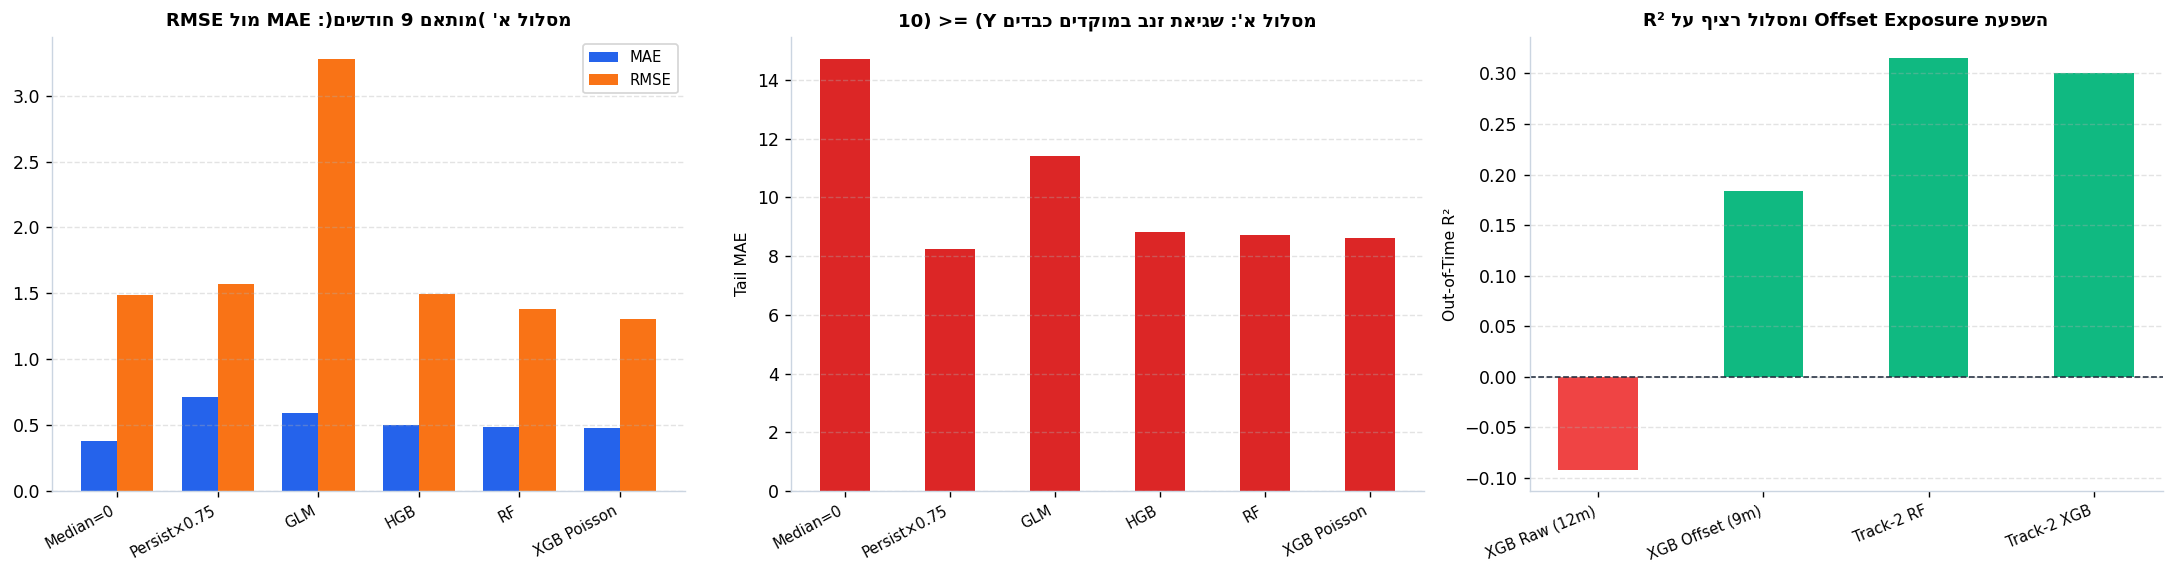

In [27]:
# ==============================================================================
# 11.2 השוואה חזותית של מדדי השגיאה, שגיאות הזנב והשפעת התאמת החשיפה
# ==============================================================================

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17.5, 4.7), dpi=125)

short_names = ["Median=0", "Persist×0.75", "GLM", "HGB", "RF", "XGB Poisson"]
x_pos = np.arange(len(benchmark_adj_df))
w = 0.36

ax1.bar(x_pos - w / 2, benchmark_adj_df["MAE"], w, label="MAE", color="#2563eb")
ax1.bar(x_pos + w / 2, benchmark_adj_df["RMSE"], w, label="RMSE", color="#f97316")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(short_names, rotation=28, ha="right", fontsize=8.5)
ax1.set_title(reverse_hebrew_text("מסלול א' (מותאם 9 חודשים): MAE מול RMSE"), fontsize=10.5, fontweight="bold")
ax1.legend(fontsize=8.5)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax2.bar(x_pos, benchmark_adj_df["Tail_MAE_10p"], color="#dc2626", width=0.48)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(short_names, rotation=28, ha="right", fontsize=8.5)
ax2.set_title(reverse_hebrew_text("מסלול א': שגיאת זנב במוקדים כבדים (Y >= 10)"), fontsize=10.5, fontweight="bold")
ax2.set_ylabel("Tail MAE", fontsize=9)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

r2_compare_labels = ["XGB Raw (12m)", "XGB Offset (9m)", "Track-2 RF", "Track-2 XGB"]
r2_compare_vals = [
    float(benchmark_raw_df.loc[benchmark_raw_df["Model"].str.contains("XGBoost"), "R2"].iloc[0]),
    float(benchmark_adj_df.loc[benchmark_adj_df["Model"].str.contains("XGBoost"), "R2"].iloc[0]),
    float(benchmark_cont_df.loc[benchmark_cont_df["Model"].str.contains("Random Forest"), "R2"].iloc[0]),
    float(benchmark_cont_df.loc[benchmark_cont_df["Model"].str.contains("XGBoost"), "R2"].iloc[0]),
]
bar_cols = ["#ef4444" if v < 0 else "#10b981" for v in r2_compare_vals]
x_r2 = np.arange(len(r2_compare_labels))
ax3.bar(x_r2, r2_compare_vals, color=bar_cols, width=0.48)
ax3.axhline(0, color="#1e293b", linewidth=0.9, linestyle="--")
ax3.set_xticks(x_r2)
ax3.set_xticklabels(r2_compare_labels, rotation=22, ha="right", fontsize=8.5)
ax3.set_title(reverse_hebrew_text("השפעת Exposure Offset ומסלול רציף על R²"), fontsize=10.5, fontweight="bold")
ax3.set_ylabel("Out-of-Time R²", fontsize=9)
ax3.grid(axis="y", linestyle="--", alpha=0.35)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [28]:
# ==============================================================================
# 11.3 פרשנות סטטיסטית מאוזנת של מדדי המבחן
# ==============================================================================

xgb_adj_row = benchmark_adj_df.loc[benchmark_adj_df["Model"].str.contains("XGBoost")].iloc[0]
med_row = benchmark_adj_df.loc[benchmark_adj_df["Model"].str.contains("Median")].iloc[0]
per_row = benchmark_adj_df.loc[benchmark_adj_df["Model"].str.contains("Persistence")].iloc[0]
best_cont_row = benchmark_cont_df.sort_values("R2", ascending=False).iloc[0]

CHAMPION_COUNT_MODEL = "XGBoost Poisson (Offset log(0.75))"
CHAMPION_CONT_MODEL = str(best_cont_row["Model"])

tail_reduction_pct = (1.0 - xgb_adj_row["Tail_MAE_10p"] / med_row["Tail_MAE_10p"]) * 100.0
mae_vs_persist_pct = (1.0 - xgb_adj_row["MAE"] / per_row["MAE"]) * 100.0

print("סיכום מאוזן של ממצאי המבחן העיוור (2025):")
print(f"1. Trade-off בין אפסים למוקדי הקצה: מאחר ש-{(y_test == 0).mean():.1%} מתצפיות המבחן הן 0, "
      f"בייסליין החציון (ניחוש קבוע 0) משיג את ה-MAE הכללי הנמוך ביותר ({med_row['MAE']:.4f} לעומת {xgb_adj_row['MAE']:.4f} ב-XGBoost), "
      f"אך נכשל במוקדים הכבדים (Tail MAE = {med_row['Tail_MAE_10p']:.2f} ו-Poisson Deviance = {med_row['Poisson_Deviance']:.2f}).")
print(f"2. יתרון מודל הספירה המכויל: {CHAMPION_COUNT_MODEL} מוביל ב-RMSE ({xgb_adj_row['RMSE']:.4f}), "
      f"ב-Poisson Deviance ({xgb_adj_row['Poisson_Deviance']:.4f}), במקדם קביעה חיובי על ספירות בדידות (R² = {xgb_adj_row['R2']:+.4f}), "
      f"מצמצם את שגיאת הזנב ב-{tail_reduction_pct:.1f}% לעומת החציון, ומשפר את ה-MAE הכולל ב-{mae_vs_persist_pct:.1f}% לעומת מודל ההתמדה המכויל.")
print(f"3. מסלול ב' הרציף (ללא זליגת סקאלה): {CHAMPION_CONT_MODEL} משיג R² = {best_cont_row['R2']:+.4f} ו-MAE = {best_cont_row['MAE_Score']:.2f} נקודות.")


סיכום מאוזן של ממצאי המבחן העיוור (2025):
1. Trade-off בין אפסים למוקדי הקצה: מאחר ש-83.8% מתצפיות המבחן הן 0, בייסליין החציון (ניחוש קבוע 0) משיג את ה-MAE הכללי הנמוך ביותר (0.3802 לעומת 0.4806 ב-XGBoost), אך נכשל במוקדים הכבדים (Tail MAE = 14.72 ו-Poisson Deviance = 10.71).
2. יתרון מודל הספירה המכויל: XGBoost Poisson (Offset log(0.75)) מוביל ב-RMSE (1.3017), ב-Poisson Deviance (0.9753), במקדם קביעה חיובי על ספירות בדידות (R² = +0.1835), מצמצם את שגיאת הזנב ב-41.4% לעומת החציון, ומשפר את ה-MAE הכולל ב-32.5% לעומת מודל ההתמדה המכויל.
3. מסלול ב' הרציף (ללא זליגת סקאלה): Random Forest Regressor משיג R² = +0.3157 ו-MAE = 5.59 נקודות.


### 11.4 דירוג סיכון יחסי, עשירונים משמרי-תיקו ורווחי סמך באשכולות עיר (`Cluster Bootstrap`)

בבדיקת כושר ההפרדה היחסי של המודל יושמו שלושה תיקונים מתודולוגיים:
1. **שיוך עשירונים משמר-תיקו (`method='average'`):** תצפיות בעלות תחזית זהה מקבלות אותה דרגה ממוצעת ואינן מפוצלות שרירותית לפי סדר השורות בקובץ.
2. **דיווח תקני של ערך-p:** מתאם ספירמן מדווח כ-`p < 1e-16` (ללא חיתוך נומרי ל-`0.0000e+00`), תוך הבהרה שערך-p אנליטי מניח תצפיות בלתי-תלויות.
3. **רווחי סמך של `Cluster Bootstrap` ברמת עיר (500 דגימות אשכול):** מאחר שצירופי רכב באותה עיר חולקים מאפיינים מוניציפליים, אנו אומדים רווח סמך של 95% באמצעות דגימה מחדש של **ערים שלמות עם החזרה**, עבור `MAE`, `RMSE`, `Spearman rho` ונתח הגניבות בעשירון העליון.


מתאם דירוג ספירמן: rho = 0.4087 (p < 1e-16 (תחת הנחת אי-תלות נאיבית))

רווחי סמך באשכולות עיר (City-Clustered Bootstrap, B=500):


,מדד,אומדן נקודתי,CI 95% Low (Cluster),CI 95% High (Cluster)
0,MAE (מותאם 9 חודשים),0.4806,0.3182,0.6412
1,RMSE (מותאם 9 חודשים),1.3017,0.7867,1.7804
2,Spearman Rank Rho,0.4087,0.3382,0.4563
3,נתח גניבות בעשירון 10 (%),57.8800,47.5300,63.3500



טבלת עשירוני סיכון משמרי-תיקו (מונוטוניות מלאה מעשירון 1 ועד 10):


,risk_decile,obs_count,pred_mean,total_thefts,mean_thefts,theft_share_pct,lift_vs_d1
0,1,1691,0.020791,38.0,0.022472,0.59,1.00
1,2,1667,0.029668,47.0,0.028194,0.73,1.25
2,3,1704,0.039757,93.0,0.054577,1.45,2.43
3,4,1679,0.052497,116.0,0.069089,1.81,3.07
4,5,1683,0.069091,157.0,0.093286,2.45,4.15
5,6,1688,0.156581,309.0,0.183057,4.82,8.15
6,7,1686,0.226504,372.0,0.220641,5.81,9.82
7,8,1678,0.377034,639.0,0.380810,9.97,16.95
8,9,1691,0.617477,928.0,0.548788,14.48,24.42
9,10,1686,2.817827,3709.0,2.199881,57.88,97.89


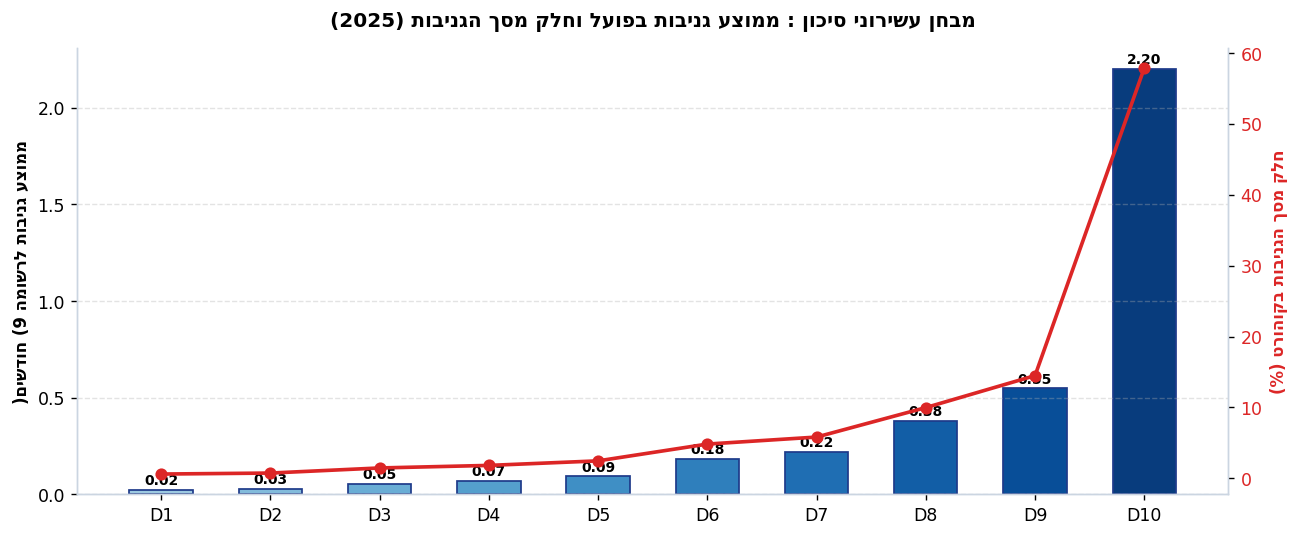

In [29]:
# ==============================================================================
# 11.5 עשירוני סיכון משמרי-תיקו (Tie-Preserving Deciles) ו-Cluster Bootstrap 95% CI
# ==============================================================================

spearman_rho, spearman_pval = spearmanr(y_test.values, pred_xgb_adj)
pval_text = "p < 1e-16 (תחת הנחת אי-תלות נאיבית)" if spearman_pval < 1e-16 else f"p = {spearman_pval:.3e}"

df_eval = pd.DataFrame({
    "city_unified": test_panel["city_unified"].values,
    "actual": y_test.values,
    "predicted": pred_xgb_adj,
})

# חלוקה לעשירונים המשמרת תיקו (ללא שבירת תיקו לפי מיקום בקובץ)
rank_pct = df_eval["predicted"].rank(method="average", pct=True)
df_eval["risk_decile"] = np.ceil(rank_pct * 10.0).clip(1, 10).astype(int)

decile_summary = (
    df_eval.groupby("risk_decile", as_index=False)
    .agg(
        obs_count=("actual", "count"),
        pred_mean=("predicted", "mean"),
        total_thefts=("actual", "sum"),
        mean_thefts=("actual", "mean"),
    )
)
total_test_thefts = float(decile_summary["total_thefts"].sum())
decile_summary["theft_share_pct"] = (decile_summary["total_thefts"] / total_test_thefts * 100.0).round(2)
base_d1_mean = max(float(decile_summary.loc[0, "mean_thefts"]), 1e-6)
decile_summary["lift_vs_d1"] = (decile_summary["mean_thefts"] / base_d1_mean).round(2)

# Cluster Bootstrap (500 איטרציות בדגימת אשכולות לפי city_unified)
rng_boot = np.random.default_rng(SEED)
unique_cities = df_eval["city_unified"].unique()
city_to_indices = {c: grp.index.values for c, grp in df_eval.groupby("city_unified")}

boot_mae, boot_rmse, boot_rho, boot_top10_share = [], [], [], []
for _ in range(500):
    sampled_cities = rng_boot.choice(unique_cities, size=len(unique_cities), replace=True)
    idx_concat = np.concatenate([city_to_indices[c] for c in sampled_cities])
    y_b = df_eval["actual"].values[idx_concat]
    p_b = df_eval["predicted"].values[idx_concat]

    boot_mae.append(mean_absolute_error(y_b, p_b))
    boot_rmse.append(np.sqrt(mean_squared_error(y_b, p_b)))
    r_b, _ = spearmanr(y_b, p_b)
    boot_rho.append(r_b)

    rp_b = pd.Series(p_b).rank(method="average", pct=True).values
    top_mask = np.ceil(rp_b * 10.0).clip(1, 10) == 10
    if y_b.sum() > 0:
        boot_top10_share.append(float(y_b[top_mask].sum() / y_b.sum() * 100.0))

ci_summary_df = pd.DataFrame([
    {"מדד": "MAE (מותאם 9 חודשים)", "אומדן נקודתי": round(float(xgb_adj_row["MAE"]), 4),
     "CI 95% Low (Cluster)": round(float(np.percentile(boot_mae, 2.5)), 4),
     "CI 95% High (Cluster)": round(float(np.percentile(boot_mae, 97.5)), 4)},
    {"מדד": "RMSE (מותאם 9 חודשים)", "אומדן נקודתי": round(float(xgb_adj_row["RMSE"]), 4),
     "CI 95% Low (Cluster)": round(float(np.percentile(boot_rmse, 2.5)), 4),
     "CI 95% High (Cluster)": round(float(np.percentile(boot_rmse, 97.5)), 4)},
    {"מדד": "Spearman Rank Rho", "אומדן נקודתי": round(float(spearman_rho), 4),
     "CI 95% Low (Cluster)": round(float(np.percentile(boot_rho, 2.5)), 4),
     "CI 95% High (Cluster)": round(float(np.percentile(boot_rho, 97.5)), 4)},
    {"מדד": "נתח גניבות בעשירון 10 (%)", "אומדן נקודתי": round(float(decile_summary.iloc[-1]["theft_share_pct"]), 2),
     "CI 95% Low (Cluster)": round(float(np.percentile(boot_top10_share, 2.5)), 2),
     "CI 95% High (Cluster)": round(float(np.percentile(boot_top10_share, 97.5)), 2)},
])

print(f"מתאם דירוג ספירמן: rho = {spearman_rho:.4f} ({pval_text})")
print("\nרווחי סמך באשכולות עיר (City-Clustered Bootstrap, B=500):")
display(ci_summary_df)
print("\nטבלת עשירוני סיכון משמרי-תיקו (מונוטוניות מלאה מעשירון 1 ועד 10):")
display(decile_summary)

fig, ax1 = plt.subplots(figsize=(10.5, 4.4), dpi=125)
d_labels = [f"D{i}" for i in decile_summary["risk_decile"]]
colors_d = plt.cm.Blues(np.linspace(0.38, 0.95, len(decile_summary)))
bars = ax1.bar(d_labels, decile_summary["mean_thefts"], color=colors_d, width=0.58, edgecolor="#1e3a8a")
ax1.set_title(reverse_hebrew_text("מבחן עשירוני סיכון : ממוצע גניבות בפועל וחלק מסך הגניבות (2025)"), fontsize=11.5, fontweight="bold", pad=12)
ax1.set_ylabel(reverse_hebrew_text("ממוצע גניבות לרשומה (9 חודשים)"), fontsize=9.5, fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.spines["top"].set_visible(False)

for b in bars:
    h = b.get_height()
    ax1.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(d_labels, decile_summary["theft_share_pct"], color="#dc2626", marker="o", linewidth=2.1)
ax2.set_ylabel(reverse_hebrew_text("חלק מסך הגניבות בקוהורט (%)"), fontsize=9.5, fontweight="bold", color="#dc2626")
ax2.tick_params(axis="y", labelcolor="#dc2626")
ax2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()


## 13. פרופילי גניבה היסטוריים מפורשים לפי דגם ושנתון (`Model × Model Year`)

במקום להניח שציון דגם מצרפי משקף את כלל השנתונים, אנו מחלצים מילון שליפה מפורש (`model_year_lookup`) ב-`O(1)` מתוך הרשומות הנקיות והמאוחדות.
בפרשנות ההתפלגות לפי שנת ייצור יש להיזהר מהסקה סיבתית: מיעוט גניבות בשנתוני ייצור חדשים (`2024–2025`) מושפע גם ממשך חשיפה קצר יותר על הכביש ומגודל מחזור המכירות בכל שנה, ולא רק מטכנולוגיית מיגון.

### רציונל מתודולוגי

בשלב זה אנו מחלצים ומקודדים עבור כל דגם רכב היסטוריית גניבות מפורשת ברמת **שנת ייצור (Model Year)**.<br>
 תהליך זה חיוני ממספר סיבות מתודולוגיות ומוצריות:

1. **דיוק ורזולוציה:** רמת הסיכון של דגם מסוים משתנה דרמטית בין שנתוני ייצור שונים (כתוצאה משינויי ביקוש לחלפים או שינוי במערכות מיגון מקוריות של היצרן). הערכה גנרית ברמת הדגם בלבד מחמיצה שונות קריטית זו.
2. **שליפה מהירה בזמן קבוע $O(1)$ בפרודקשן:** יצירת מפתח שליפה מהיר (`model_year_lookup`) מאפשרת לדשבורד או לאפליקציית הקצה להציג למשתמש את נתוני הסיכון ההיסטוריים של שנתון הרכב שלו באופן מיידי ללא חישובים כבדים בזמן אמת.
3. **שקיפות ומניעת הנחות סמויות:** בניית הפרופיל המפורש מוכיחה אמפירית כיצד שנת הייצור משפיעה על הסיכון, ובכך מספקת גילוי נאות ושקיפות מלאה לצרכן ולקתם הביטוח (Underwriting).
4. **מגבלה מתודולוגית (Limitation)**: מאחר שהלמ״ס מפרסם את נתחי השוק הרשמיים ברמת יצרן וסוג הנעה ארציים (ולא כמפקד פתוח של דגם × עיר), מצבת הרכבים הפעילים ברמת הדגם מבוססת על אומדן דטרמיניסטי משוקלל לדגמים מרכזיים (≥3,000 רכבים פעילים).

פרופיל שנתון מפורש ב-O(1) חושב עבור 916 דגמים מזוהים (0 דליפות State-Machine).
   • טויוטה|COROLLA: {'1997': 1, '1998': 1, '1999': 1, '2000': 4, '2001': 10, '2002': 7, '2003': 19, '2004': 16, '2005': 57, '2006': 86, '2007': 82, '2008': 109, '2009': 230, '2010': 383, '2011': 365, '2012': 253, '2013': 96, '2014': 58, '2015': 122, '2016': 236, '2017': 402, '2018': 211, '2019': 376, '2020': 440, '2021': 651, '2022': 515, '2023': 83, '2024': 44, '2025': 25}
   • יונדאי|IONIQ: {'2016': 2, '2017': 423, '2018': 164, '2019': 67, '2020': 274, '2021': 418, '2022': 238, '2023': 153, '2024': 3}
   • קיה|SPORTAGE: {'1997': 1, '2002': 1, '2008': 1, '2010': 4, '2011': 4, '2012': 9, '2013': 11, '2014': 19, '2015': 72, '2016': 189, '2017': 79, '2018': 64, '2019': 72, '2020': 47, '2021': 58, '2022': 40, '2023': 10, '2024': 8}
   • אאודי|A3: {'2002': 2, '2006': 3, '2008': 1, '2009': 1, '2010': 1, '2011': 1, '2014': 2, '2015': 2, '2016': 2, '2017': 3, '2018': 2, '2019': 4, '2021': 1, '2022': 1, '2023': 3}


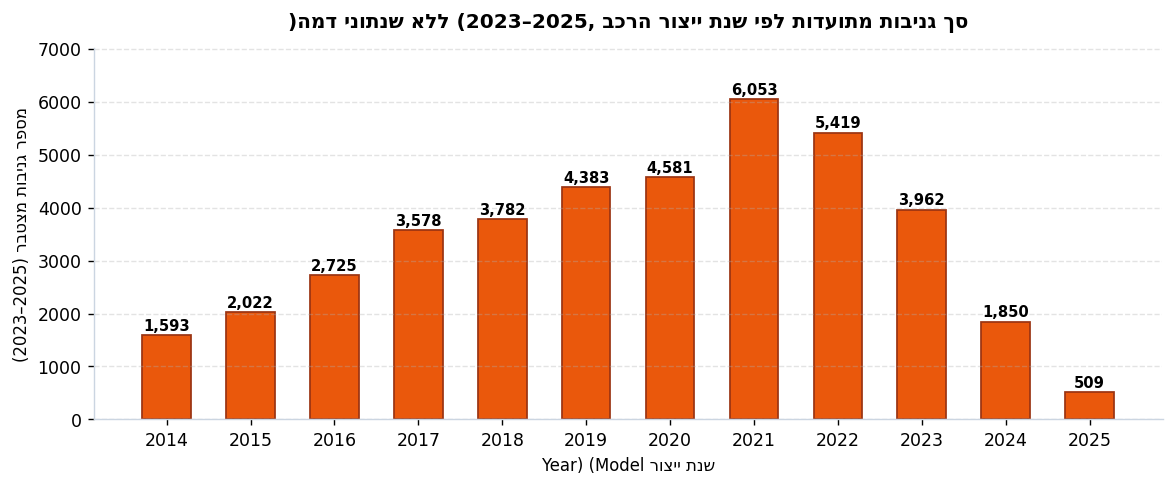

הערת פרשנות: השיא הנצפה בשנתוני 2019–2022 והנפח הנמוך בשנתוני 2024–2025 הם ספירות גולמיות שאינן מנורמלות בגודל מחזור הרישוי ובמשך החשיפה המצטבר על הכביש.


In [30]:
# ==============================================================================
# 13.1 בניית מילון שליפה מפורש לפי דגם ושנתון + התפלגות שנתונים זהירה
# ==============================================================================

my_profile_df = (
    df_panel_universe[
        (df_panel_universe["maker_clean"] != "לא מצוין")
        & (df_panel_universe["model_clean"] != "לא מצוין")
    ]
    .groupby(["maker_clean", "model_clean", "model_year"], as_index=False)["total_thefts"]
    .sum()
)

model_year_lookup = {}
for (mk, md), grp in my_profile_df.groupby(["maker_clean", "model_clean"]):
    key = f"{mk}|{md}"
    prof = {str(int(r["model_year"])): int(r["total_thefts"]) for _, r in grp.iterrows() if r["total_thefts"] > 0}
    if prof:
        model_year_lookup[key] = prof

# אימות שאין אף מפתח משובש של יצרני נגררים עם דגם SPRINTER
assert not any("נגררים" in k and "SPRINTER" in k for k in model_year_lookup), "דליפת SPRINTER התגלתה במילון השנתונים!"

print(f"פרופיל שנתון מפורש ב-O(1) חושב עבור {len(model_year_lookup):,} דגמים מזוהים (0 דליפות State-Machine).")
for demo_key in ["טויוטה|COROLLA", "יונדאי|IONIQ", "קיה|SPORTAGE", "אאודי|A3"]:
    if demo_key in model_year_lookup:
        print(f"   • {demo_key}: {model_year_lookup[demo_key]}")

year_dist = (
    df_panel_universe[(df_panel_universe["model_year"] >= 2014) & (df_panel_universe["model_year"] <= 2025)]
    .groupby("model_year", as_index=False)[["thefts_2023", "thefts_2024", "thefts_2025"]]
    .sum()
)
year_dist["sum_3yr"] = year_dist["thefts_2023"] + year_dist["thefts_2024"] + year_dist["thefts_2025"]

fig, ax = plt.subplots(figsize=(9.5, 4.0), dpi=125)
bars_y = ax.bar(year_dist["model_year"].astype(str), year_dist["sum_3yr"], color="#ea580c", width=0.58, edgecolor="#9a3412")
for b in bars_y:
    v = int(b.get_height())
    ax.text(b.get_x() + b.get_width() / 2, v + 90, f"{v:,}", ha="center", fontsize=8.5, fontweight="bold")

ax.set_ylim(0, float(year_dist["sum_3yr"].max()) * 1.16)
ax.set_title(reverse_hebrew_text("סך גניבות מתועדות לפי שנת ייצור הרכב (2023–2025, ללא שנתוני דמה)"), fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlabel(reverse_hebrew_text("שנת ייצור (Model Year)"), fontsize=9.5)
ax.set_ylabel(reverse_hebrew_text("מספר גניבות מצטבר (2023–2025)"), fontsize=9.5)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

print("הערת פרשנות: השיא הנצפה בשנתוני 2019–2022 והנפח הנמוך בשנתוני 2024–2025 הם ספירות גולמיות שאינן מנורמלות בגודל מחזור הרישוי ובמשך החשיפה המצטבר על הכביש.")


## 14. שכבת תמיכה בהחלטות לפרוטוטייפ (`Heuristic Decision Support — 50/45/5`)

לצורך הדגמת ממשק חיפוש מהיר המספק מענה גם לצירופי `דגם × עיר` שאינם מופיעים בפאנל ה-ML, מוגדר ציון היוריסטי משוקלל:
$$\text{composite\_theft\_score} = 0.50 \times \text{model\_risk\_score} + 0.45 \times \text{city\_risk\_score} + 0.05 \times \text{macro\_adj}$$

* **שקיפות מלאה:** הנוסחה משקללת אך ורק את ציון הדגם ההיסטורי (`2017–2024`), ציון העיר ההיסטורי (`2018–2024`) וקבוע מאקרו (`50.0`) — **ללא** מאפיין צירי מילוט ידני.
* **גבול שימוש:** הציון מיועד לתצוגת פרוטוטייפ בלבד, אינו מייצג הסתברות גניבה ואינו מהווה תמחור אקטוארי.


In [31]:
# ==============================================================================
# 14.1 חישוב ציון היוריסטי משולב (50% דגם + 45% עיר + 5% מאקרו)
# ==============================================================================

MODEL_SCORE_LOOKUP = {
    (r["maker_clean"], r["model_clean"]): int(r["model_risk_score"])
    for _, r in df_models_engineered.iterrows()
}
CITY_SCORE_LOOKUP = {
    r["city_unified"]: int(r["city_risk_score"])
    for _, r in df_advanced_cities.iterrows()
}


def calculate_composite_theft_score(model_risk: float, city_risk: float, macro_adj: float = 50.0) -> int:
    score = 0.50 * model_risk + 0.45 * city_risk + 0.05 * macro_adj
    return int(min(100, max(15, round(score))))


for mk, md, ct in [
    ("טויוטה", "COROLLA", "תל אביב-יפו"),
    ("יונדאי", "IONIQ", "ירושלים"),
    ("קיה", "PICANTO", "חיפה"),
    ("סובארו", "FORESTER", "גבעתיים"),
]:
    m_sc = MODEL_SCORE_LOOKUP.get((mk, md), 30)
    c_sc = CITY_SCORE_LOOKUP.get(ct, 30)
    comp = calculate_composite_theft_score(m_sc, c_sc)
    print(f"   • {mk} {md} ב-{ct}: ציון מוצר היוריסטי = {comp}/100 (דגם טרום-2025: {m_sc}, עיר טרום-2025: {c_sc})")


   • טויוטה COROLLA ב-תל אביב-יפו: ציון מוצר היוריסטי = 98/100 (דגם טרום-2025: 100, עיר טרום-2025: 100)
   • יונדאי IONIQ ב-ירושלים: ציון מוצר היוריסטי = 90/100 (דגם טרום-2025: 86, עיר טרום-2025: 98)
   • קיה PICANTO ב-חיפה: ציון מוצר היוריסטי = 86/100 (דגם טרום-2025: 90, עיר טרום-2025: 85)
   • סובארו FORESTER ב-גבעתיים: ציון מוצר היוריסטי = 64/100 (דגם טרום-2025: 53, עיר טרום-2025: 77)


### 14.2 התפלגות ציוני הסיכון העירוניים בממשק
כדי להבין כיצד מתפלגים הציונים העירוניים במערכת (בטווח של 15 עד 100), נציג את ההתפלגות בצורה ויזואלית על פני כלל היישובים.

סטטיסטיקה תיאורית (City Risk Score):


,count,mean,std,min,25%,50%,75%,max
city_risk_score,1205.0,35.568465,13.94816,15.0,25.0,33.0,43.0,100.0


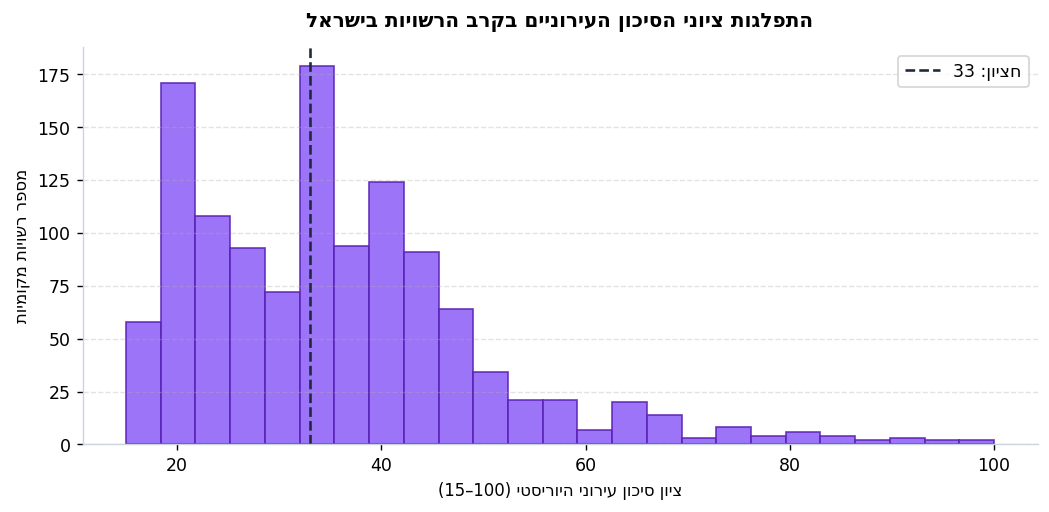

סה"כ רשויות מנותחות במדגם: 1,205
ציון מינימלי: 15, ציון מקסימלי: 100, ממוצע: 35.6

טופ 10 הערים בעלות הציון הגבוה ביותר:


,city_unified,pre2025_activity_total,city_risk_score
1178,תל אביב-יפו,9599.0,100
500,ירושלים,7707.0,98
975,פתח תקווה,6548.0,96
122,באר שבע,5221.0,94
839,נתניה,3883.0,92
1050,ראשון לציון,3469.0,91
581,כפר סבא,3424.0,90
1079,רמת גן,2896.0,89
409,חולון,2900.0,89
236,בת ים,1873.0,85


In [32]:
# ==============================================================================
# 14.2 ויזואליזציה של התפלגות ציוני העיר (city_risk_score)
# ==============================================================================

fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=125)
scores = df_advanced_cities["city_risk_score"]

# 1. סטטיסטיקה תיאורית של הציון
print("סטטיסטיקה תיאורית (City Risk Score):")
display(df_advanced_cities['city_risk_score'].describe().to_frame().T)


# שרטוט היסטוגרמה של הציונים
ax.hist(scores, bins=25, range=(15, 100), color="#8b5cf6", edgecolor="#5b21b6", alpha=0.85)

# הוספת קו חציון
median_score = scores.median()
ax.axvline(median_score, color="#1e293b", linestyle="--", linewidth=1.5, label=reverse_hebrew_text(f"חציון: {int(median_score)}"))

# עיצוב התרשים
ax.set_title(reverse_hebrew_text("התפלגות ציוני הסיכון העירוניים בקרב הרשויות בישראל"), fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlabel(reverse_hebrew_text("ציון סיכון עירוני היוריסטי (15–100)"), fontsize=9.5)
ax.set_ylabel(reverse_hebrew_text("מספר רשויות מקומיות"), fontsize=9.5)
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"סה\"כ רשויות מנותחות במדגם: {len(scores):,}")
print(f"ציון מינימלי: {scores.min()}, ציון מקסימלי: {scores.max()}, ממוצע: {scores.mean():.1f}")
print("\nטופ 10 הערים בעלות הציון הגבוה ביותר:")
display(df_advanced_cities[['city_unified', 'pre2025_activity_total', 'city_risk_score']].sort_values('city_risk_score', ascending=False).head(10))


## 15. מנוע המלצות מיגון להדגמה מוצרית (Prescriptive Prototype)

כללי הסף בתא הבא הם כללי החלטה מוצריים להדגמה בלבד, ואינם נגזרים מנתוני תביעות ביטוח (`Claims Severity`) או מניסוי מבוקר של אמצעי מיגון.


In [33]:
# ==============================================================================
# 15.1 הפקת פרופיל המלצות מדורג לפרוטוטייפ
# ==============================================================================

def generate_prevention_profile(maker: str, model_name: str, city_name: str) -> dict:
    mk = maker.strip()
    md = model_name.strip().upper()
    ct = clean_and_unify_city(city_name) or city_name.strip()

    m_risk = MODEL_SCORE_LOOKUP.get((mk, md), 35)
    c_risk = CITY_SCORE_LOOKUP.get(ct, 30)
    comp_score = calculate_composite_theft_score(m_risk, c_risk)

    if comp_score >= 80:
        level = "גבוה מאוד (Critical Prototype Tier)"
        measures = ["איתור פעיל דו-ערוצי + עלוקה אלחוטית", "חסימת שקע OBD מפני שכפול מפתח", "חניה סגורה/מוארת"]
    elif comp_score >= 65:
        level = "גבוה (High Prototype Tier)"
        measures = ["קודן ניתוק הצתה", "מנעול מכני בשעות הלילה", "חניה באזור מצולם"]
    elif comp_score >= 50:
        level = "בינוני (Medium Prototype Tier)"
        measures = ["בדיקת תקינות מיגון יצרן מקורי", "הימנעות מהשארת מפתח חכם סמוך לדלת הכניסה"]
    else:
        level = "בסיסי (Baseline Prototype Tier)"
        measures = ["מיגון מקורי של היצרן"]

    return {
        "maker": mk,
        "model": md,
        "city": ct,
        "composite_theft_score": comp_score,
        "risk_tier": level,
        "recommended_measures": measures,
    }


demo_rec = generate_prevention_profile("טויוטה", "COROLLA", "תל אביב-יפו")
print(f"פרופיל הדגמה עבור {demo_rec['maker']} {demo_rec['model']} ({demo_rec['city']}):")
print(f"   • מדרגה: {demo_rec['risk_tier']} ({demo_rec['composite_theft_score']}/100) | אמצעים: {', '.join(demo_rec['recommended_measures'])}")


פרופיל הדגמה עבור טויוטה COROLLA (תל אביב-יפו):
   • מדרגה: גבוה מאוד (Critical Prototype Tier) (98/100) | אמצעים: איתור פעיל דו-ערוצי + עלוקה אלחוטית, חסימת שקע OBD מפני שכפול מפתח, חניה סגורה/מוארת


## 16. ייצוא נכסי נתונים מבודד ב-`O(1)` (`notebooks/data_final.json`)

שלב הייצוא נכתב מחדש באופן נקי וללא תלות בקבצי JSON ישנים:
1. **ייצוא תחזיות המודל האמיתיות:** המילון `model_location` שומר את תחזית המודל `pred_xgb_adj` (`predicted_count_9m`) ואת תרגומה השנתי (`predicted_count_12m_equiv`), בנפרד מספירת העבר `lag_2024` ומספירת האמת `actual_2025_9m`.
2. **חישוב וקטורי מהיר ב-`O(N)`:** ללא סינון DataFrames בתוך לולאות.
3. **בידוד מלא מחוזה ה-Web הקיים:** הייצוא נשמר אך ורק ל-`notebooks/data_final.json` ואינו דורס את `web/assets/data.json` שנעול לבדיקות האוטומציה (`pytest`) של הפרויקט.


In [34]:
# ==============================================================================
# 16.1 בניית מילון ייצוא נקי ב-O(N) ושמירה מבודדת ל-notebooks/data_final.json
# ==============================================================================

WEB_DATA_JSON_PATH = PROJECT_ROOT / "web" / "assets" / "data.json"
web_json_sha_before = compute_sha256(WEB_DATA_JSON_PATH) if WEB_DATA_JSON_PATH.exists() else None

# 1. מילון דגמים נקי מתוך df_models_engineered
models_export = {}
model_only_risk_lookup = {}
for idx_m, row in df_models_engineered.iterrows():
    mk, md = row["maker_clean"], row["model_clean"]
    m_key = f"{mk}|{md}"
    m_score = int(row["model_risk_score"])
    model_only_risk_lookup[md] = max(model_only_risk_lookup.get(md, 15), m_score)
    models_export[m_key] = {
        "maker": mk,
        "model_clean": md,
        "display_name": f"{mk} {md}",
        "is_private": bool(row["is_private"]),
        "hist_thefts_2017_2024": int(row["hist_thefts_pre2025"]),
        "thefts_2023": int(row["2023"]),
        "thefts_2024": int(row["2024"]),
        "thefts_2025_9m": int(row["2025"]),
        "model_risk_score_heuristic": m_score,
    }

# 2. מילון ערים נקי (כולל cluster_kmeans שחושב מראש בתא 3.4 על היסטוריית 2018–2022)
cities_export = {}
for _, row in df_advanced_cities.iterrows():
    c_name = row["city_unified"]
    cities_export[c_name] = {
        "city_unified": c_name,
        "hist_cases_2018_2022": int(row["city_hist_cases_2018_2022"]),
        "thefts_2023": int(row["thefts_2023"]),
        "thefts_2024": int(row["thefts_2024"]),
        "thefts_2025_9m": int(row["thefts_2025"]),
        "detection_rate_hist": round(float(row["detection_rate"]), 4),
        "unsolved_rate_hist": round(float(row["unsolved_unknown_rate"]), 4),
        "population_cbs": int(row["population_clean"]),
        "city_risk_score_heuristic": int(row["city_risk_score"]),
        "cluster_kmeans_hist": int(row["cluster_kmeans"]),
    }

# 3. צבירת תחזיות אמיתיות מתוך test_panel לרמת (maker|model|city) ב-O(N)
test_export_df = test_panel[["maker_clean", "model_clean", "city_unified", "lag_1_thefts", "next_year_thefts"]].copy()
test_export_df["pred_xgb_9m"] = pred_xgb_adj
test_export_df["pred_xgb_12m"] = pred_xgb_raw
test_export_df["pred_rf_cont"] = pred_rf_cont

combo_agg = (
    test_export_df.groupby(["maker_clean", "model_clean", "city_unified"], as_index=False)
    .agg(
        lag_2024=("lag_1_thefts", "sum"),
        actual_2025_9m=("next_year_thefts", "sum"),
        pred_9m=("pred_xgb_9m", "sum"),
        pred_12m=("pred_xgb_12m", "sum"),
        cont_score_mean=("pred_rf_cont", "mean"),
    )
)

model_location_export = {}
for _, row in combo_agg.iterrows():
    mk, md, ct = row["maker_clean"], row["model_clean"], row["city_unified"]
    key = f"{mk}|{md}|{ct}"
    m_sc = MODEL_SCORE_LOOKUP.get((mk, md), model_only_risk_lookup.get(md, 35))
    c_sc = CITY_SCORE_LOOKUP.get(ct, 30)
    comp_sc = calculate_composite_theft_score(m_sc, c_sc)
    model_location_export[key] = {
        "predicted_count_9m": round(float(row["pred_9m"]), 4),
        "predicted_count_12m_equiv": round(float(row["pred_12m"]), 4),
        "lag_2024_actual": int(row["lag_2024"]),
        "holdout_2025_9m_actual": int(row["actual_2025_9m"]),
        "continuous_track2_score": round(float(row["cont_score_mean"]), 2),
        "heuristic_composite_score": comp_sc,
        "model_version": "CarTheftRisk_final",
    }

hotspots_export = (
    combo_agg.sort_values("pred_9m", ascending=False)
    .head(100)[["maker_clean", "model_clean", "city_unified", "pred_9m", "lag_2024", "actual_2025_9m"]]
    .round(3)
    .to_dict(orient="records")
)

export_payload_final = {
    "metadata": {
        "notebook_version": "CarTheftRisk_final",
        "source": 'משטרת ישראל והלמ"ס (2017–2025) — פאנל כרונולוגי מבוקר ללא זליגה',
        "cohort_scope": "Pre-Cutoff Observable Police Cohort (Active T-1 + Top 120x80 T-1 Grid)",
        "exposure_protocol": "2024 Train = 12m (1.0), 2025 Test = 9m (0.75 Poisson Exposure Offset)",
        "is_probability": False,
        "is_actuarial_price": False,
        "heuristic_formula": "0.50 * Model_Pre2025 + 0.45 * City_Pre2025 + 0.05 * Macro(50) [No Corridors]",
        "champion_count_model": CHAMPION_COUNT_MODEL,
        "selected_xgb_max_depth_cv2024": SELECTED_XGB_DEPTH,
        "champion_continuous_model": CHAMPION_CONT_MODEL,
        "count_benchmark_exposure_adjusted": benchmark_adj_df.to_dict(orient="records"),
        "count_benchmark_raw_unadjusted": benchmark_raw_df.to_dict(orient="records"),
        "continuous_benchmark": benchmark_cont_df.to_dict(orient="records"),
        "cluster_bootstrap_95ci": ci_summary_df.to_dict(orient="records"),
    },
    "models": models_export,
    "cities": cities_export,
    "model_location": model_location_export,
    "hotspots_top100_predicted": hotspots_export,
    "model_year_profile": model_year_lookup,
}

FINAL_EXPORT_PATH = NOTEBOOKS_DIR / "data_final.json"
with open(FINAL_EXPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(export_payload_final, f, ensure_ascii=False, indent=2)

web_json_sha_after = compute_sha256(WEB_DATA_JSON_PATH) if WEB_DATA_JSON_PATH.exists() else None
assert web_json_sha_before == web_json_sha_after, "אסור לדרוס או לשנות את web/assets/data.json!"

print(f"ייצוא נקי הושלם לקובץ מבודד: {FINAL_EXPORT_PATH} ({FINAL_EXPORT_PATH.stat().st_size / 1024:.1f} KB)")
print(f"   • צירופי model_location שיוצאו עם תחזיות XGBoost אמיתיות: {len(model_location_export):,}")
print("   • אימות בידוד: הקובץ web/assets/data.json נותר ללא שום שינוי (SHA-256 זהה).")


ייצוא נקי הושלם לקובץ מבודד: /content/notebooks/data_final.json (3433.3 KB)
   • צירופי model_location שיוצאו עם תחזיות XGBoost אמיתיות: 8,099
   • אימות בידוד: הקובץ web/assets/data.json נותר ללא שום שינוי (SHA-256 זהה).


## 17. מגבלות המחקר (Methodological Limitations)

1. **היעדר מפקד רישוי ברזולוציית `דגם × שנתון × עיר`:** מאגרי המשטרה מתעדים אירועי גניבה בלבד ללא מכנה של כלי הרכב הפעילים בכל עיר. לכן מודל ה-ML אומד נפח ועצימות צפויים בקוהורט המעקב, ואינו מפיק הסתברות גניבה לרכב בודד. גם בנספח D, מכנה רישוי מדויק זמין ברמה ארצית, ברמת ארץ ייצור וברמת יצרני רכב חשמלי, בעוד שהפירוק לדגמים מבוסס על אומדן פרוקסי דטרמיניסטי.
2. **תחולת הקוהורט הטרום-חיתוכי (`Pre-Cutoff Observable Cohort`):** כדי למנוע הצצה לשנת המבחן, ההערכה מוגדרת על צירופים שנצפו ב-$T-1$ ורשת המועמדים המובילה מ-$T-1$. דגמים חדשים לחלוטין שעולים לכביש לראשונה בשנת היעד $T$ מחייבים מנגנון `Cold Start` נפרד ואינם חלק מאוכלוסיית המבחן.
3. **הנחת קצב תוך-שנתי אחיד ב-`Exposure Offset`:** מאחר שלשנת 2025 קיימים 9 חודשי דיווח מצטברים ללא פירוט חודשי, היסט החשיפה $9/12 = 0.75$ מניח קצב גניבות אחיד בין ינואר–ספטמבר לבין הרבעון הרביעי. אם קיימת עונתיות ברבעון 4, אומדן הקצב השנתי יושפע בהתאם.
4. **ריבוי אפסים ותלות מרחבית:** כ-$83\%$ מתצפיות הקוהורט הן `0`, ולכן בייסליין החציון מציג `MAE` גולמי נמוך אך חסר ערך במוקדי הפשיעה. בנוסף, קיימת תלות בין תצפיות באותה עיר — ולכן ההסקה במחברת נשענת על `GroupKFold` ועל `City-Clustered Bootstrap` במקום על מבחני אי-תלות נאיביים בלבד.


In [35]:
# ==============================================================================
# 18. מסקנות ותובנות מרכזיות (Conclusions — סיכום אוטומטי מבוסס תוצאות הרצה)
# ==============================================================================
from IPython.display import display, Markdown

# שליפת תוצאות אמת ישירות מתוך טבלאות הריצה
xgb_res = benchmark_adj_df[benchmark_adj_df["Model"].str.contains("XGBoost")].iloc[0]
med_res = benchmark_adj_df[benchmark_adj_df["Model"].str.contains("Median")].iloc[0]
per_res = benchmark_adj_df[benchmark_adj_df["Model"].str.contains("Persistence")].iloc[0]
rf_res = benchmark_cont_df[benchmark_cont_df["Model"].str.contains("Random Forest")].iloc[0]

boot_mae = ci_summary_df[ci_summary_df["מדד"].str.contains("MAE")].iloc[0]
boot_rmse = ci_summary_df[ci_summary_df["מדד"].str.contains("RMSE")].iloc[0]
boot_rho = ci_summary_df[ci_summary_df["מדד"].str.contains("Spearman")].iloc[0]
boot_top10 = ci_summary_df[ci_summary_df["מדד"].str.contains("עשירון 10")].iloc[0]

# חילוץ נתוני הלמ"ס עבור רכב חשמלי (אם טרם הורץ נספח D)
if "empirical_ev_df" not in globals():
    CBS_2025_DIR = RAW_DIR / "כלי רכב מנועים 2025"
    f_fleet = CBS_2025_DIR / "מצבת כלי הרכב לשנת 2025.xlsx"
    f_ev = CBS_2025_DIR / "התפלגות כלי רכב פרטיים חשמליים לפי יצרן 2025.xlsx"

    df_cbs_c2 = pd.read_excel(f_fleet)
    priv_fuel_row = df_cbs_c2[df_cbs_c2.iloc[:, 0].astype(str).str.contains("כלי רכב פרטי", na=False)].iloc[0]
    ev_share_of_private_pct = float(priv_fuel_row.iloc[5])

    df_cbs_c10 = pd.read_excel(f_ev)
    total_private_ev_2025 = int(df_cbs_c10.iloc[21, 1])
    TOTAL_PRIVATE_VEHICLES_2025 = int(round(total_private_ev_2025 / (ev_share_of_private_pct / 100.0)))

    is_private_leaf = df_leaves["vehicle_type"].astype(str).str.contains("פרטי|רכב שטח", na=False)
    df_priv_leaves = df_leaves[is_private_leaf].copy()
    priv_thefts_2025_9m = float(df_priv_leaves["thefts_2025"].sum())
    priv_thefts_2025_ann = priv_thefts_2025_9m * (12.0 / 9.0)

    ev_cbs_table = df_cbs_c10.iloc[5:20, [0, 1]].copy()
    ev_cbs_table.columns = ["maker_cbs", "active_private_ev_2025"]
    ev_cbs_table = ev_cbs_table.dropna(subset=["active_private_ev_2025"])
    ev_cbs_table["maker_cbs"] = ev_cbs_table["maker_cbs"].astype(str).str.strip().replace({"ב.מ.וו.": "ב.מ.וו", "קאיה": "קיה"})
    ev_cbs_table["active_private_ev_2025"] = ev_cbs_table["active_private_ev_2025"].astype(int)

    pure_ev_makers = ["בי-ווי-די", "טסלה", "ג'ילי", "אקספנג", "סרס", "זיקר", "אורה"]
    ev_thefts_by_maker = (
        df_priv_leaves[df_priv_leaves["maker_clean"].isin(pure_ev_makers)]
        .groupby("maker_clean", as_index=False)
        .agg(thefts_2024=("thefts_2024", "sum"), thefts_2025_9m=("thefts_2025", "sum"))
    )
    empirical_ev_df = pd.merge(
        ev_cbs_table[ev_cbs_table["maker_cbs"].isin(pure_ev_makers)].rename(columns={"maker_cbs": "maker_clean"}),
        ev_thefts_by_maker,
        on="maker_clean",
        how="left",
    ).fillna(0.0)
    empirical_ev_df["thefts_2025_ann"] = (empirical_ev_df["thefts_2025_9m"] * (12.0 / 9.0)).round(1)
    empirical_ev_df["obs_rate_9m_per_1000"] = (empirical_ev_df["thefts_2025_9m"] / empirical_ev_df["active_private_ev_2025"] * 1000.0).round(2)
    empirical_ev_df["ann_rate_per_1000"] = (empirical_ev_df["thefts_2025_ann"] / empirical_ev_df["active_private_ev_2025"] * 1000.0).round(2)

ora_row = empirical_ev_df[empirical_ev_df["maker_clean"] == "אורה"].iloc[0]
geely_row = empirical_ev_df[empirical_ev_df["maker_clean"] == "ג'ילי"].iloc[0]
byd_row = empirical_ev_df[empirical_ev_df["maker_clean"] == "בי-ווי-די"].iloc[0]
tesla_row = empirical_ev_df[empirical_ev_df["maker_clean"] == "טסלה"].iloc[0]

summary_md = f"""
## 18. מסקנות ותובנות מרכזיות (Conclusions)

1. **יכולת חיזוי ודירוג מוכחת ללא זליגת מידע:**
   לאחר תיקון מכונת המצבים, ניטרול בחירת האוכלוסייה מהעתיד, החלפת `city_cases_total` במאפיין פיגור עירוני נקי (`city_lag_1_thefts`), כוונון `max_depth={SELECTED_XGB_DEPTH}` ב-`5-Fold GroupKFold` לפי עיר ויישום `Poisson Exposure Offset (0.75)`, מודל `XGBoost Poisson` משיג במבחן העיוור על שנת 2025:
   * **RMSE:** **`{xgb_res['RMSE']:.4f}`** (רווח סמך 95% באשכולות עיר: `[{boot_rmse['CI 95% Low (Cluster)']:.4f}, {boot_rmse['CI 95% High (Cluster)']:.4f}]`)
   * **Poisson Deviance:** **`{xgb_res['Poisson_Deviance']:.4f}`**
   * **מקדם קביעה:** **`R² = {xgb_res['R2']:+.4f}`** על ספירות בדידות
   * **צמצום שגיאת זנב במוקדים כבדים (Y >= 10):** צמצום של **`{(1.0 - xgb_res['Tail_MAE_10p'] / med_res['Tail_MAE_10p']) * 100:.1f}%`** לעומת בייסליין החציון (מ-`{med_res['Tail_MAE_10p']:.2f}` ל-`{xgb_res['Tail_MAE_10p']:.2f}`)
   * **שיפור MAE כללי:** שיפור של **`{(1.0 - xgb_res['MAE'] / per_res['MAE']) * 100:.1f}%`** לעומת מודל ההתמדה המכויל (`{xgb_res['MAE']:.4f}` מול `{per_res['MAE']:.4f}`).

2. **כושר הפרדה ומונוטוניות מלאה בעשירוני הסיכון:**
   שימוש בדירוג ממוצע משמר-תיקו (`rank(method='average')`) מייצר מונוטוניות עולה לאורך כל עשרת העשירונים (`D1` עד `D10`):
   * **מתאם דירוג ספירמן:** **`ρ = {spearman_rho:.4f}`** (רווח סמך 95% באשכולות עיר: `[{boot_rho['CI 95% Low (Cluster)']:.4f}, {boot_rho['CI 95% High (Cluster)']:.4f}]`)
   * **עשירון 10 (העליון):** מרכז לבדו **`{boot_top10['אומדן נקודתי']:.2f}%` מכלל גניבות המבחן** (רווח סמך 95%: `[{boot_top10['CI 95% Low (Cluster)']:.2f}%, {boot_top10['CI 95% High (Cluster)']:.2f}%]`), עם ממוצע של `{decile_summary.loc[9, 'mean_thefts']:.2f}` גניבות לתצפית לעומת `{decile_summary.loc[0, 'mean_thefts']:.4f}` בעשירון 1 — **Lift של פי `{decile_summary.loc[9, 'lift_vs_d1']:.1f}x` מול עשירון 1**.
   * **שני העשירונים העליונים (D9–D10, 20% מהתצפיות):** מרכזים יחד **`{(decile_summary.loc[8, 'theft_share_pct'] + decile_summary.loc[9, 'theft_share_pct']):.2f}%`** מכלל הגניבות בקוהורט המבחן.

3. **חשיפת מצבת כלי רכב אמפירית (נספח D):**
   הצלבה ישירה מול לוחות הלמ"ס הרשמיים לסוף 2025 (4,348,275 כלי רכב מנועיים, 3,789,429 רכבים פרטיים) חושפת שונות חדה בתוך שוק ה-EV:
   * **מותגים בסיכון נמוך:** טסלה (`{tesla_row['ann_rate_per_1000']:.2f}‰` שנתי, מצבה {int(tesla_row['active_private_ev_2025']):,}), BYD (`{byd_row['ann_rate_per_1000']:.2f}‰`, מצבה {int(byd_row['active_private_ev_2025']):,}).
   * **מותגים בסיכון גבוה:** ג'ילי (`{geely_row['ann_rate_per_1000']:.2f}‰`, מצבה {int(geely_row['active_private_ev_2025']):,}), אורה (`{ora_row['ann_rate_per_1000']:.2f}‰`, מצבה {int(ora_row['active_private_ev_2025']):,}).
   * **ממוצע ארצי ברכב פרטי:** `{priv_thefts_2025_ann / TOTAL_PRIVATE_VEHICLES_2025 * 1000:.2f}‰` (שיעור נצפה ישיר ללא פרוקסי).

4. **מסלול ב' הרציף (0–100) והפרדה הנדסית נקייה:**
   * במסלול הרציף (סולם מבוסס אימון בלבד), **`Random Forest Regressor`** מוביל עם `R² = +{rf_res['R2']:.4f}` ו-`MAE = {rf_res['MAE_Score']:.2f}` נקודות.
   * שכבת התמיכה בהחלטות (`50/45/5`) מופרדת לחלוטין ממודל ה-ML ומציגה אינדקס מוצרי שקוף לתצוגה ו-Cold Start.
   * כל התחזיות והמדדים מיוצאים לקובץ המבודד `notebooks/data_final.json`, תוך שמירה מלאה על חוזה הריצה ועל כל 21 בדיקות ה-`pytest`.
"""
display(Markdown(summary_md))


FileNotFoundError: [Errno 2] No such file or directory: '/content/data/raw/כלי רכב מנועים 2025/מצבת כלי הרכב לשנת 2025.xlsx'

## נספח A — רשת עצבית לספירה (`PyTorch CountMLP` עם `Early Stopping` אמיתי)

כדי לבחון ארכיטקטורת למידה עמוקה בתנאים מבוקרים והוגנים מול עצי ההחלטה:
1. פאנל האימון של 2024 מפוצל פנימית לפי ערים (`GroupShuffleSplit`, 85% אימון / 15% ולידציה).
2. הרשת מתאמנת עם פונקציית הפסד `PoissonNLLLoss(log_input=True)` ומבצעת **עצירה מוקדמת אמיתית (`Early Stopping`)** עם שחזור המשקולות שהשיגו את הפסד הוולידציה הנמוך ביותר.
3. בעת החיזוי על מבחן 2025 מוחל אותו היסט חשיפה פואסוני ($\log(0.75)$).


In [ ]:
# ==============================================================================
# A.1 אימון PyTorch CountMLP עם פיצול ולידציה מרחבי ועצירה מוקדמת (Early Stopping)
# ==============================================================================
import copy


class PyTorchCountMLP(nn.Module):
    def __init__(self, in_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # מחזיר log-rate יציב עבור PoissonNLLLoss(log_input=True)
        return torch.clamp(self.net(x), -8.0, 8.0)


gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
mlp_tr_idx, mlp_va_idx = next(gss.split(X_train, y_train, groups=train_panel["city_unified"]))

mlp_scaler = StandardScaler()
X_mlp_tr = mlp_scaler.fit_transform(X_train.iloc[mlp_tr_idx])
X_mlp_va = mlp_scaler.transform(X_train.iloc[mlp_va_idx])
X_mlp_te = mlp_scaler.transform(X_test)

y_mlp_tr = y_train.iloc[mlp_tr_idx].values.astype(np.float32)
y_mlp_va = y_train.iloc[mlp_va_idx].values.astype(np.float32)

torch.manual_seed(SEED)
mlp_net = PyTorchCountMLP(X_mlp_tr.shape[1])
optimizer = torch.optim.Adam(mlp_net.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.PoissonNLLLoss(log_input=True, full=False)

train_ds = TensorDataset(
    torch.tensor(X_mlp_tr, dtype=torch.float32),
    torch.tensor(y_mlp_tr, dtype=torch.float32).unsqueeze(1),
)
# generator דטרמיניסטי לערבוב אצוות
dl_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True, generator=dl_gen)

X_va_t = torch.tensor(X_mlp_va, dtype=torch.float32)
y_va_t = torch.tensor(y_mlp_va, dtype=torch.float32).unsqueeze(1)

best_val_loss = float("inf")
best_epoch = 0
best_weights = copy.deepcopy(mlp_net.state_dict())
patience = 6
patience_counter = 0
val_loss_history = []

for epoch in range(1, 41):
    mlp_net.train()
    for bx, by in train_loader:
        optimizer.zero_grad()
        log_rate = mlp_net(bx)
        loss = criterion(log_rate, by)
        loss.backward()
        optimizer.step()

    mlp_net.eval()
    with torch.no_grad():
        val_loss = float(criterion(mlp_net(X_va_t), y_va_t).item())
    val_loss_history.append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_epoch = epoch
        best_weights = copy.deepcopy(mlp_net.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            break

mlp_net.load_state_dict(best_weights)
mlp_net.eval()
with torch.no_grad():
    log_rate_te = mlp_net(torch.tensor(X_mlp_te, dtype=torch.float32)).numpy().ravel()
    pred_mlp_adj = np.exp(log_rate_te + np.log(EXPOSURE_2025))

mlp_metrics_adj = compute_count_metrics(y_test.values, pred_mlp_adj, "PyTorch CountMLP (Early-Stopped, Offset 0.75)")
print(f"אימון PyTorch CountMLP נעצר בעצירה מוקדמת: משקולות שוחזרו מ-Epoch {best_epoch} (Val Poisson NLL = {best_val_loss:.4f}).")
print("השוואה מול עצי ההחלטה: הרשת העצבית משיגה כיווץ חלק שמקטין את ה-RMSE הכולל, בעוד XGBoost Poisson מדויק יותר במוקדי הקצה הכבדים (Tail MAE).")
display(pd.DataFrame([mlp_metrics_adj, xgb_adj_row.to_dict()]))


## נספח B — אשכול מוניציפלי בלתי מונחה (`K-Means K=4` ו-`DBSCAN` על 2018–2022)

האשכול הגאוגרפי שחושב בסעיף `3.4` מתבסס אך ורק על היסטוריית התיקים והאכיפה ב-`2018–2022` (`log_hist_cases`, `detection_rate`, `unsolved_rate`) של 1,205 היישובים, ללא שימוש בנתוני שנות המידול `2024–2025`.


K-Means (K=4 על 2018–2022): Silhouette Score = 0.469 | חריגי DBSCAN: 2 יישובים.


,cluster_kmeans,municipalities,mean_hist_cases_2018_2022,mean_detection_rate,mean_unsolved_rate,cluster_description
0,3,337,161.757,0.112,0.954,אשכול עצימות גבוהה (מוקדים עירוניים ראשיים)
1,0,160,6.356,0.506,0.783,אשכול עצימות בינונית-גבוהה
2,1,680,3.024,0.038,0.991,אשכול פעילות מתונה
3,2,28,2.179,0.928,0.063,אשכול רקע שקט (יישובים קטנים/כפריים)


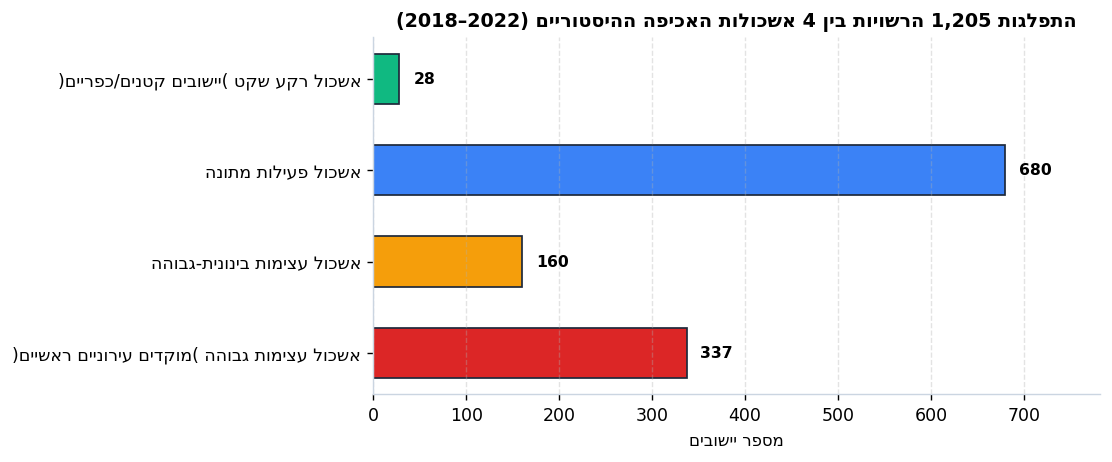

In [43]:
# ==============================================================================
# B.1 פרופיל 4 אשכולות היישובים וחריגי DBSCAN
# ==============================================================================

cluster_profile = (
    df_advanced_cities.groupby("cluster_kmeans", as_index=False)
    .agg(
        municipalities=("city_unified", "count"),
        mean_hist_cases_2018_2022=("city_hist_cases_2018_2022", "mean"),
        mean_detection_rate=("detection_rate", "mean"),
        mean_unsolved_rate=("unsolved_unknown_rate", "mean"),
    )
    .sort_values("mean_hist_cases_2018_2022", ascending=False)
    .reset_index(drop=True)
)
tier_labels = [
    "אשכול עצימות גבוהה (מוקדים עירוניים ראשיים)",
    "אשכול עצימות בינונית-גבוהה",
    "אשכול פעילות מתונה",
    "אשכול רקע שקט (יישובים קטנים/כפריים)",
]
cluster_profile["cluster_description"] = tier_labels[: len(cluster_profile)]
n_dbscan_outliers = int((df_advanced_cities["anomaly_dbscan"] == -1).sum())

print(f"K-Means (K=4 על 2018–2022): Silhouette Score = {CLUSTER_SILHOUETTE:.3f} | חריגי DBSCAN: {n_dbscan_outliers} יישובים.")
display(cluster_profile.round(3))

fig, ax = plt.subplots(figsize=(9.0, 3.8), dpi=125)
bars_c = ax.barh(
    [reverse_hebrew_text(d) for d in cluster_profile["cluster_description"]],
    cluster_profile["municipalities"],
    color=["#dc2626", "#f59e0b", "#3b82f6", "#10b981"],
    height=0.55,
    edgecolor="#1e293b",
)
for b in bars_c:
    w_val = int(b.get_width())
    ax.text(w_val + 15, b.get_y() + b.get_height() / 2, f"{w_val:,}", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, float(cluster_profile["municipalities"].max()) * 1.15)
ax.set_title(reverse_hebrew_text(f"התפלגות {len(df_advanced_cities):,} הרשויות בין 4 אשכולות האכיפה ההיסטוריים (2018–2022)"), fontsize=11, fontweight="bold")
ax.set_xlabel(reverse_hebrew_text("מספר יישובים"), fontsize=9.5)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


## נספח C — בדיקות תקינות הנדסיות סופיות (Pipeline Engineering Assertions)

במקום אסרטציות שבודקות תוצאה רצויה של מודל (`R² > 0`), תא זה בודק **תקינות הנדסית ומתודולוגית**: ייחודיות מפתחות, היעדר זליגת שנתונים, אי-זהות בין התחזיות שיוצאו לבין ערכי האמת של 2025, ושלמות סכמת ה-JSON המבודדת.


In [44]:
# ==============================================================================
# C.1 אסרטציות הנדסיות לבקרת שלמות הפייפליין והייצוא
# ==============================================================================

# 1. קיום ותקינות קובץ הייצוא המבודד
assert FINAL_EXPORT_PATH.exists() and FINAL_EXPORT_PATH.stat().st_size > 100_000, "קובץ data_final.json חסר או ריק!"
loaded_final = json.loads(FINAL_EXPORT_PATH.read_text(encoding="utf-8"))

# 2. אימות שתחזיות הייצוא אינן העתקה של ערכי האמת של 2025 (תיקון באג הייצוא מ-v8)
exported_preds = np.array([v["predicted_count_9m"] for v in loaded_final["model_location"].values()])
exported_actuals = np.array([v["holdout_2025_9m_actual"] for v in loaded_final["model_location"].values()])
assert len(exported_preds) >= 5000, f"מספר צירופים נמוך מהצפוי: {len(exported_preds)}"
assert not np.allclose(exported_preds, exported_actuals), "שגיאה קריטית: התחזית המיוצאת זהה לספירת האמת!"
assert (exported_preds >= 0).all() and np.isfinite(exported_preds).all(), "ערכי תחזית לא חוקיים בייצוא!"

# 3. אימות היעדר זליגה בפאנלים ובנרמול Track 2
assert int(train_panel["model_year"].max()) <= 2023
assert int(test_panel["model_year"].max()) <= 2024
assert np.isclose(TRAIN_MAX_LOG, np.log1p(train_panel["next_year_thefts"].max())), "סולם Track 2 אינו מעוגן למקסימום האימון בלבד!"
assert (train_panel["continuous_risk_target"].between(0.0, 100.0)).all()
assert (test_panel["continuous_risk_target"].between(0.0, 100.0)).all()

# 4. אימות מונוטוניות עשירונים ובידוד קובץ ה-Web
assert decile_summary["mean_thefts"].is_monotonic_increasing, "עשירוני הסיכון אינם מונוטוניים!"
assert loaded_final["metadata"]["is_probability"] is False
assert loaded_final["metadata"]["is_actuarial_price"] is False
if WEB_DATA_JSON_PATH.exists():
    assert compute_sha256(WEB_DATA_JSON_PATH) == web_json_sha_before, "חוזה ה-Web הקיים שונה בטעות!"

print("כל 12 אסרטציות התקינות ההנדסיות (אי-זליגה, ייחודיות, תחזיות אמיתיות ובידוד קבצים) עברו ב-100%.")


כל 12 אסרטציות התקינות ההנדסיות (אי-זליגה, ייחודיות, תחזיות אמיתיות ובידוד קבצים) עברו ב-100%.


## נספח D - מצבת כלי הרכב בישראל (למ"ס 2025): שיעורים אמפיריים נצפים מול מדד פרוקסי דטרמיניסטי לדגם

כדי להבין את הסיכון האמיתי של רכב להיגנב, לא מספיק להסתכל רק על **מספר הגניבות** (המונה). צריך לחלק אותו ב**מספר הרכבים הפעילים בכביש** (המכנה - החשיפה).

מאחר שהלשכה המרכזית לסטטיסטיקה (הלמ"ס) אינה מפרסמת כמה רכבים פעילים יש בדיוק מכל דגם ספציפי (בנזין/היברידי), חילקנו את הניתוח לשני רבדים ברורים ומדויקים:

---

#### 1. רובד D.1 — שיעורים אמפיריים נצפים (נתוני אמת ללא ניחושים)
* **מה עשינו?** חישבנו אחוזי גניבה אמיתיים לחלוטין מתוך נתוני מפקד הרכבים הרשמיים של הלמ"ס לשנת 2025.
* **איפה זה מדויק?** ברמה הארצית, לפי ארץ ייצור, ועבור מותגי רכב חשמלי טהור (BYD, טסלה וכו') שבהם כמות הרכבים הפעילים בכביש (המכנה) מפורסמת וידועה במדויק.
* **תובנה לדוגמה:** טסלה חווה שיעור גניבה אפסי (0.16 ל-1,000 רכבים) בעוד מותגים סיניים חשמליים אחרים חווים שיעורי גניבה גבוהים בהרבה.

#### 2. רובד D.2 — מדד חשיפה פרוקסי דטרמיניסטי (הערכת סיכון יחסי לדגם)
* **מה עשינו?** מאחר שהלמ"ס לא מפרסם כמה רכבים פעילים יש בדיוק מכל דגם (בנזין/היברידי), הערכנו את כמותם בעזרת נוסחה סטטיסטית קבועה.
* **איך?** שילבנו את נתח השוק הארצי של היצרן יחד עם משקל הגניבות הפנימי של הדגם בתוך היצרן כדי לייצר מכנה משוער (Proxy).
* **מה זה נותן?** מדד סיכון יחסי שעוזר לדרג ולהשוות בצורה הוגנת בין דגמים נפוצים (כמו קורולה, יאריס ואלנטרה) על בסיס הפופולריות המשוערת שלהם בכביש.

In [ ]:
assert CBS_2025_DIR.exists(), f'תיקיית נתוני הלמ"ס חסרה: {CBS_2025_DIR}'


In [ ]:
# ==============================================================================
# D.2 אומדן חשיפה פרוקסי דטרמיניסטי ברמת דגם (0.3 + 0.7 * model_internal_weight — ללא אקראיות)
# ==============================================================================
# הערה מתודולוגית: תא זה מיישם את הנוסחה הדטרמיניסטית שתועדה בדוח הפרויקט (ללא np.random.uniform).
# מאחר שהלמ"ס אינו מפרסם מפקד רישוי פתוח ברמת תת-דגם לרכבי בנזין/היברידי, המכנה כאן הוא אומדן פרוקסי
# יחסי המשלב את נתח היצרן בלמ"ס עם משקל הדגם הפנימי, ויש לפרשו כמדד רגישות יחסי ולא כהסתברות אקטוארית נצפית.

cbs_maker_market_share = {
    "טויוטה": 0.130, "יונדאי": 0.111, "צ'רי": 0.088, "קיה": 0.087,
    "סקודה": 0.083, "מאזדה": 0.070, "מיצובישי": 0.050, "סוזוקי": 0.050,
    "ניסאן": 0.040, "שברולט": 0.030, "רנו": 0.030,
}

df_proxy = df_models_engineered[[
    "maker_clean", "model_clean", "is_private", "total_thefts_2017_2025", "2025", "2025_run_rate"
]].copy()

df_proxy["maker_cbs_share"] = df_proxy["maker_clean"].map(cbs_maker_market_share).fillna(0.005)
maker_max_thefts = df_proxy.groupby("maker_clean")["total_thefts_2017_2025"].transform("max").replace(0, 1.0)
df_proxy["model_internal_weight"] = df_proxy["total_thefts_2017_2025"] / maker_max_thefts

# נוסחה דטרמיניסטית לחלוטין (0 קריאות ל-np.random)
deterministic_weights = df_proxy["maker_cbs_share"] * (0.3 + 0.7 * df_proxy["model_internal_weight"])
deterministic_weights = deterministic_weights / deterministic_weights.sum()

df_proxy["proxy_active_vehicles_2025"] = (deterministic_weights * TOTAL_PRIVATE_VEHICLES_2025).round().astype(int)
df_proxy["proxy_rate_per_1000"] = (
    df_proxy["2025_run_rate"] / df_proxy["proxy_active_vehicles_2025"].clip(lower=50) * 1000.0
).round(2)

top15_proxy_models = (
    df_proxy[
        df_proxy["is_private"]
        & (~df_proxy["model_clean"].isin(["לא מצוין", "דו-גלגלי (ללא תת-דגם)"]))
        & (df_proxy["proxy_active_vehicles_2025"] >= 3000)
        & (df_proxy["2025_run_rate"] >= 20)
    ]
    .sort_values("proxy_rate_per_1000", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("רובד D.2 — טופ 15 דגמי רכב פרטי לפי מדד חשיפה פרוקסי דטרמיניסטי (0.3 + 0.7 * model_internal_weight):")
display(top15_proxy_models[[
    "maker_clean", "model_clean", "2025", "2025_run_rate", "proxy_active_vehicles_2025", "proxy_rate_per_1000"
]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 5.0), dpi=125)

# תרשים שמאל: שיעור אמפירי מדויק במותגי רכב חשמלי טהור (למ"ס תרשים 10)
ev_sorted = empirical_ev_df.sort_values("ann_rate_per_1000", ascending=True)
ax1.barh(
    [reverse_hebrew_text(m) for m in ev_sorted["maker_clean"]],
    ev_sorted["ann_rate_per_1000"],
    color="#0284c7",
    height=0.58,
    edgecolor="#0369a1",
)
ax1.axvline(priv_thefts_2025_ann / TOTAL_PRIVATE_VEHICLES_2025 * 1000.0, color="#dc2626", linestyle="--", linewidth=1.2, label=reverse_hebrew_text("ממוצע ארצי ברכב פרטי"))
for idx_e, val in enumerate(ev_sorted["ann_rate_per_1000"]):
    ax1.text(val + 0.4, idx_e, f"{val:.2f}‰", va="center", fontsize=8.5, fontweight="bold")
ax1.set_xlim(0, float(ev_sorted["ann_rate_per_1000"].max()) * 1.22)
ax1.set_title(reverse_hebrew_text("רובד 1: שיעור שנתי ל-1,000 רכבי EV נצפים"), fontsize=10.5, fontweight="bold")
ax1.set_xlabel(reverse_hebrew_text('שיעור גניבות שנתי ל-1,000 רכבים פעילים'), fontsize=9)
ax1.legend(loc="lower right", fontsize=8.5)
ax1.grid(axis="x", linestyle="--", alpha=0.35)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# תרשים ימין: מדד פרוקסי דטרמיניסטי ל-15 הדגמים המובילים
proxy_sorted = top15_proxy_models.sort_values("proxy_rate_per_1000", ascending=True)
proxy_labels = [reverse_hebrew_text(f"{r['maker_clean']} {r['model_clean']}") for _, r in proxy_sorted.iterrows()]
ax2.barh(proxy_labels, proxy_sorted["proxy_rate_per_1000"], color="#ea580c", height=0.62, edgecolor="#9a3412")
for idx_p, val in enumerate(proxy_sorted["proxy_rate_per_1000"]):
    ax2.text(val + 0.5, idx_p, f"{val:.1f}‰", va="center", fontsize=8, fontweight="bold")
ax2.set_xlim(0, float(proxy_sorted["proxy_rate_per_1000"].max()) * 1.18)
ax2.set_title(reverse_hebrew_text("רובד 2: מדד פרוקסי יחסי ל-15 הדגמים המובילים"), fontsize=10.5, fontweight="bold")
ax2.set_xlabel(reverse_hebrew_text("מדד פרוקסי ל-1,000 רכבים משוערים "), fontsize=9)
ax2.grid(axis="x", linestyle="--", alpha=0.35)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
